# Phonocardiogram signal analysis

Exploratory pipeline that locates the first and second heart sounds (B1, B2) in digital auscultation recordings and compares signal energy across the phases of the cardiac cycle. See the repository README for scope and limitations.

## Introduction

Each stereo WAV recording is converted to a complex signal, band-pass filtered, and turned into a smoothed short-time energy trace. Peaks of this trace are taken as heart sounds. The mean squared energy is then computed in four phases of the cardiac cycle (B2, diastole, B1, systole), first for one example recording and then for every recording.

## Contents

1. Signal display
2. Frequency representation
3. Filtering and denoising
4. Short-time energy
5. Smoothing and peak detection
6. Distances between peaks
7. B1 and B2 identification
8. B1 and B2 points with error margins
9. Mean squared energy per cardiac phase
10. All recordings

## Libraries

In [1]:
# Matplotlib: plotting.
import matplotlib.pyplot as plt

# NumPy: numerical computing and array manipulation.
import numpy as np

# SciPy: WAV file input/output.
import scipy.io.wavfile as wav

# WAV file handling.
import wave

# Spectrogram computation.
from scipy.signal import spectrogram

# Kaiser window.
from scipy.signal.windows import kaiser

# Resampling.
from scipy.signal import resample

# Digital filter design and application.
from scipy.signal import butter, filtfilt

# Hamming window.
from scipy.signal.windows import hamming

# Peak detection.
from scipy.signal import find_peaks

# Operating-system interface.
import os

# Mathematical functions.
import math

## 1. Signal display

Load a WAV file and plot its amplitude against time. Stereo signals are combined into a complex signal.

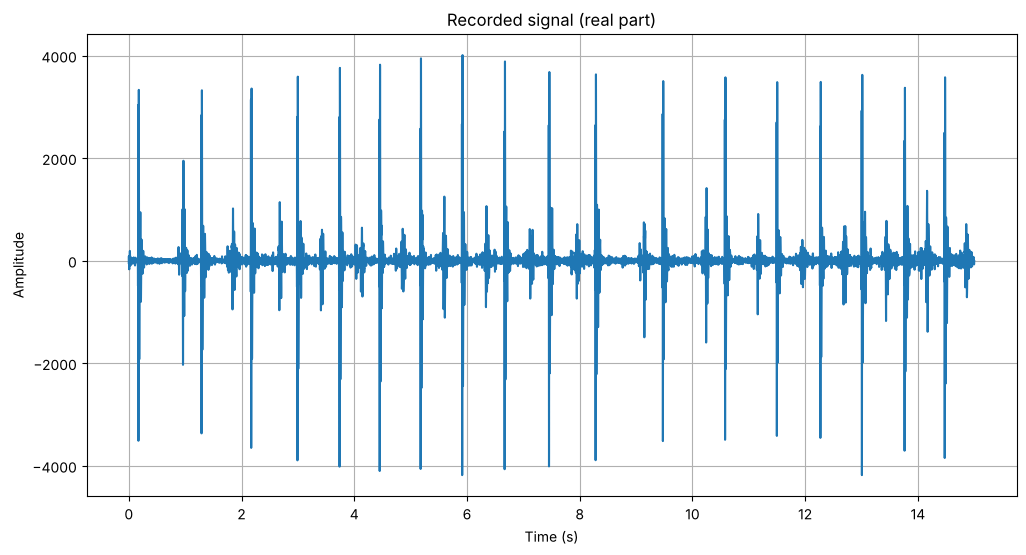

In [2]:
# Path of the WAV file
filename = '../data/recordings/Eko Recording Sound Export ad apex 1.wav'

# Load the WAV file
with wave.open(filename, 'rb') as wave_file:
    # Get the audio file information
    framerate = wave_file.getframerate()
    frames = wave_file.getnframes()
    channels = wave_file.getnchannels()
    width = wave_file.getsampwidth()

    # Read the audio data
    audio_data = wave_file.readframes(frames)

    # Convert the audio data to a NumPy array
    audio_data = np.frombuffer(audio_data, dtype=np.int16)

    # Signal duration in seconds
    duration = frames / float(framerate)

    # Time vector
    time = np.linspace(0, duration, frames)
    
    
# Load the WAV file
Fs, y = wav.read(filename)

# Check whether the file is stereo or mono (some recordings have two channels)
if len(y.shape) == 1:  # Mono
    X = y
elif len(y.shape) == 2:  # Stereo
    X = y[:, 0] - 1j * y[:, 1]  # Combine the channels into a complex signal

Nmax = len(X)
TotalDuration = Nmax / Fs

# Plot the signal
plt.figure(figsize=(12, 6))
plt.plot(np.linspace(0, TotalDuration, Nmax), X)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Recorded signal (real part)')
plt.grid(True)
plt.show()

## 2. Frequency representation

Take one frame of the signal, compute its magnitude spectrum with the Fourier transform, and plot it together with the spectrogram.

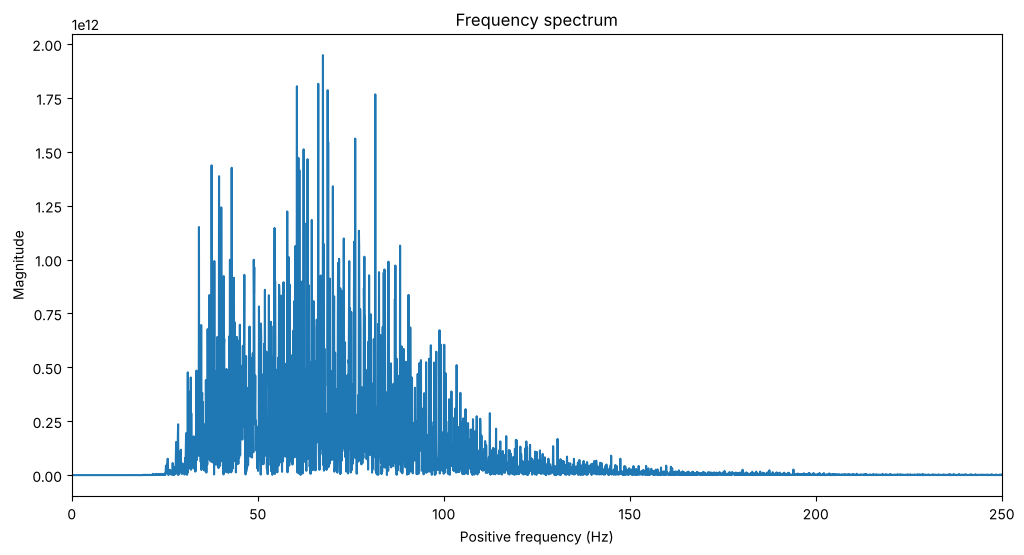

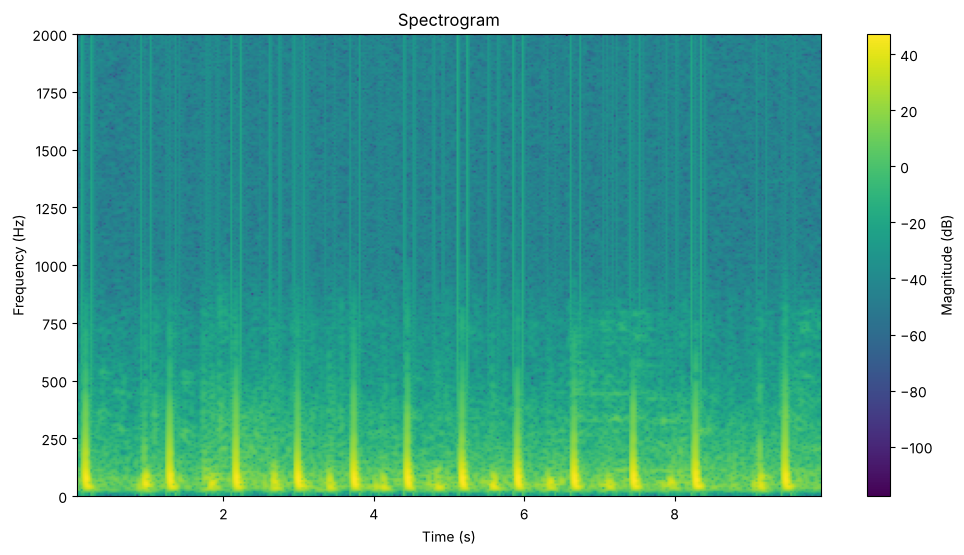

In [3]:
Overlap = 80 / 100
Lwind = 512
Delay = round(Lwind - (Lwind * Overlap))
ED = 10  # Frame duration
NObs = int(ED * Fs)
k = 1
x = X[(k - 1) * NObs:k * NObs]
tx = np.linspace(0, ED, len(x))

# Frequency representation
X = np.fft.fft(audio_data - np.mean(audio_data))
Xspec_fp = np.abs(X[:len(X) // 2]) ** 2
fp = np.linspace(0, framerate / 2, len(Xspec_fp))

plt.figure(figsize=(12, 6))
plt.plot(fp, Xspec_fp)
plt.xlabel('Positive frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Frequency spectrum')
plt.xlim([0, 250])  # Limit the frequency range for readability
plt.show()



# Plot the spectrogram
plt.figure(figsize=(12, 6))
plt.specgram(x, NFFT=512  , Fs=Fs, window=kaiser(512, 5),  noverlap=round(512 * Overlap))
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (s)')
plt.colorbar(label='Magnitude (dB)')
plt.title('Spectrogram')
plt.show()

## 3. Filtering and denoising

The signal is normalised by its maximum absolute value, then filtered with a Butterworth band-pass filter (cut-off frequencies set below). The original and filtered signals are compared.

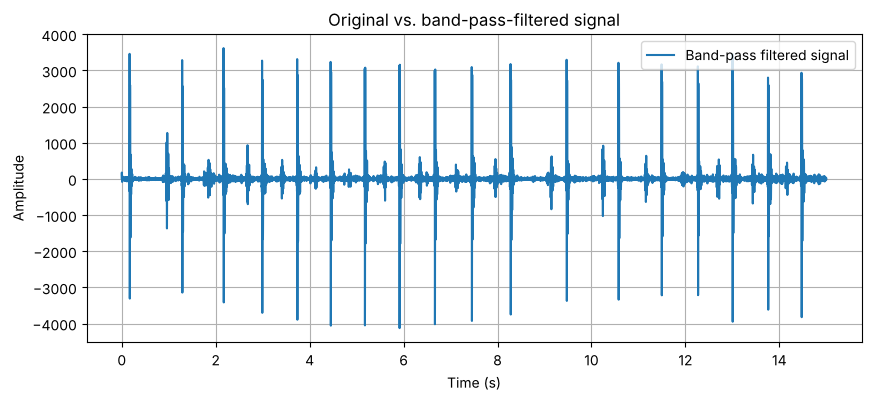

In [4]:
# Normalisation (divide by the maximum absolute value)
normalized_audio_data = audio_data / np.max(np.abs(audio_data))

# Butterworth band-pass filter design
def butter_bandpass(lowcut, highcut, fs, order=5):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band', analog=False)
    return b, a

# Apply the Butterworth band-pass filter to the audio signal
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = filtfilt(b, a, data)
    return y

# Band-pass cut-off frequencies
lowcut_frequency = 50  # Low cut-off frequency (Hz)
highcut_frequency = 1000  # High cut-off frequency (Hz)

# Apply the band-pass filter to the audio signal
filtered_audio_data_bandpass = butter_bandpass_filter(audio_data, lowcut_frequency, highcut_frequency, framerate)
# Denoising (e.g. simple thresholding)
#threshold = 100  # Noise-detection threshold
#denoised_audio_data = np.where(np.abs(audio_data) > threshold, audio_data, 0)
# Plot the original and band-pass-filtered signals
plt.figure(figsize=(10, 4))
plt.plot(time, filtered_audio_data_bandpass, label='Band-pass filtered signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Original vs. band-pass-filtered signal')
plt.legend()
plt.grid(True)
plt.show()

## 4. Short-time energy

Per-frame energy of the band-pass-filtered signal, computed with a shorter Hamming window, a longer FFT and less overlap than in a first attempt, for a better time and frequency resolution.

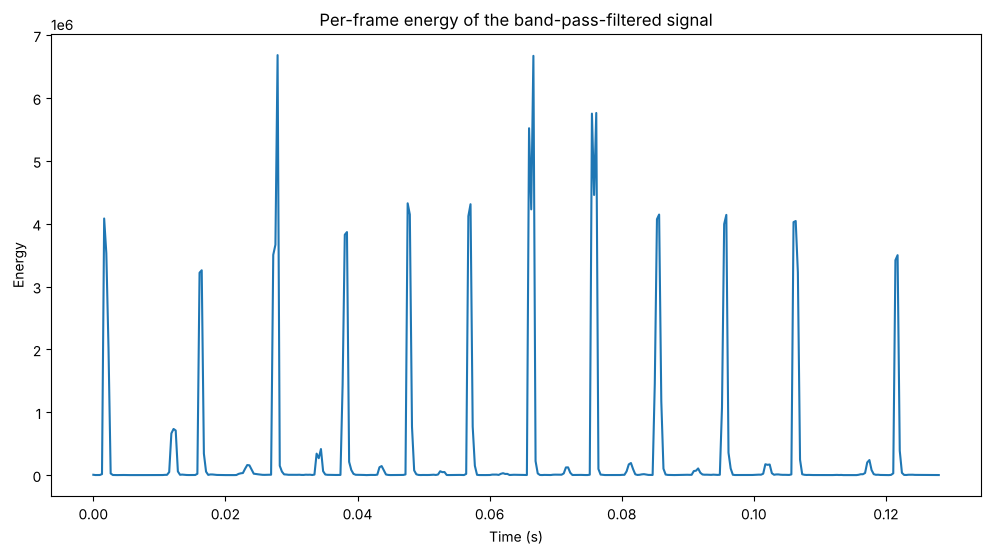

In [5]:
frame_duration = Lwind / Fs


# Shorter Hamming window
Lwind = 128  # e.g. reduce the Hamming window length to 128

# Longer FFT
NFFT = 2048  # e.g. increase the FFT length to 2048

# Lower overlap
Overlap = 50 / 100  # e.g. reduce the overlap to 50 %

# Plot the per-frame energy with the new settings
Energy = []

l = 1

while (l - 1) * Delay + Lwind < NObs:
    x_wind = filtered_audio_data_bandpass[(l - 1) * Delay:l * Delay + Lwind]
    S = np.abs(np.fft.fft(x_wind, NFFT))
    FrpPos = np.arange(len(S) // 2)
    Energy.append([np.sum((S[FrpPos] * hamming(len(FrpPos))) ** 2) / len(FrpPos)])
    l += 1

Energy = np.array(Energy)
Sgl = Energy[:, 0]
tx = np.linspace(0, frame_duration, len(Sgl))

# Plot the per-frame energy with the new settings
plt.figure(figsize=(12, 6))
plt.plot(tx, Sgl)
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Per-frame energy of the band-pass-filtered signal')
plt.show()


## 5. Smoothing and peak detection

The time axis is rebuilt from the frame step, and a low-pass Butterworth filter smooths the energy trace. Peaks are then detected with parameters set adaptively: the height from the second largest peak, the prominence from the interquartile range.

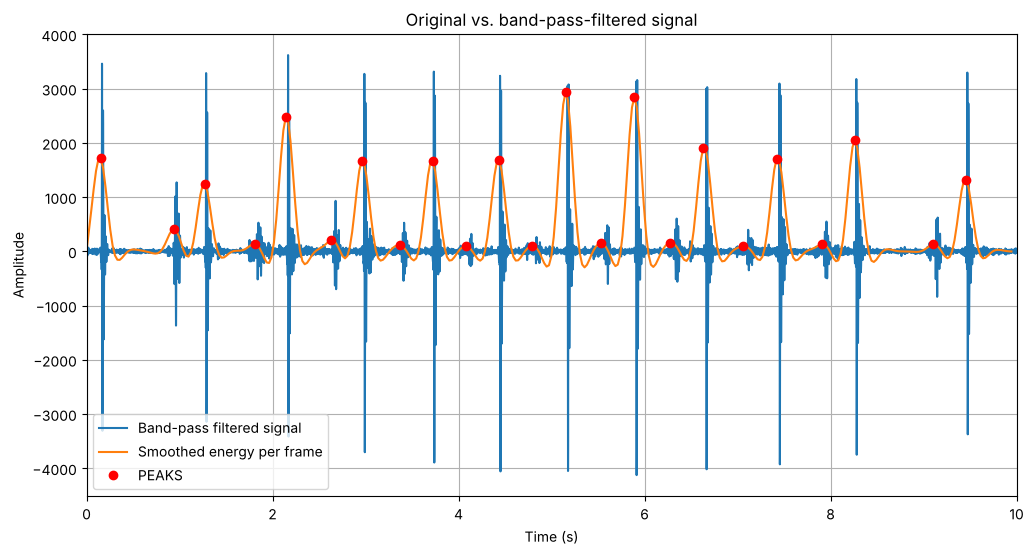

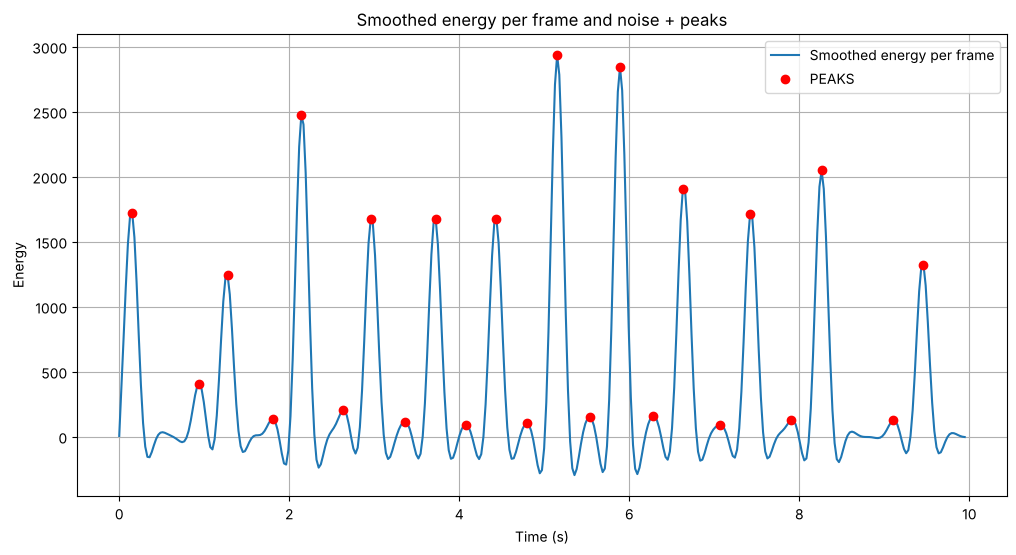

In [6]:
# Correct the time axis
epoch_times = np.arange(len(Sgl)) * (Delay / Fs)

# Low-pass filter parameters
order = 3  # Filter order
cutoff_freq = 0.09  # Filter cut-off frequency (Hz)

# Design the low-pass filter
b, a = butter(order, cutoff_freq, fs=1)

# Low-pass filter the per-frame energy to smooth it
smoothed_energy = filtfilt(b, a, Sgl)

# Find all initial peaks to inspect their amplitudes
initial_peaks, _ = find_peaks(smoothed_energy)

# If at least two peaks are found
if len(initial_peaks) > 1:
    # Get the values of the peaks found
    peak_values = smoothed_energy[initial_peaks]
    # Index of the largest peak
    max_peak_index = np.argmax(peak_values)
    # Remove the largest peak to get the second largest
    peak_values = np.delete(peak_values, max_peak_index)
    # Value of the second largest peak
    second_max_peak = np.max(peak_values)
else:
    # With fewer than two peaks, use the existing maximum to avoid errors
    second_max_peak = np.max(smoothed_energy)

# Set height as a fraction of the second largest peak
height_threshold = second_max_peak / 50

# Set the other parameters adaptively
distance = len(smoothed_energy) // 50  # This factor can be tuned for the signal
prominence = (np.percentile(smoothed_energy, 50) - np.percentile(smoothed_energy, 25))  # Use the IQR as an estimate of prominence
width = 5  # Minimum width (can be tuned)

# Find peaks with the computed parameters
peaks, properties = find_peaks(smoothed_energy, distance=distance, height=height_threshold, prominence=prominence, width=width)

# Plot the smoothed signal, the noise and the peaks
plt.figure(figsize=(12, 6))
plt.plot(time, filtered_audio_data_bandpass, label='Band-pass filtered signal')
plt.xlim([0,10])
plt.plot(epoch_times, smoothed_energy/1000, label='Smoothed energy per frame')
plt.plot(epoch_times[peaks], smoothed_energy[peaks]/1000,'ro',  label='PEAKS')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Original vs. band-pass-filtered signal')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))
plt.plot(epoch_times, smoothed_energy/1000, label='Smoothed energy per frame')
plt.plot(epoch_times[peaks], smoothed_energy[peaks]/1000,'ro',  label='PEAKS')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame and noise + peaks')
plt.legend()
plt.grid(True)

plt.show()

## 6. Distances between peaks

Time distances between consecutive peaks are computed. The smallest distance identifies the peak pair used to start the B1 / B2 assignment.

Between 1 & 2 : 0.79 seconds
Between 2 & 3 : 0.33 seconds
Between 3 & 4 : 0.54 seconds
Between 4 & 5 : 0.33 seconds
Between 5 & 6 : 0.48 seconds
Between 6 & 7 : 0.33 seconds
Between 7 & 8 : 0.41 seconds
Between 8 & 9 : 0.36 seconds
Between 9 & 10 : 0.36 seconds
Between 10 & 11 : 0.36 seconds
Between 11 & 12 : 0.36 seconds
Between 12 & 13 : 0.36 seconds
Between 13 & 14 : 0.38 seconds
Between 14 & 15 : 0.36 seconds
Between 15 & 16 : 0.38 seconds
Between 16 & 17 : 0.36 seconds
Between 17 & 18 : 0.43 seconds
Between 18 & 19 : 0.36 seconds
Between 19 & 20 : 0.48 seconds
Between 20 & 21 : 0.36 seconds
Between 21 & 22 : 0.84 seconds
Between 22 & 23 : 0.36 seconds


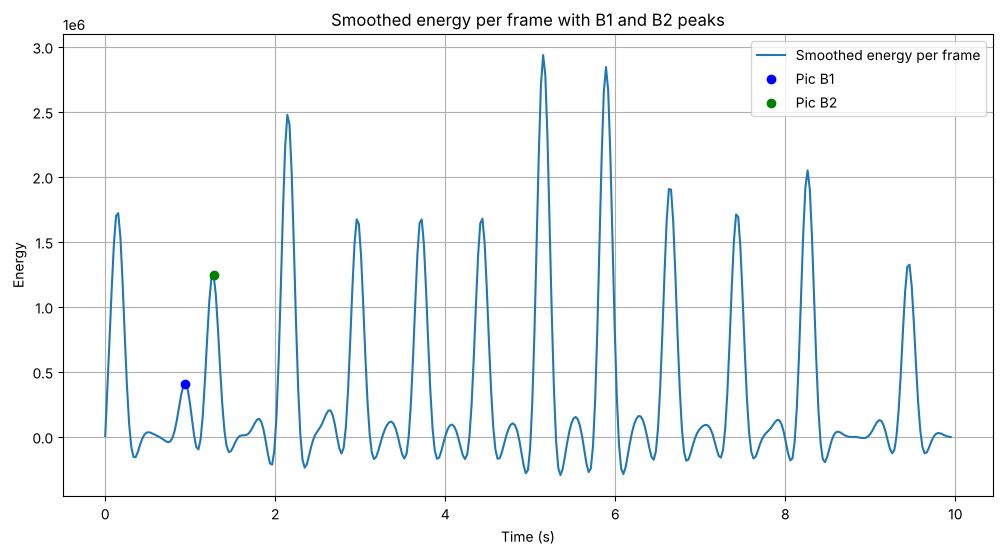

B2 peak index: 50
B1 peak index: 37


In [7]:
distances = []


# Time distances between peaks
for i in range(len(peaks) - 1):
    distance_time = epoch_times[peaks[i+1]] - epoch_times[peaks[i]]
    print(f"Between {i+1} & {i+2} : {distance_time:.2f} seconds")
    distances.append(distance_time)

# Smallest distance
distance_min = min(distances)

# Indices of the peaks corresponding to the smallest distance
min_distance_index = distances.index(distance_min)
peak_B1_index = peaks[min_distance_index]
peak_B2_index = peaks[min_distance_index + 1]

# Plot the smoothed signal with the B1 and B2 peaks
plt.figure(figsize=(12, 6))
plt.plot(epoch_times, smoothed_energy, label='Smoothed energy per frame')

# Mark the B1 and B2 peaks
plt.plot(epoch_times[peak_B1_index], smoothed_energy[peak_B1_index], 'bo', label='Pic B1')
plt.plot(epoch_times[peak_B2_index], smoothed_energy[peak_B2_index], 'go', label='Pic B2')

plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame with B1 and B2 peaks')
plt.legend()
plt.grid(True)
plt.show()

print("B2 peak index:", peak_B2_index)
print("B1 peak index:",peak_B1_index)


## 7. B1 and B2 identification

The detected peaks are split into two alternating series by index parity, one for B2 and one for B1. This assumes that no peak is missed or spurious.

B1 peaks: [37, 71, 103, 132, 160, 188, 217, 246, 277, 310, 357]
B2 peaks: [6, 50, 84, 116, 146, 174, 202, 231, 260, 291, 324, 371]


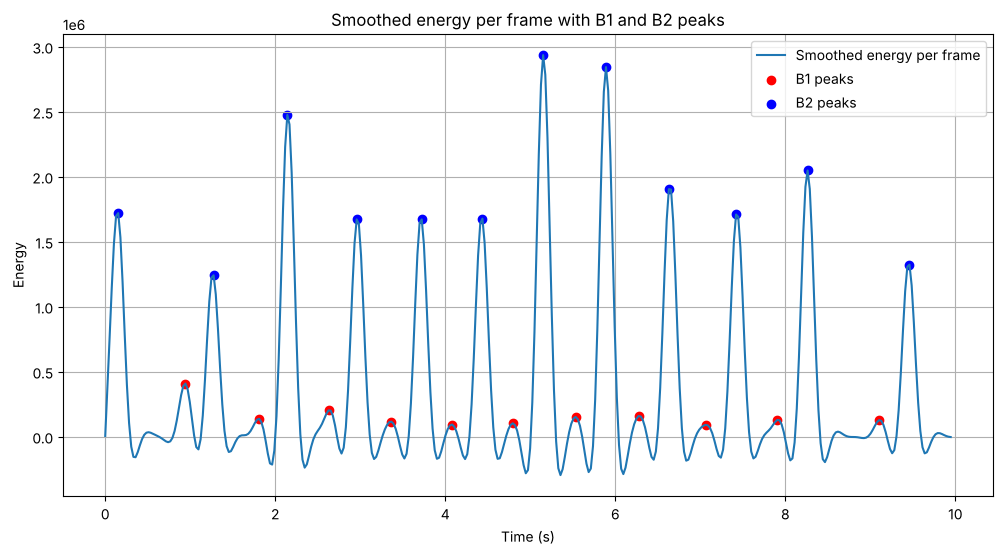

In [8]:
# Lists for the B1 and B2 peaks
peaks_B1 = []
peaks_B2 = []

# Iterate over the peak indices
for i in range(1, len(peaks)):
    if i % 2 == 0:
        # Even index: add to the B2 list
        peaks_B2.append(peaks[i])
    else:
        # Odd index: add to the B1 list
        peaks_B1.append(peaks[i])

# Check whether the second peak overall equals the first B1 or B2 peak

if peaks[1] == peaks_B1[0]:

    peaks_B2.append(peaks[0])

elif peaks[1] == peaks_B2[0]:

    peaks_B1.append(peaks[0])
# Sort the B1 and B2 lists in increasing order
peaks_B1.sort()
peaks_B2.sort()

# Print the B1 and B2 lists
print("B1 peaks:", peaks_B1)
print("B2 peaks:", peaks_B2)

# Plot the smoothed signal with the B1 and B2 peaks
plt.figure(figsize=(12, 6))

# Plot the smoothed energy signal
plt.plot(epoch_times, smoothed_energy, label='Smoothed energy per frame')

# Plot the B1 peaks
plt.scatter(epoch_times[peaks_B1], smoothed_energy[peaks_B1], color='red', label='B1 peaks')

# Plot the B2 peaks
plt.scatter(epoch_times[peaks_B2], smoothed_energy[peaks_B2], color='blue', label='B2 peaks')

plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame with B1 and B2 peaks')
plt.legend()
plt.grid(True)
plt.show()


## 8. B1 and B2 points with error margins

Each B1 and B2 peak is given an error margin, and consecutive indices are grouped.

In [9]:
distances_B1 = []

# Distances between consecutive B1 peaks
for i in range(len(peaks_B1) - 1):
    distance_B1 = epoch_times[peaks_B1[i+1]] - epoch_times[peaks_B1[i]]
    distances_B1.append(distance_B1)

# Mean distance
mean_distance_B1 = sum(distances_B1) / len(distances_B1)

# 10 % of the mean gives the threshold
error_margin = int(mean_distance_B1 * 0.10)+1# Define the error margin


# Store the B1 points with error margins
points_B1 = []
for peak_B1 in peaks_B1:
    points_B1.extend(range(peak_B1 - error_margin, peak_B1 + error_margin + 1))

# Store the B2 points with the threshold
points_B2 = []
for peak_B2 in peaks_B2:
    points_B2.extend(range(peak_B2 - error_margin, peak_B2 + error_margin + 1))

# Sort and remove duplicates
points_B1 = sorted(set(points_B1))
points_B2 = sorted(set(points_B2))

# Group consecutive indices
def group_consecutive_indices(indices):
    groups = []
    temp_group = [indices[0]]
    for i in range(1, len(indices)):
        if indices[i] - indices[i-1] == 1:
            temp_group.append(indices[i])
        else:
            groups.append(temp_group)
            temp_group = [indices[i]]
    groups.append(temp_group)
    return groups

# Store the B1 points with margins and the number of positions they cover
points_B1_groups = group_consecutive_indices(points_B1)
# Store the B2 points with margins and the number of positions they cover
points_B2_groups = group_consecutive_indices(points_B2)

# Print the B1 and B2 points with margins and number of positions
print("B1 points with error margins (and number of positions):", points_B1_groups)
print("B2 points with error margins (and number of positions):", points_B2_groups)



B1 points with error margins (and number of positions): [[36, 37, 38], [70, 71, 72], [102, 103, 104], [131, 132, 133], [159, 160, 161], [187, 188, 189], [216, 217, 218], [245, 246, 247], [276, 277, 278], [309, 310, 311], [356, 357, 358]]
B2 points with error margins (and number of positions): [[5, 6, 7], [49, 50, 51], [83, 84, 85], [115, 116, 117], [145, 146, 147], [173, 174, 175], [201, 202, 203], [230, 231, 232], [259, 260, 261], [290, 291, 292], [323, 324, 325], [370, 371, 372]]


Smoothed energy with the B1 and B2 peaks and their margins.

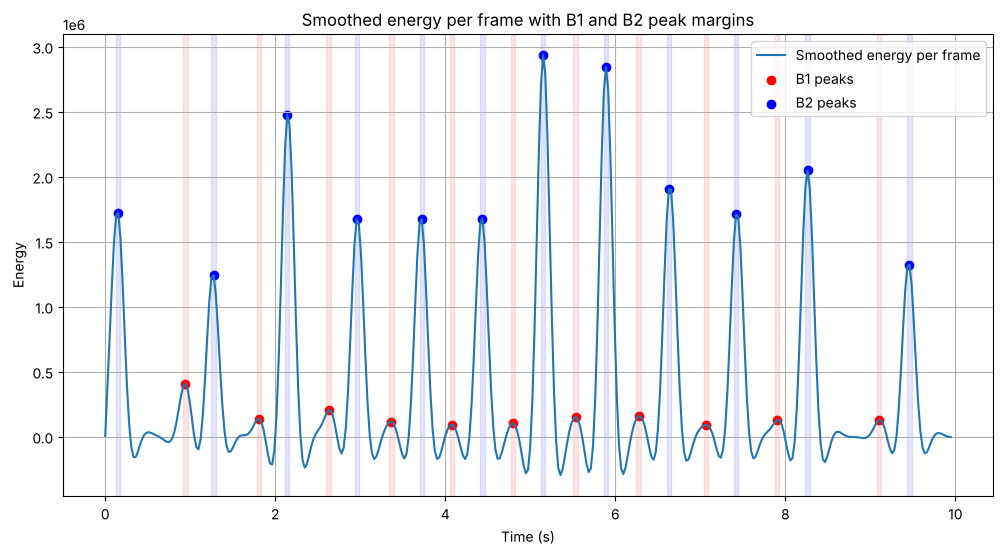

In [10]:
# Plot the smoothed signal with the B1 and B2 peaks and their margins
plt.figure(figsize=(12, 6))

# Plot the smoothed energy signal
plt.plot(epoch_times, smoothed_energy, label='Smoothed energy per frame')

# Plot the B1 margins
for group in points_B1_groups:
    first_point = group[0]
    last_point = group[-1]
    plt.axvspan(epoch_times[first_point], epoch_times[last_point], color='red', alpha=0.1)

# Plot the B2 margins
for group in points_B2_groups:
    first_point = group[0]
    last_point = group[-1]
    plt.axvspan(epoch_times[first_point], epoch_times[last_point], color='blue', alpha=0.1)
# Plot the B1 peaks
plt.scatter(epoch_times[peaks_B1], smoothed_energy[peaks_B1], color='red', label='B1 peaks')

# Plot the B2 peaks
plt.scatter(epoch_times[peaks_B2], smoothed_energy[peaks_B2], color='blue', label='B2 peaks')
plt.xlabel('Time (s)')
plt.ylabel('Energy')
plt.title('Smoothed energy per frame with B1 and B2 peak margins')
plt.legend()
plt.grid(True)

plt.show()

## 9. Mean squared energy per cardiac phase

For each cardiac cycle, the mean squared value of the energy trace is computed in four segments: B2 group, diastole, B1 group and systole. The first cycle is dropped before plotting.

In [11]:
# Initialise the lists of mean values
B2 = []
diastole = []
B1 = []
systole = []

# Iterate over the B1 and B2 groups
for i in range(len(points_B1_groups)):
    # Start and end indices of each B1 and B2 group
    start_B1 = points_B1_groups[i][0]
    end_B1 = points_B1_groups[i][-1]
    start_B2 = points_B2_groups[i][0]
    end_B2 = points_B2_groups[i][-1]
    
    # Mean of the squared values in each segment
    mean_squared_B2 = np.mean(filtered_audio_data_bandpass[start_B2:end_B2+1] ** 2)
    mean_squared_diastole = np.mean(filtered_audio_data_bandpass[end_B2+1:start_B1] ** 2)
    mean_squared_B1 = np.mean(filtered_audio_data_bandpass[start_B1:end_B1+1] ** 2)
    
    # Check that this is not the last iteration
    if i != len(points_B1_groups) - 1:
        mean_squared_systole = np.mean(filtered_audio_data_bandpass[end_B1+1:points_B1_groups[i+1][0]] ** 2)
    else:
        # For the last iteration, set mean_squared_systole to 0
        mean_squared_systole = 0
    
         
        
    # Append the mean values to the lists
    B2.append(mean_squared_B2)
    diastole.append(mean_squared_diastole)
    B1.append(mean_squared_B1)
    systole.append(mean_squared_systole)
    

        
    # Print the mean values
    print("B2 group - mean squared value:", mean_squared_B2)
    print("Diastole - mean squared value:", mean_squared_diastole)
    print("B1 group - mean squared value:", mean_squared_B1)
    print("Systole - mean squared value:", mean_squared_systole)

# Drop the first element of each list
del B2[0]
del diastole[0]
del B1[0]
del systole[0]

B2 group - mean squared value: 28583.94006326956
Diastole - mean squared value: 4818.862943332931
B1 group - mean squared value: 2635.867389831284
Systole - mean squared value: 753.4500434630754
B2 group - mean squared value: 159.8298503838204
Diastole - mean squared value: 670.3471362908624
B1 group - mean squared value: 2477.6755259654055
Systole - mean squared value: 1747.9249472280796
B2 group - mean squared value: 200.88086522859987
Diastole - mean squared value: 1104.7795256202198
B1 group - mean squared value: 778.0333996816943
Systole - mean squared value: 233.08678442101484
B2 group - mean squared value: 39.22835901666103
Diastole - mean squared value: 50.2334595415826
B1 group - mean squared value: 578.8981784719741
Systole - mean squared value: 473.06618915816506
B2 group - mean squared value: 100.3437394612318
Diastole - mean squared value: 403.59727103002456
B1 group - mean squared value: 340.033812689421
Systole - mean squared value: 210.33455572663442
B2 group - mean squ

Bar charts of the mean squared values of each phase.

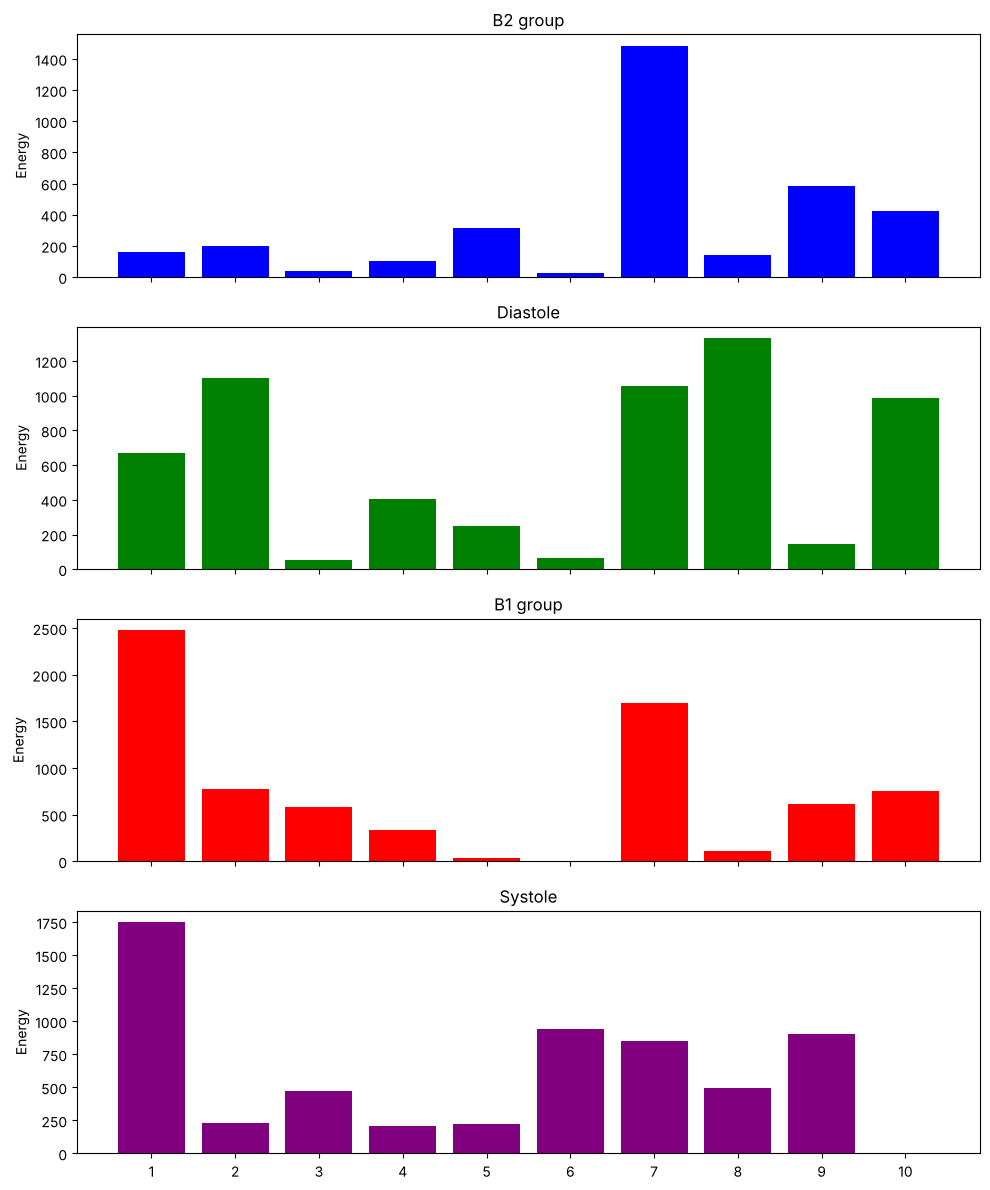

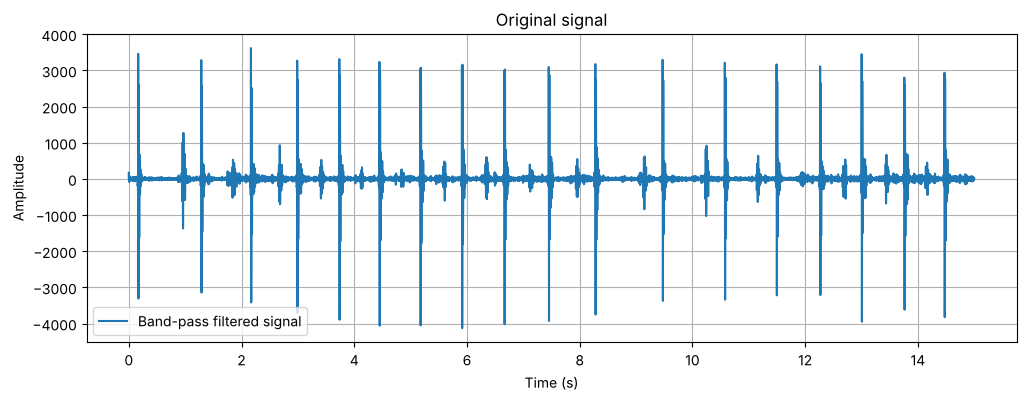

In [12]:
# Segment names
segments = ['B2 group', 'Diastole', 'B1 group', 'Systole']

# Mean values of each segment
mean_squared_values = [B2, diastole, B1, systole]

# Colours of each segment
colors = ['blue', 'green', 'red', 'purple']

# Create the figure and subplots
fig, axs = plt.subplots(4, figsize=(10, 12), sharex=True)

# Iterate over the segments to build the plots
for i in range(4):
    axs[i].bar(range(len(mean_squared_values[i])), mean_squared_values[i], color=colors[i])
    axs[i].set_ylabel('Energy')
    axs[i].set_title(segments[i])

# Show the segment names on the x-axis of the last plot
axs[3].set_xticks(range(len(mean_squared_values[0])))
axs[3].set_xticklabels(range(1, len(mean_squared_values[0])+1))

# Show the plots
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(time, filtered_audio_data_bandpass, label='Band-pass filtered signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title('Original signal')
plt.legend()
plt.grid(True)
plt.show()

## 10. All recordings

The same steps are repeated for every WAV file in `data/recordings/`: band-pass filtering, per-frame energy, peak detection, B1 / B2 identification and per-phase mean squared values. The first cycle of each recording is dropped because it is often erroneous.

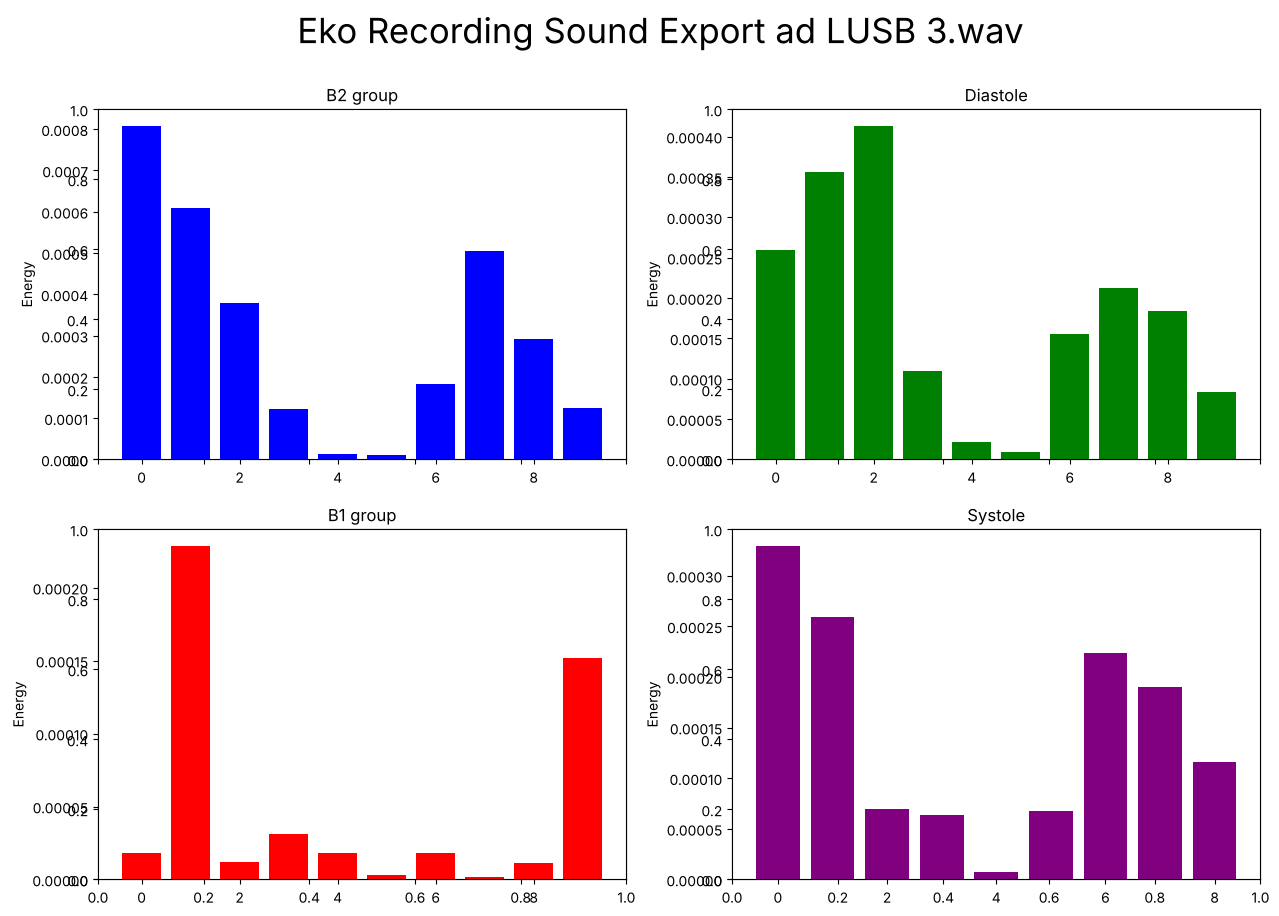

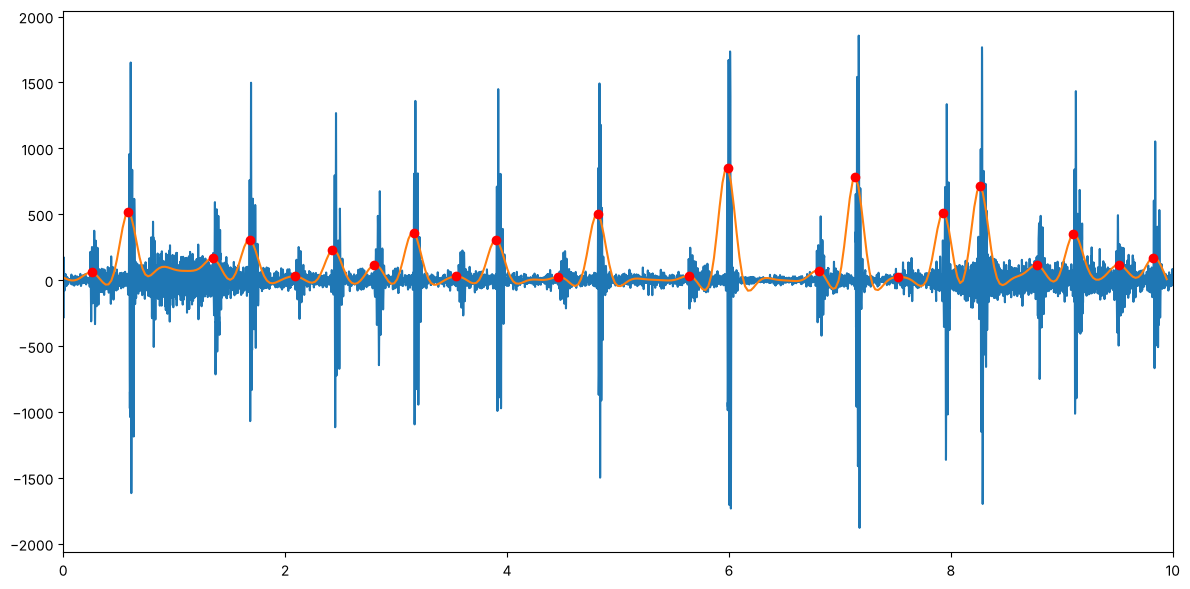

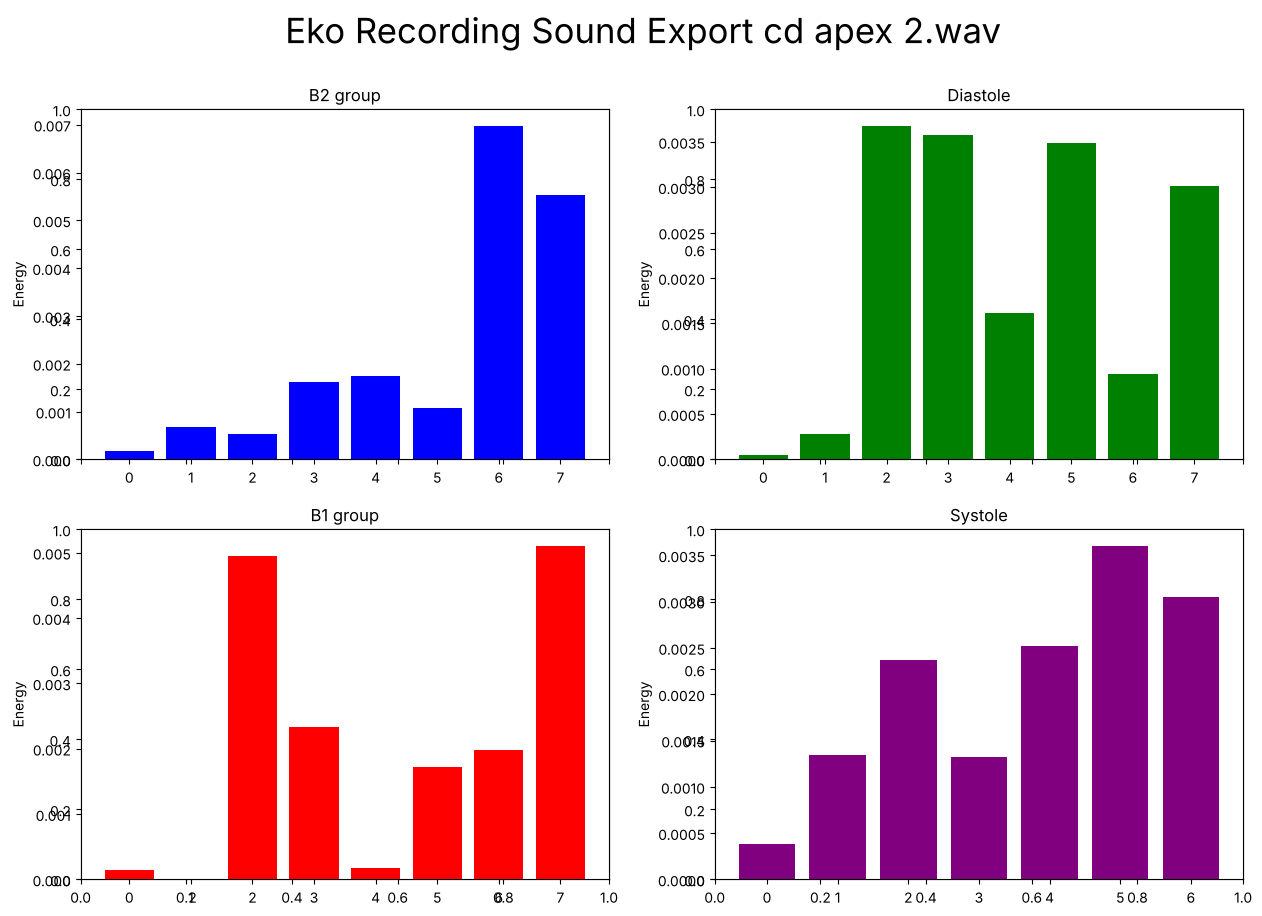

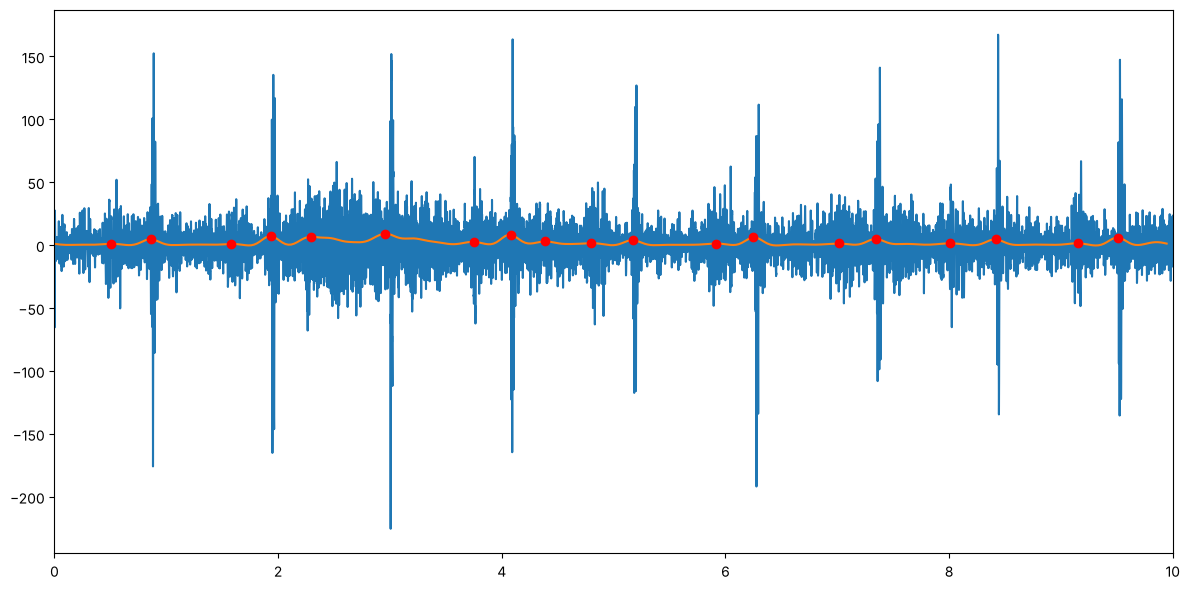

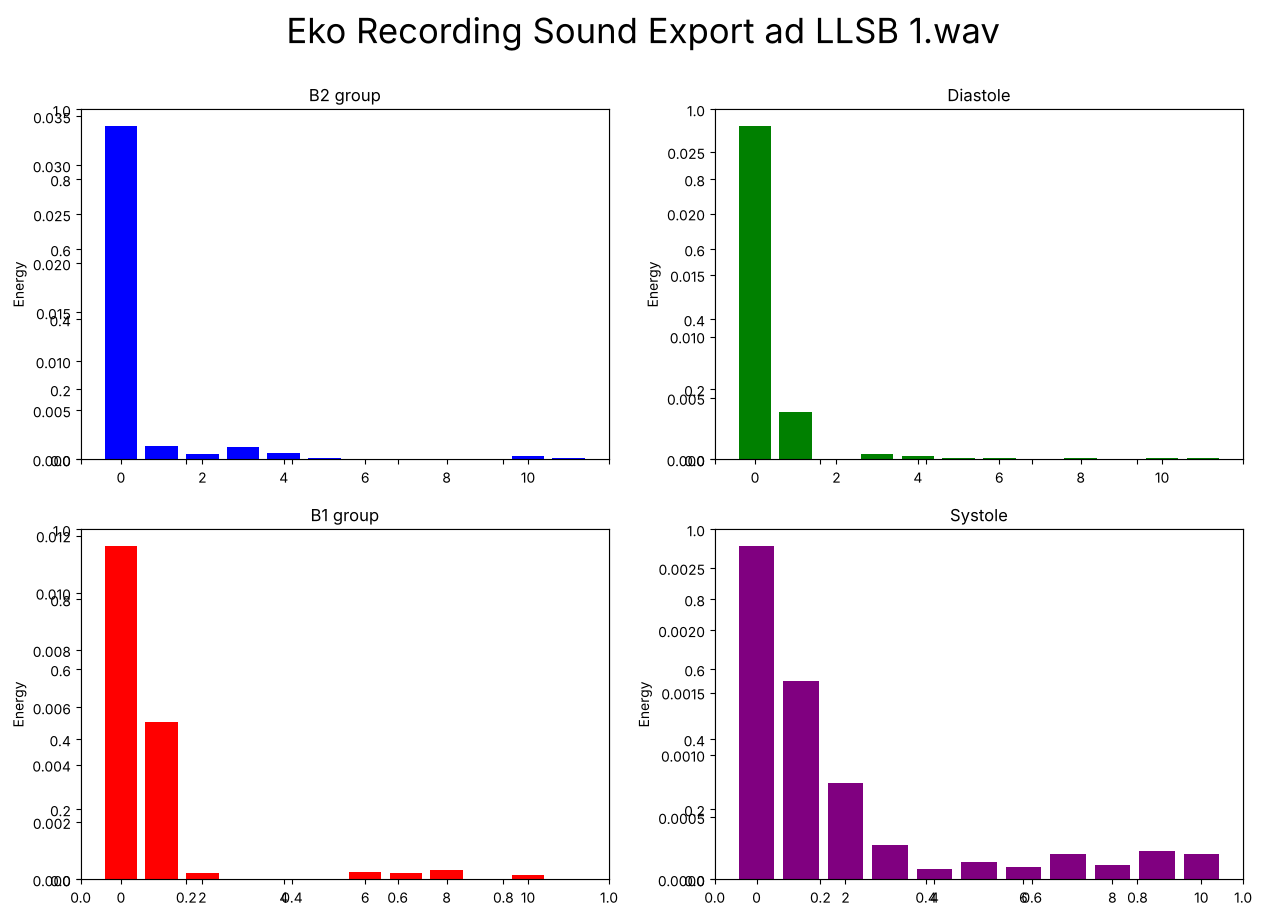

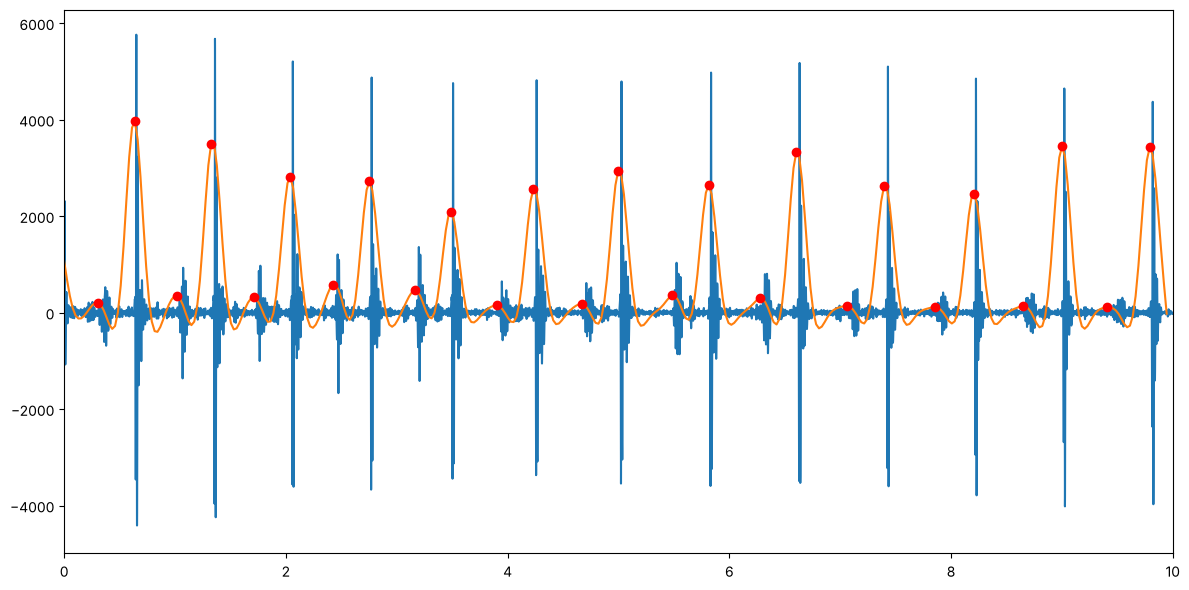

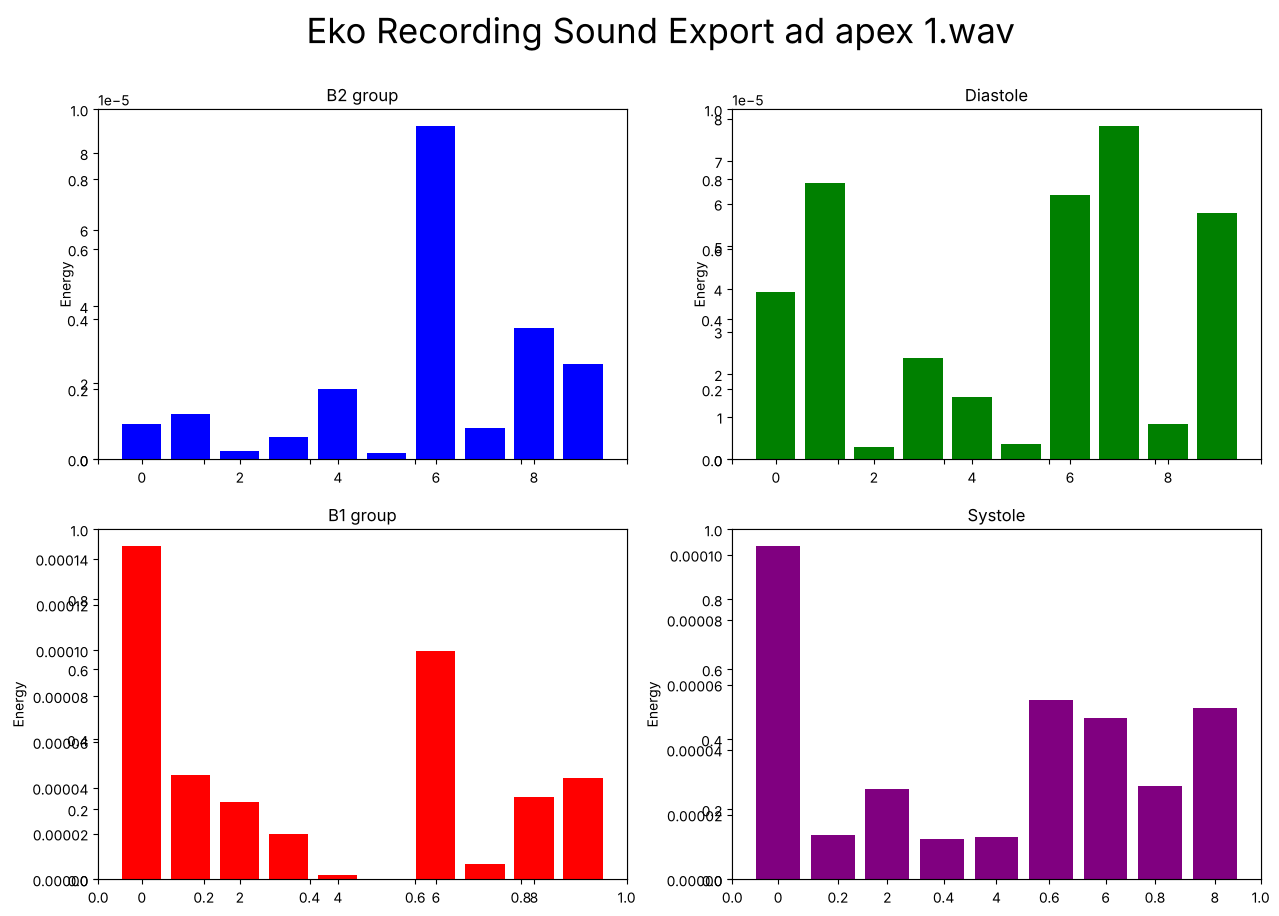

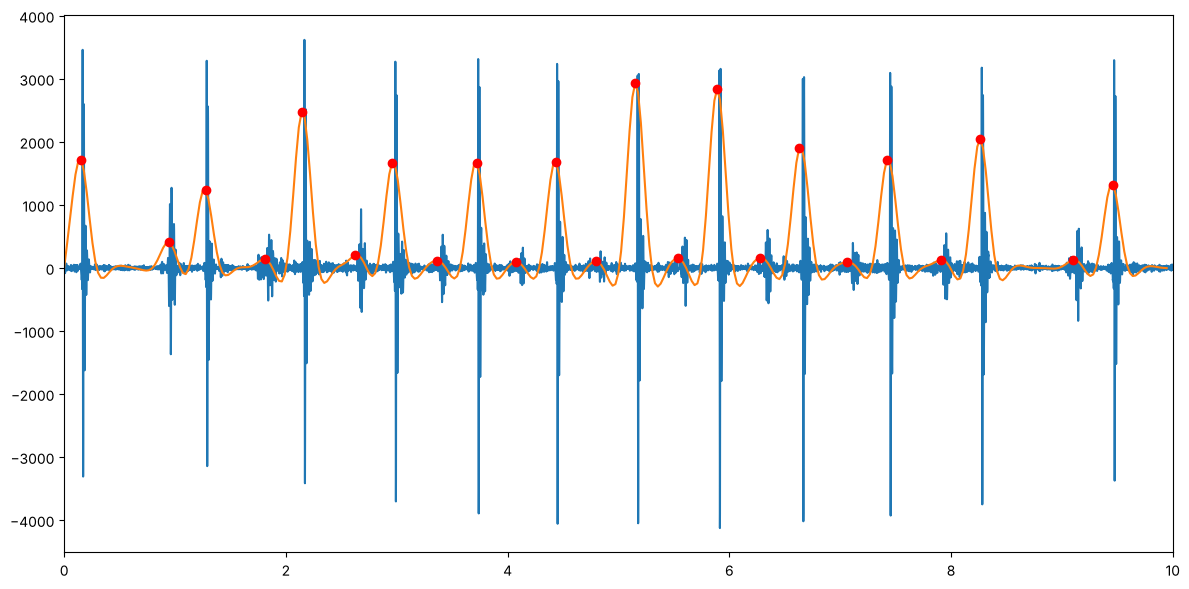

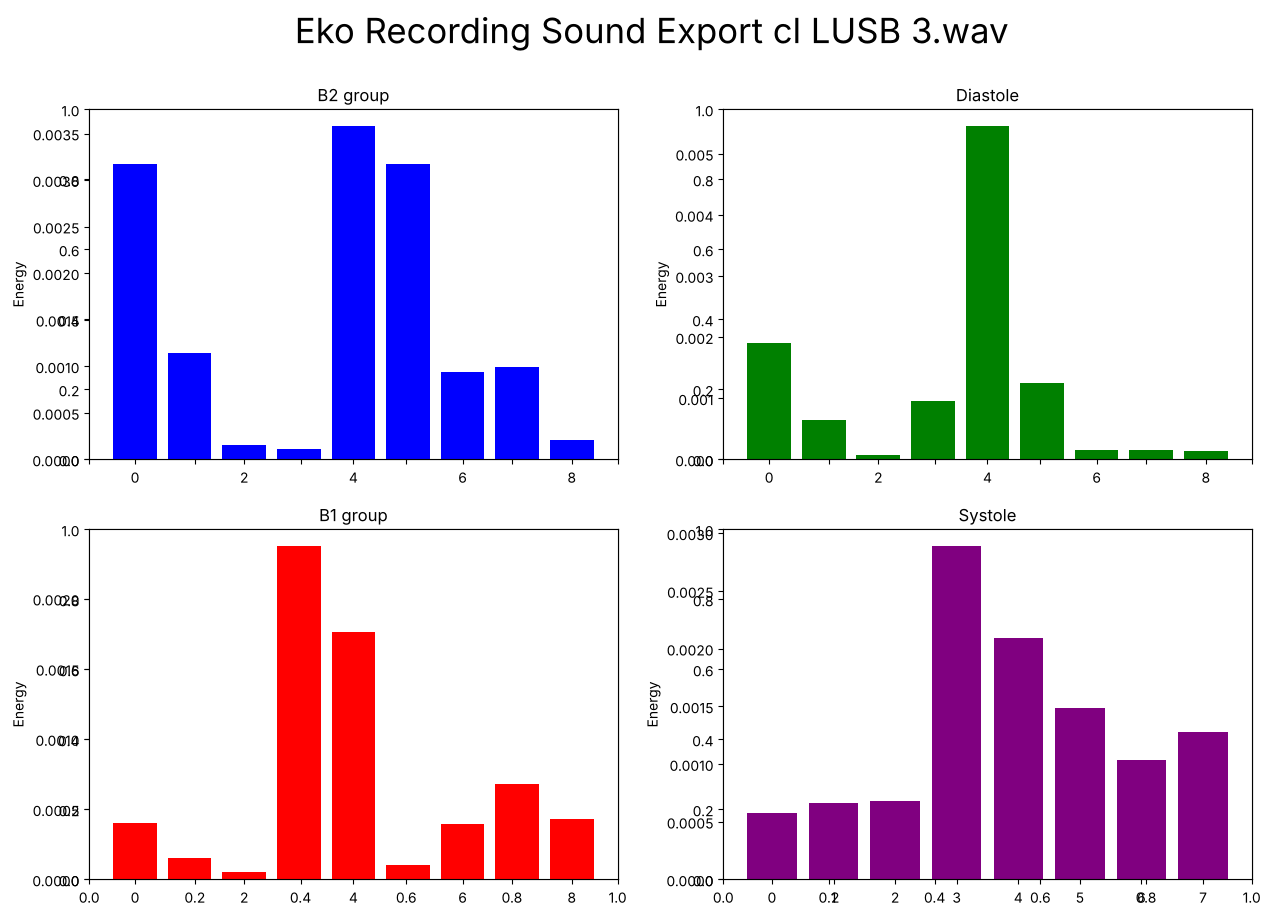

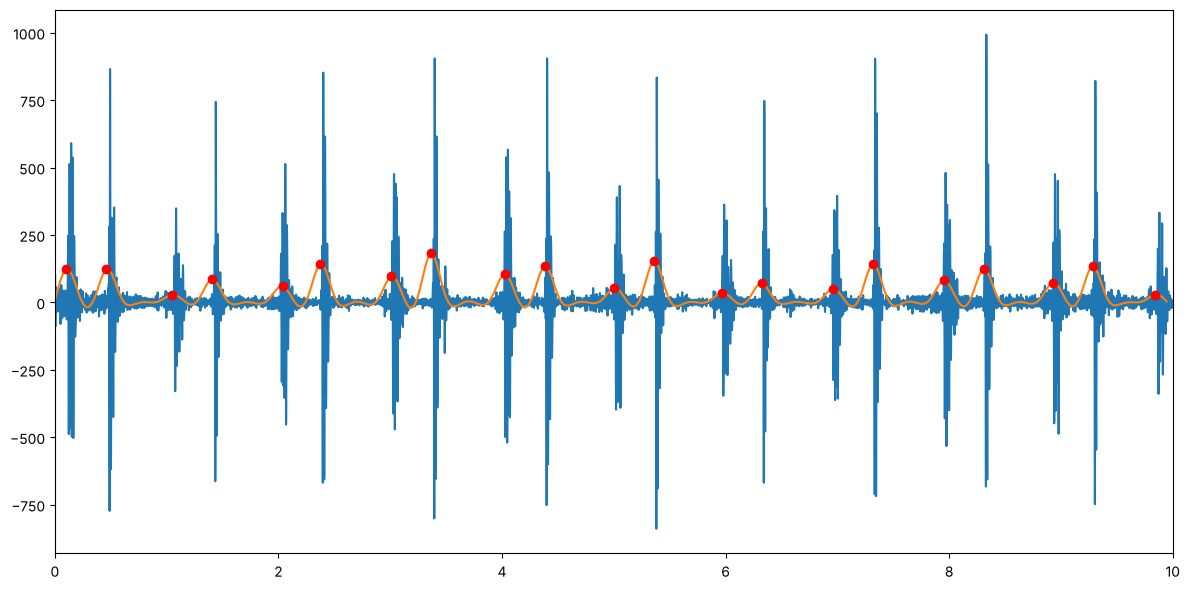

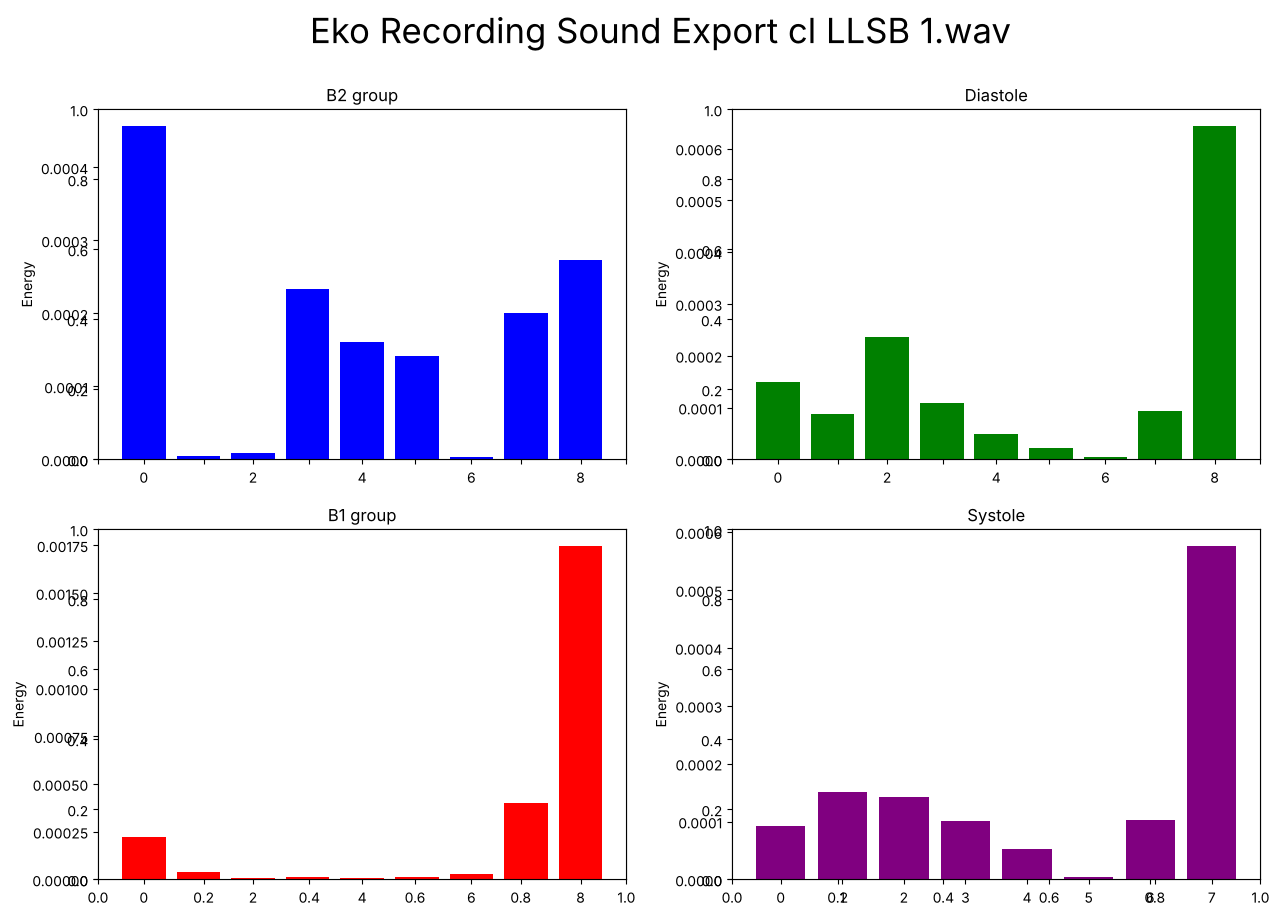

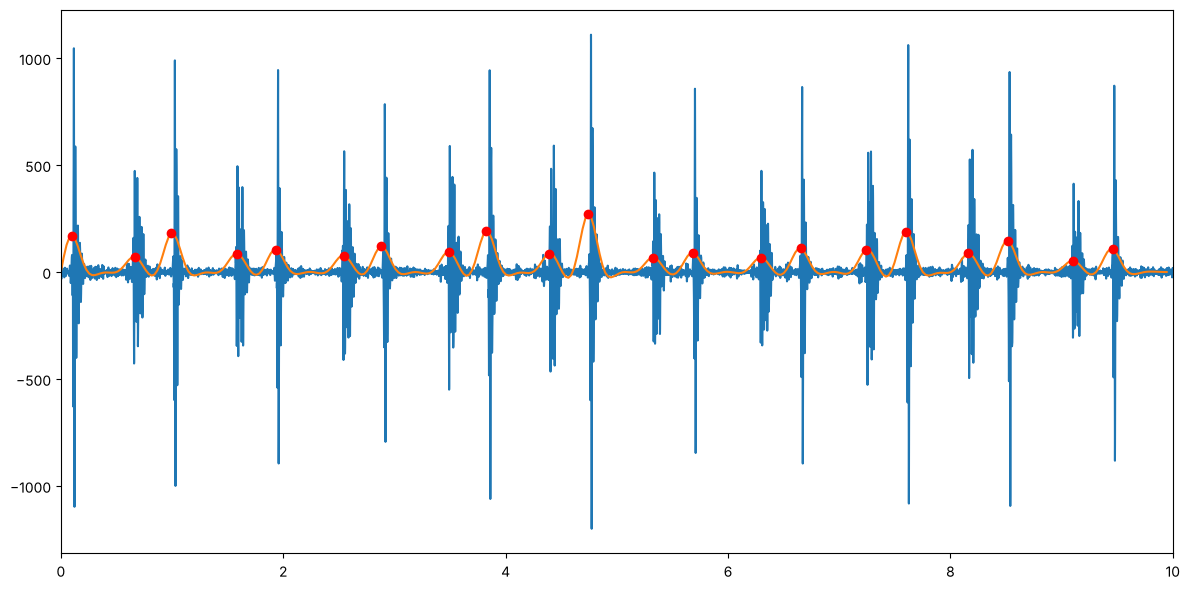

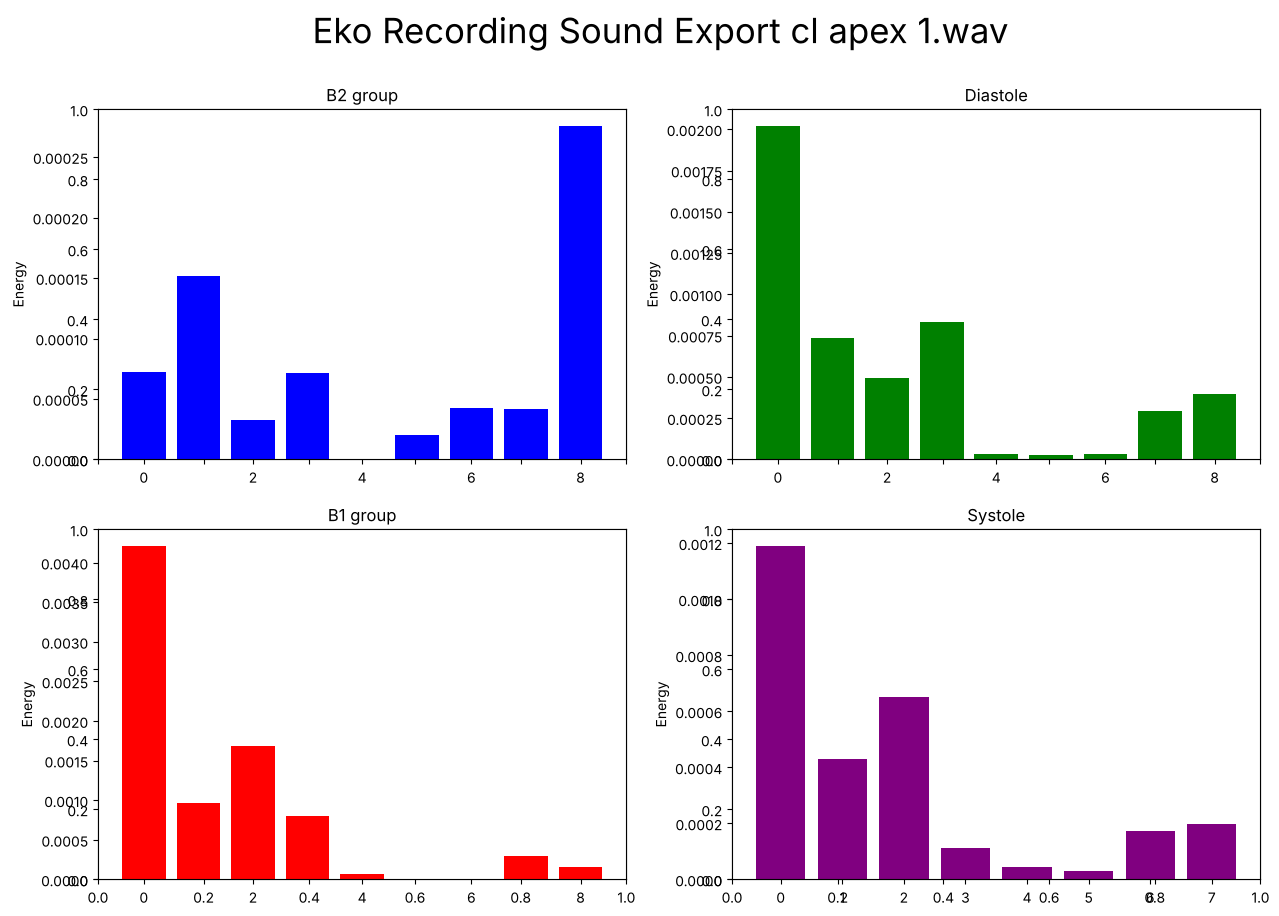

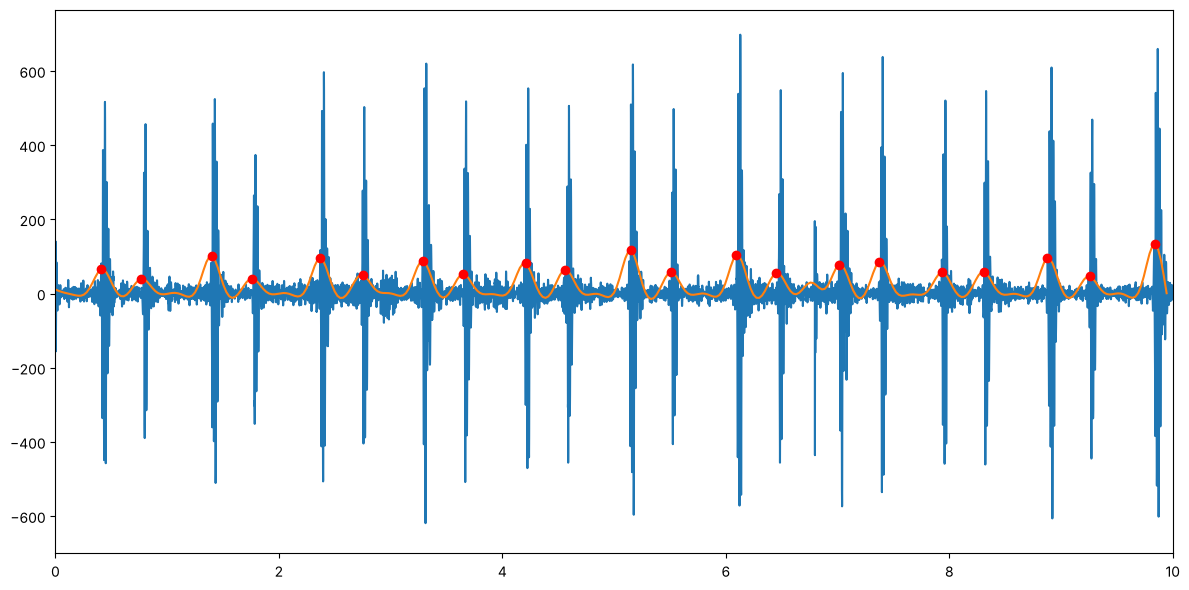

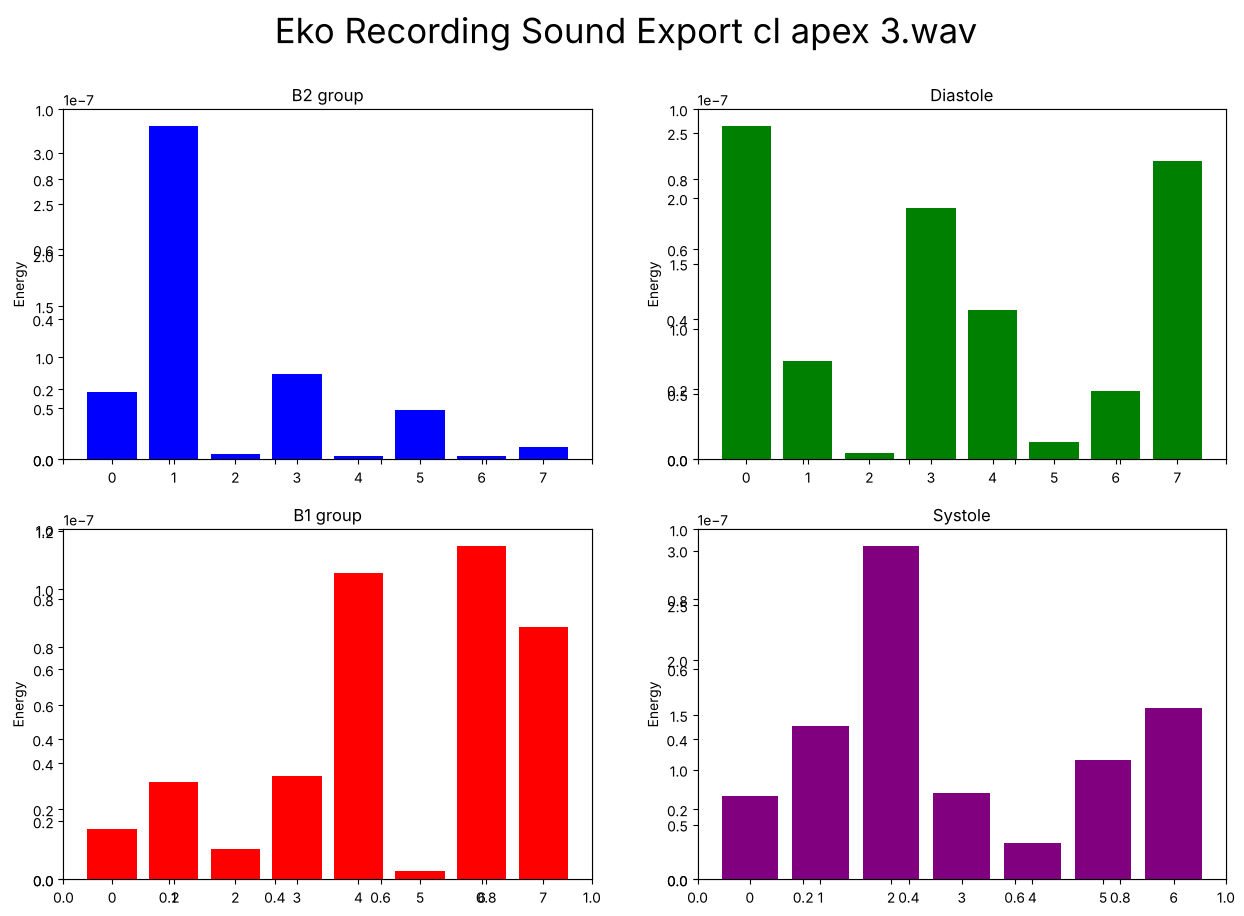

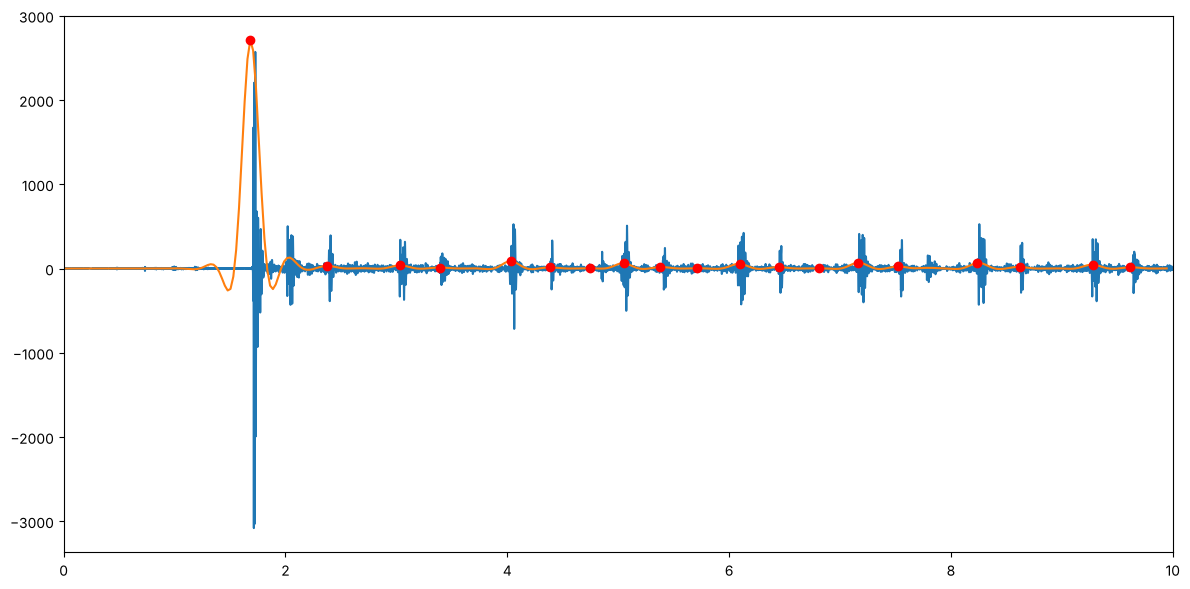

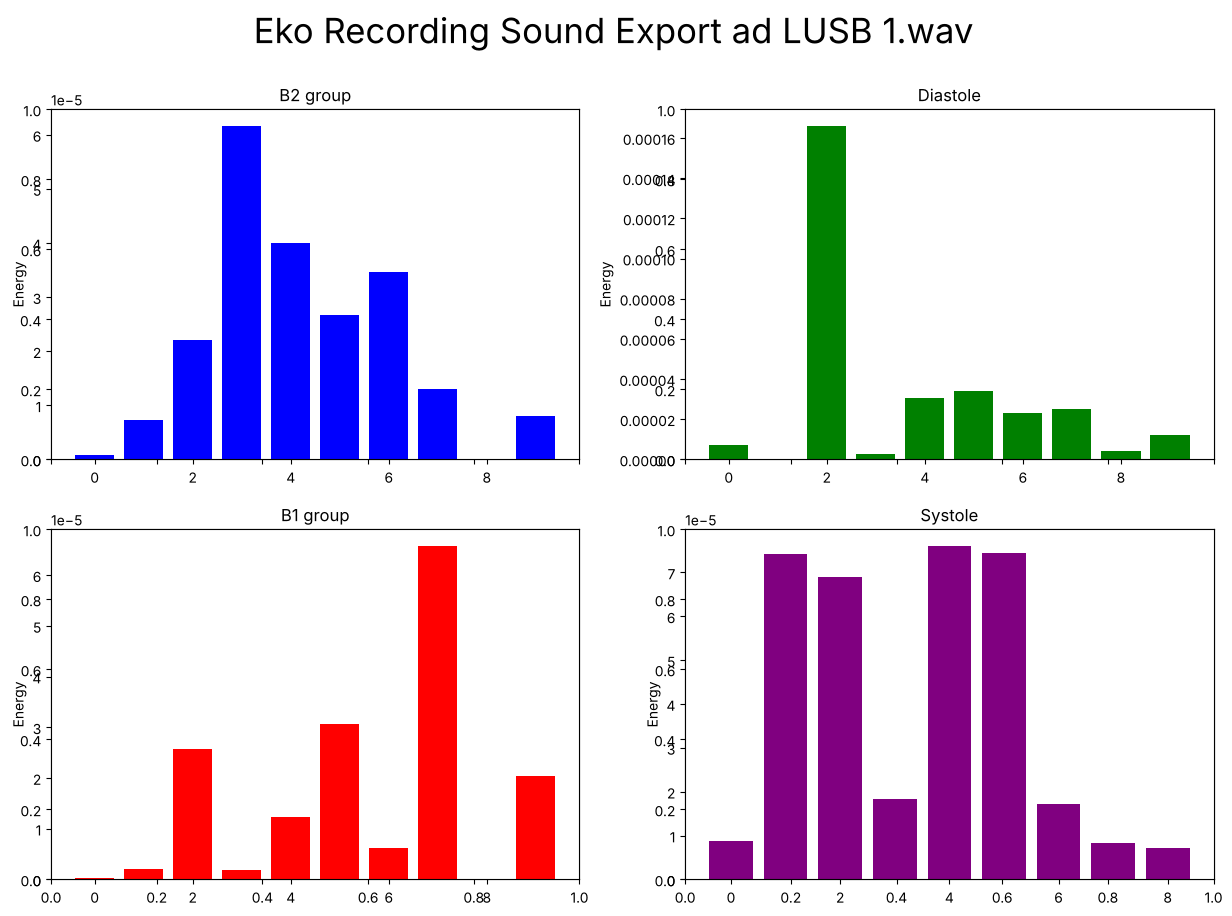

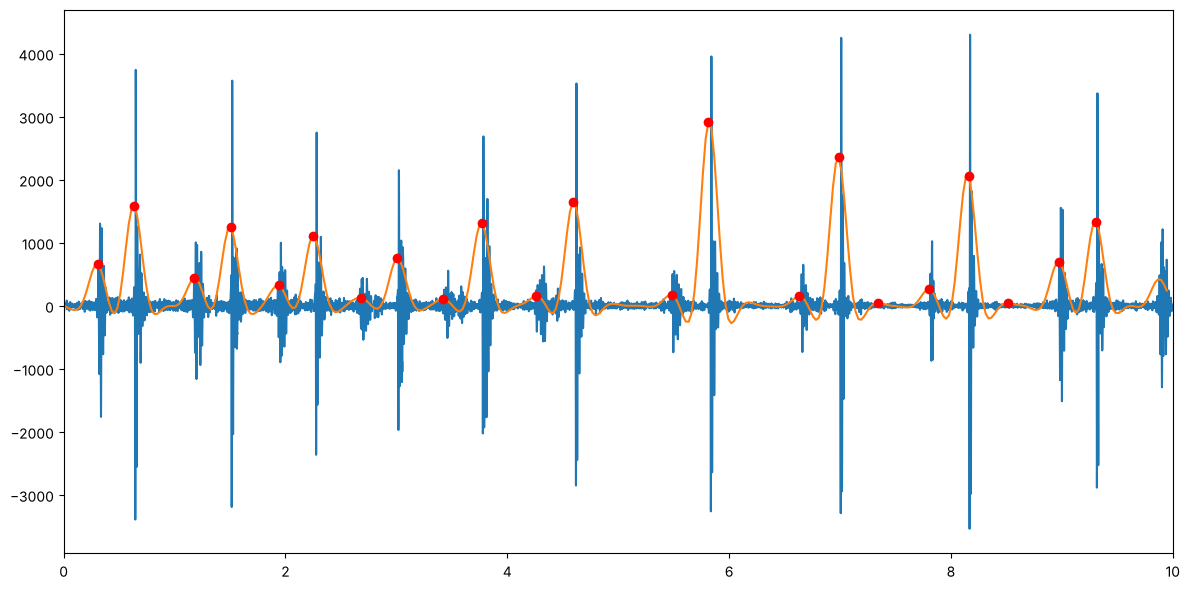

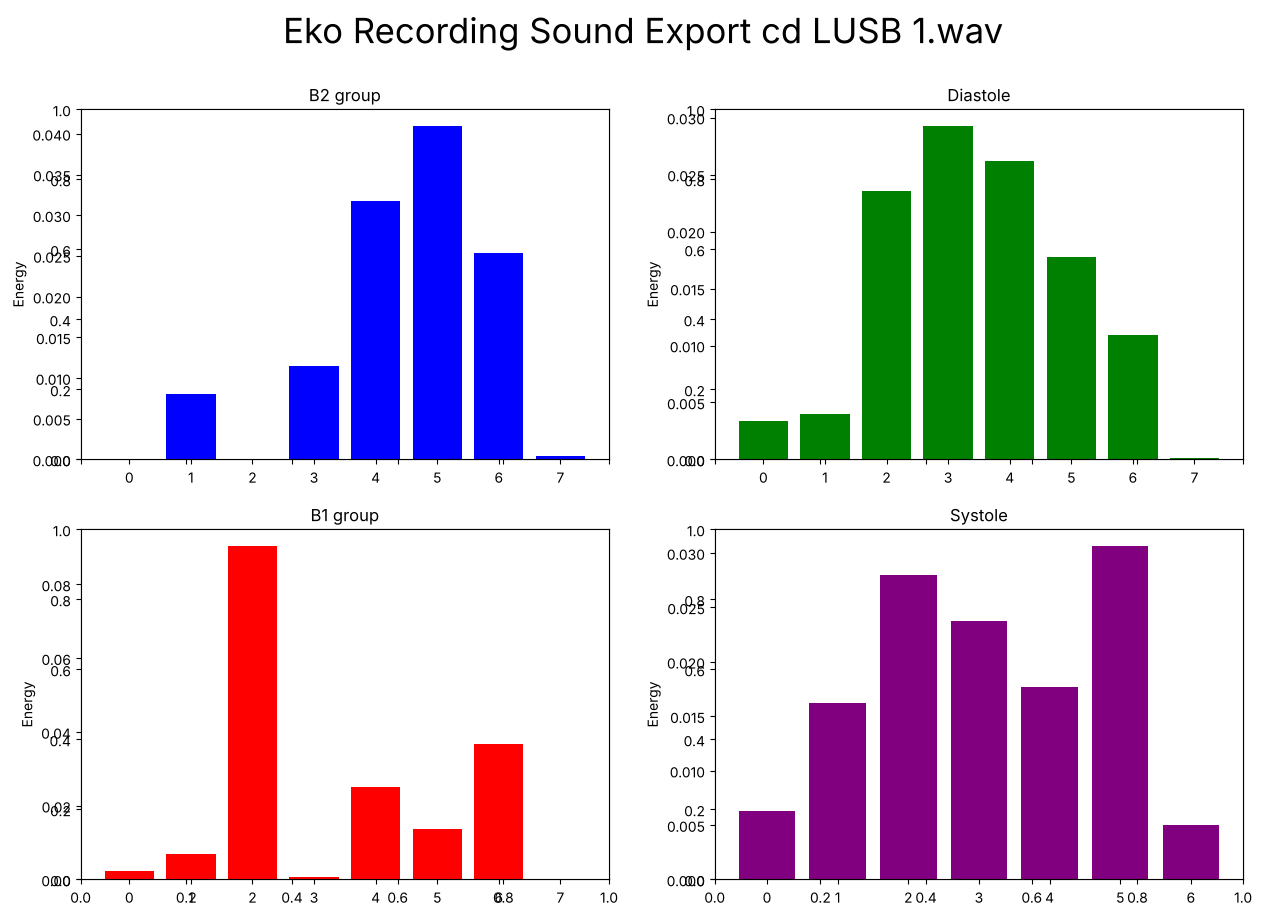

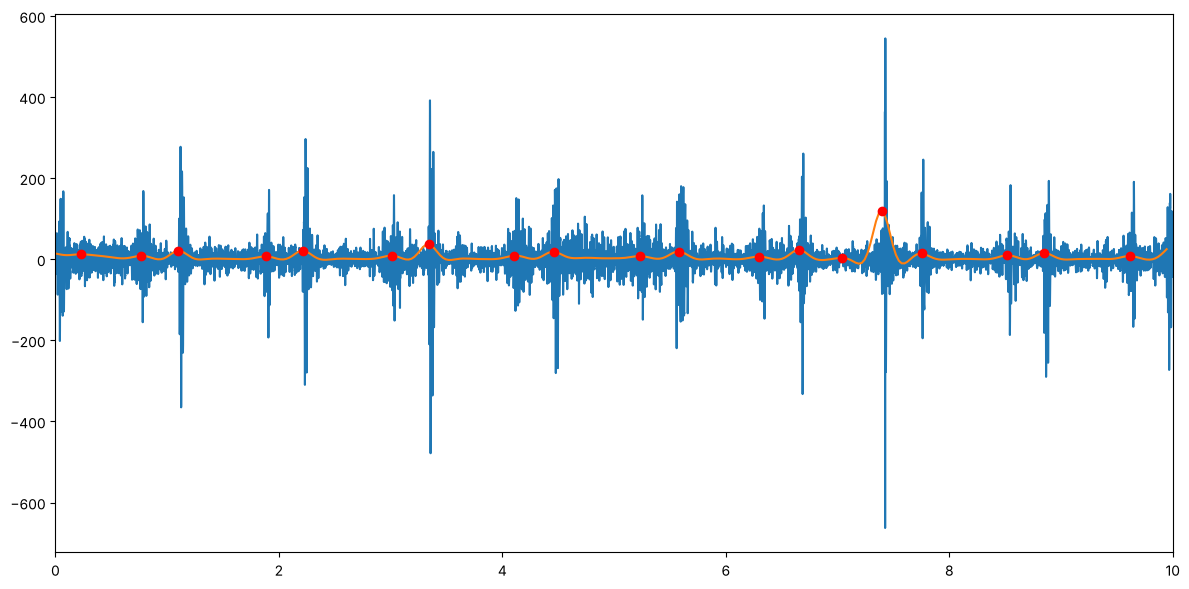

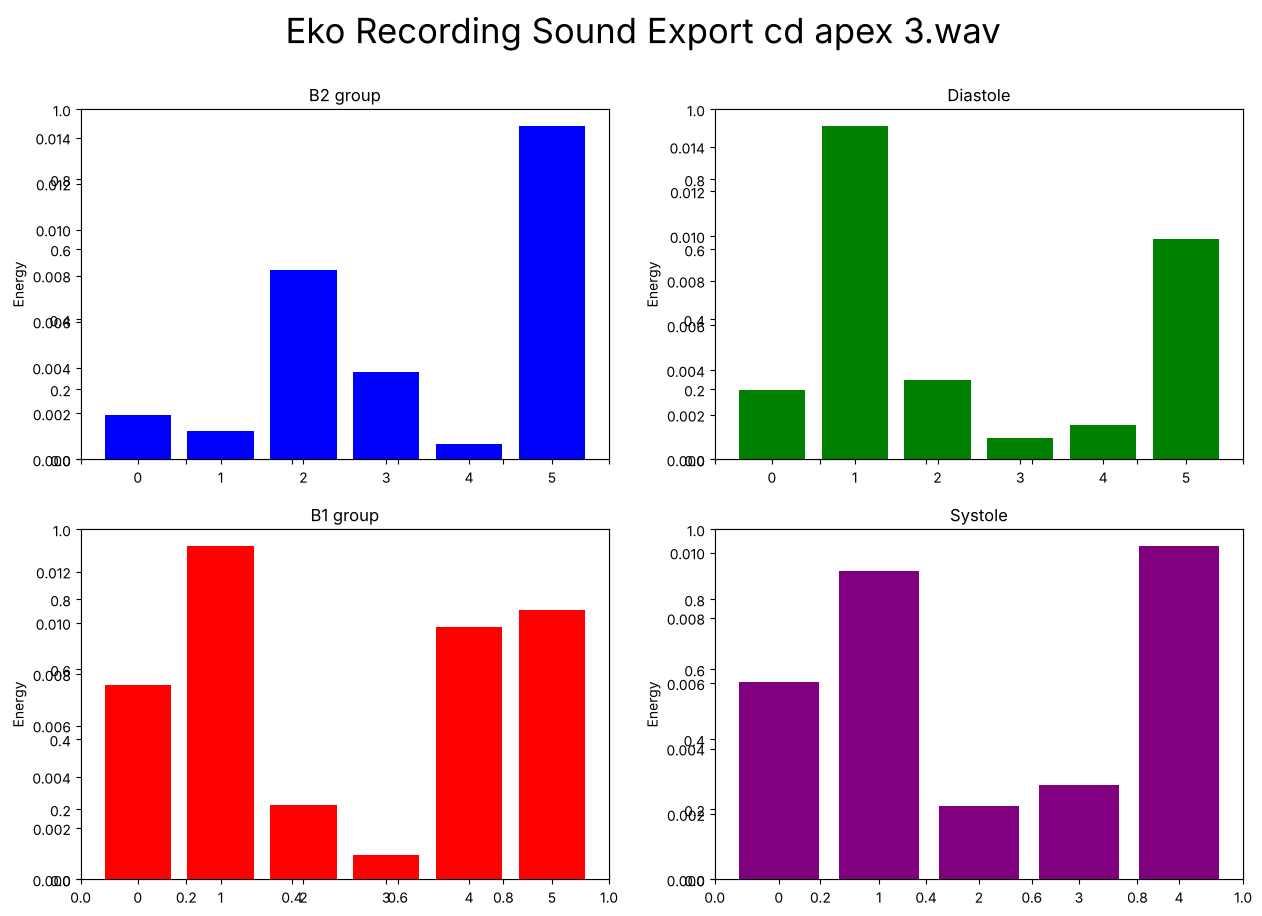

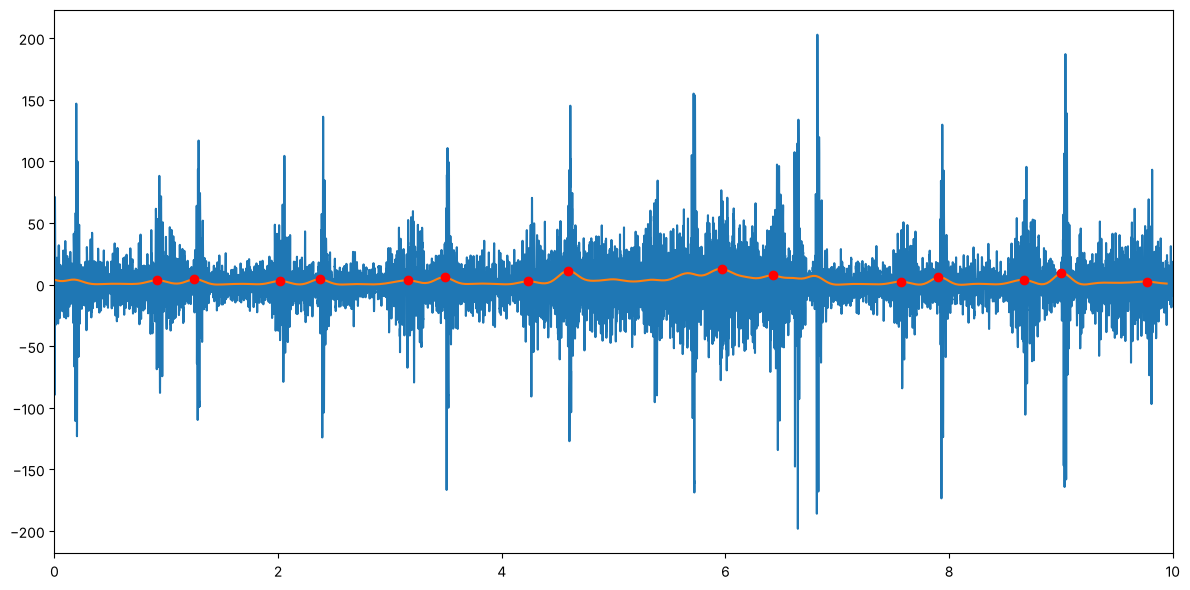

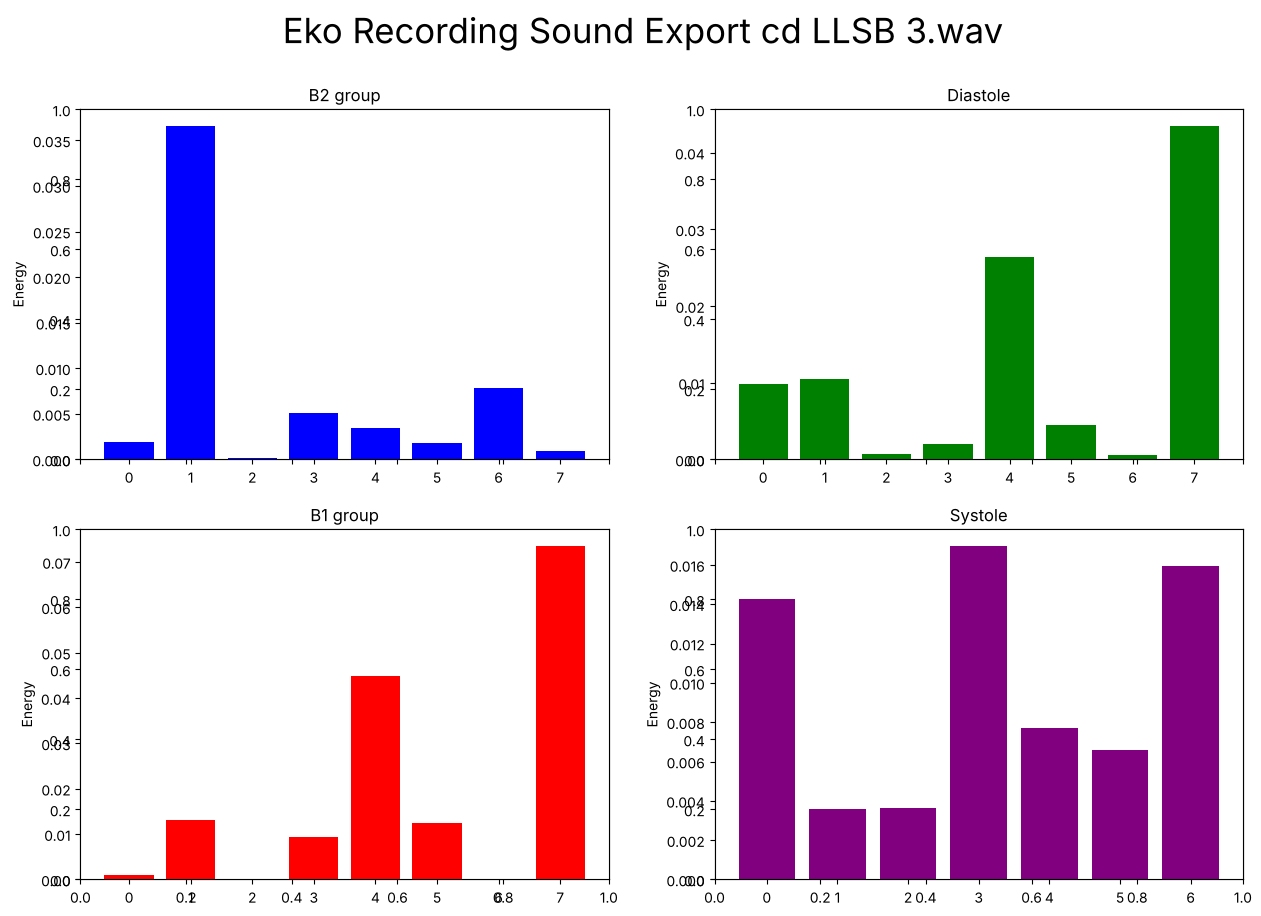

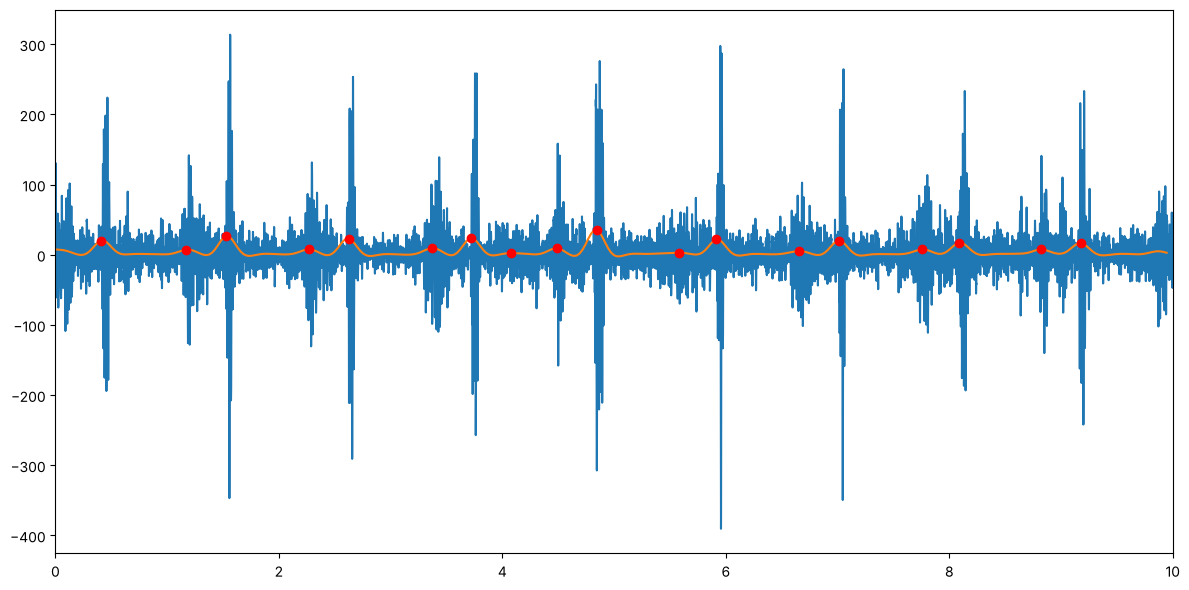

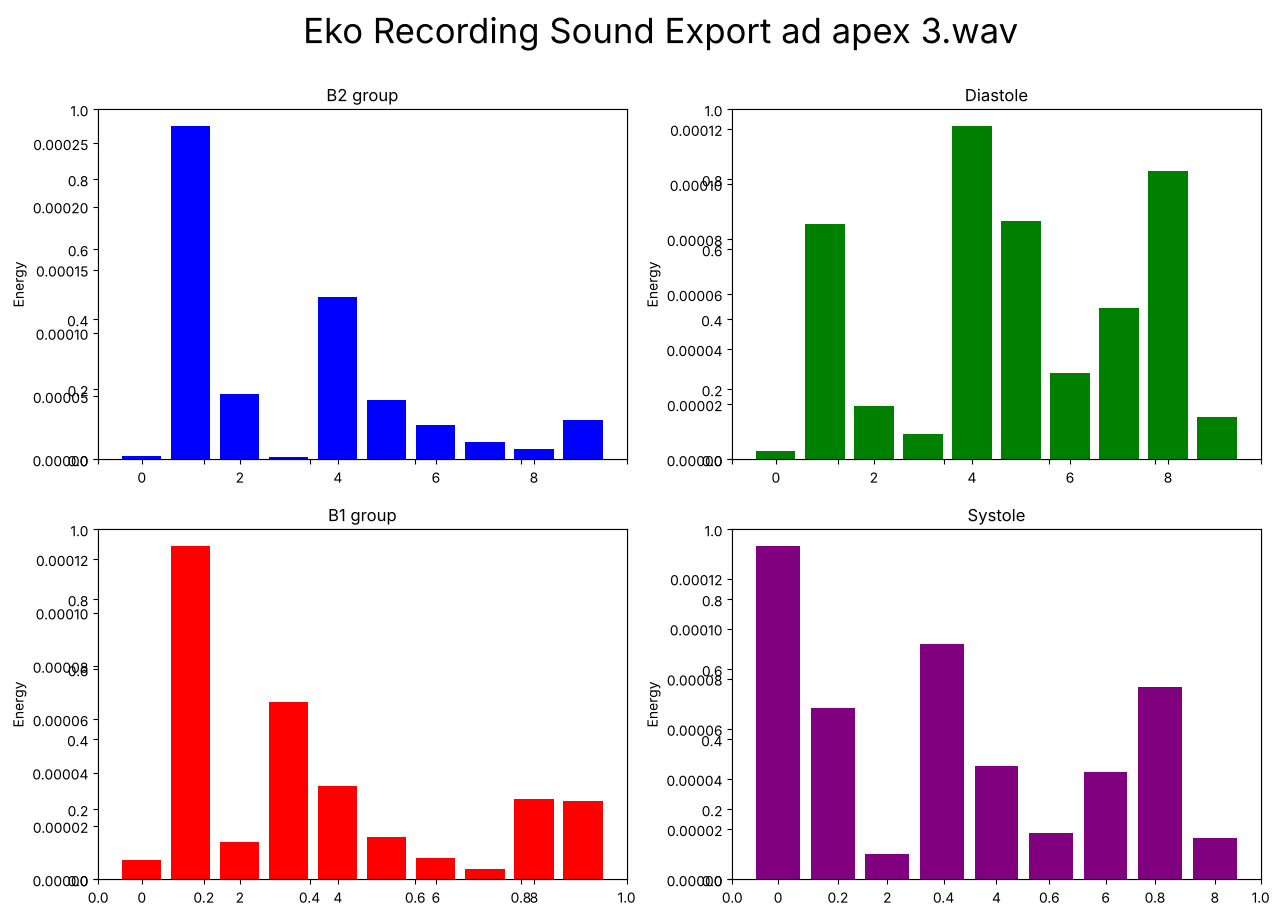

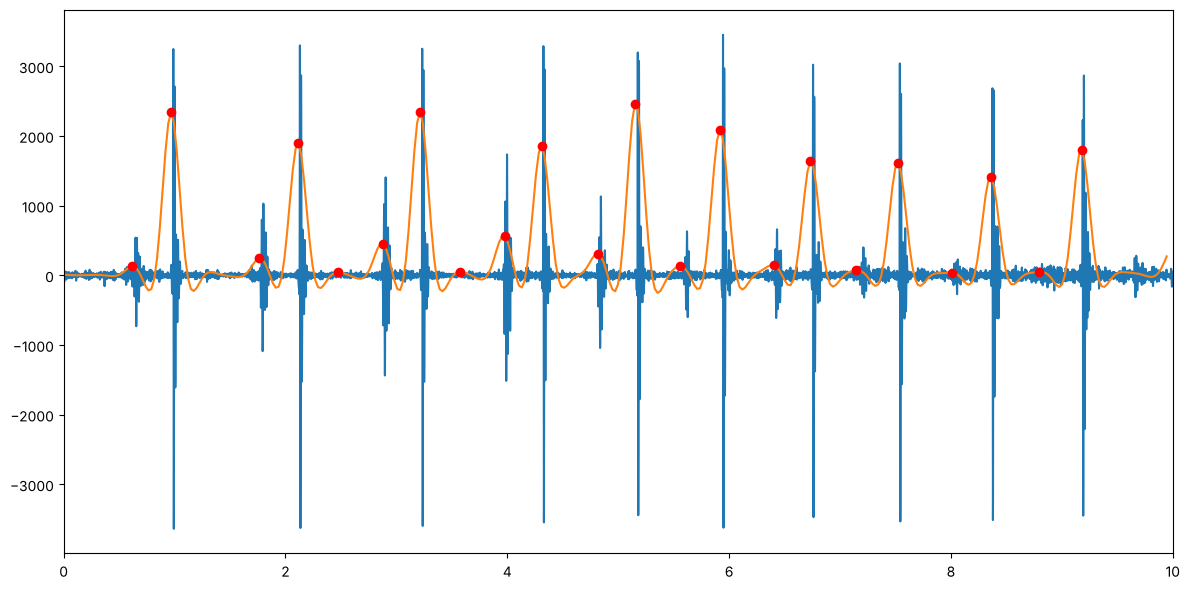

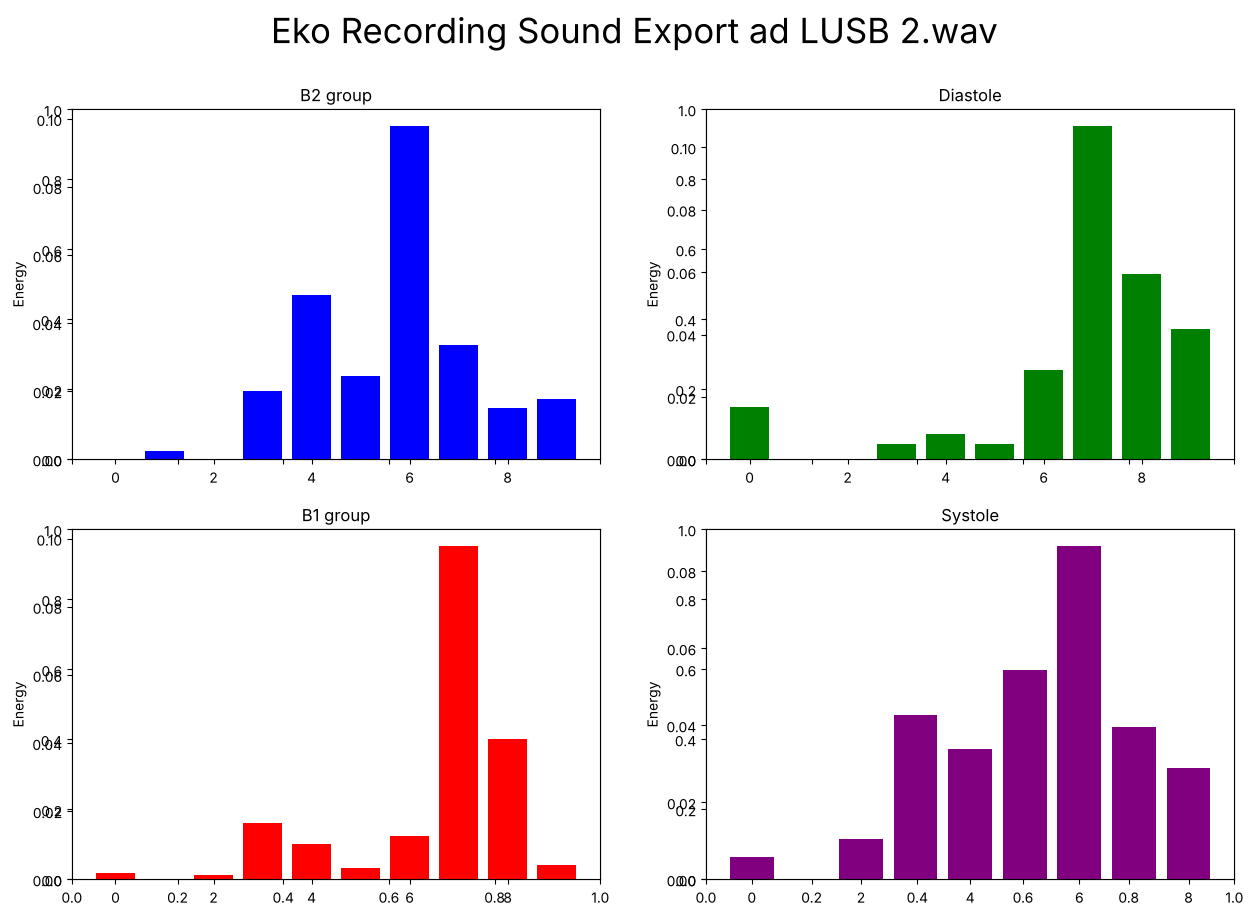

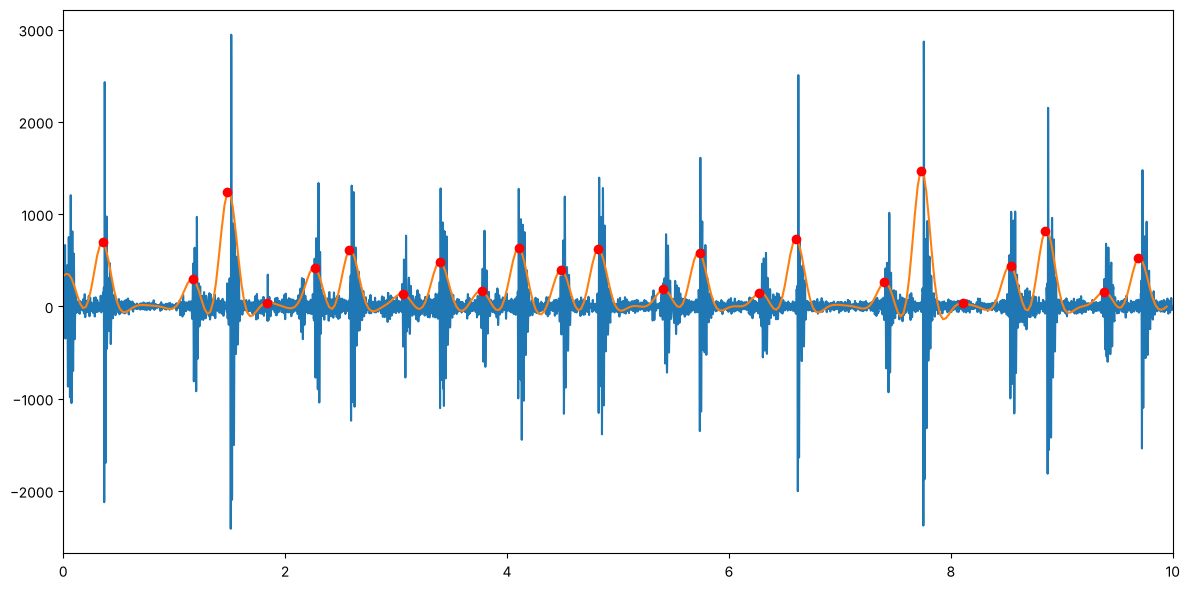

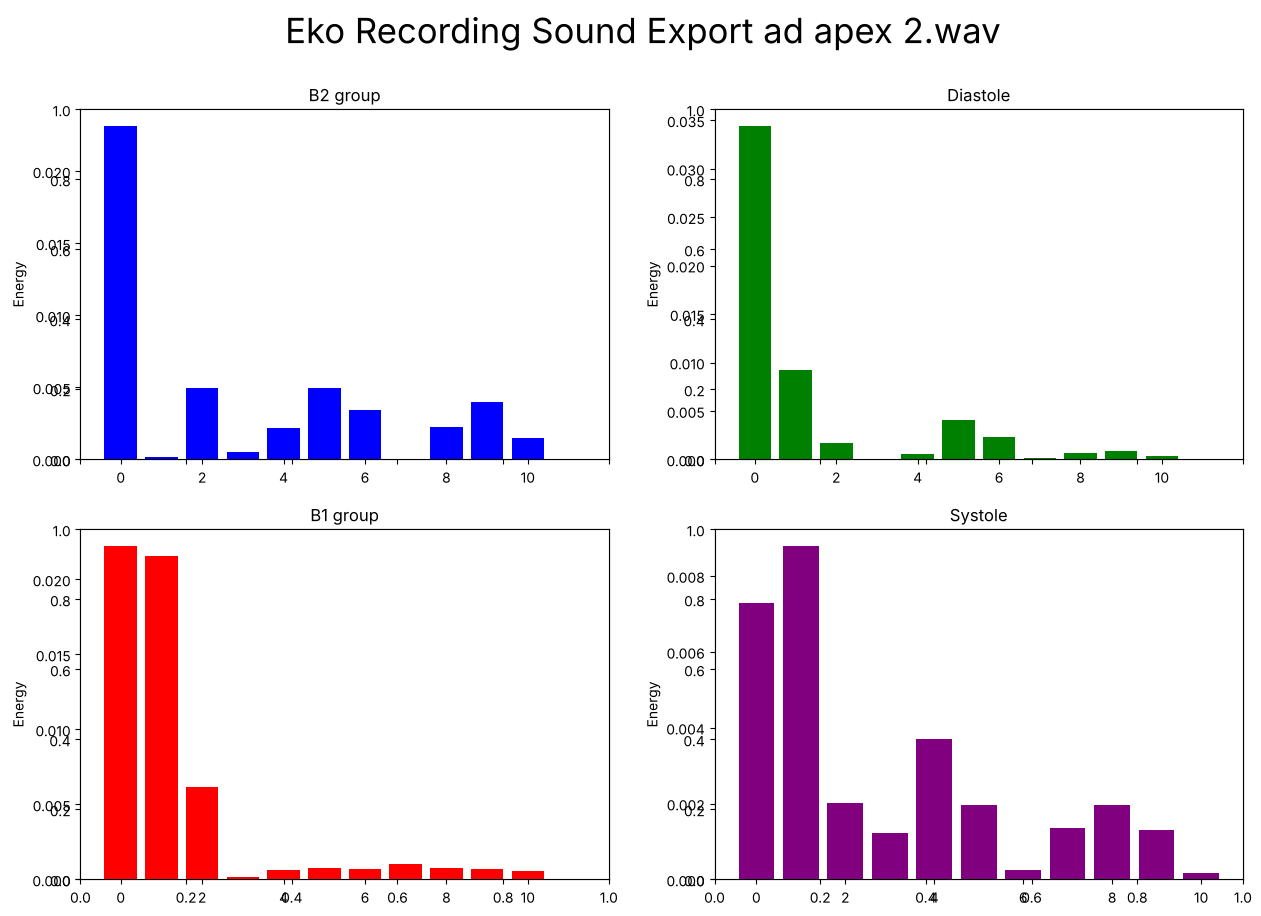

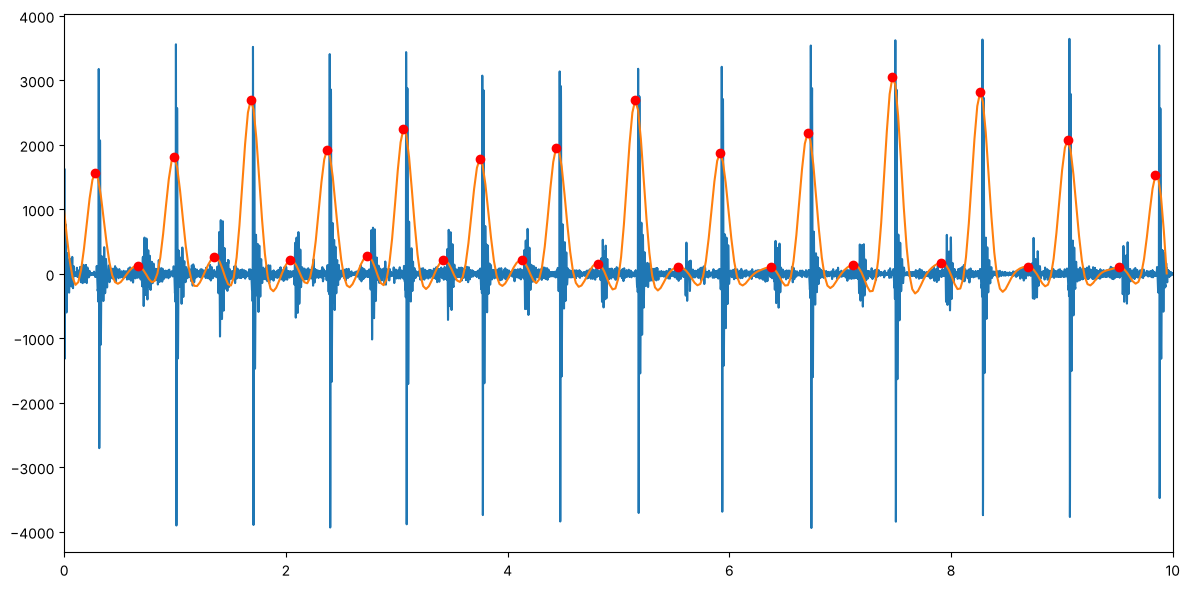

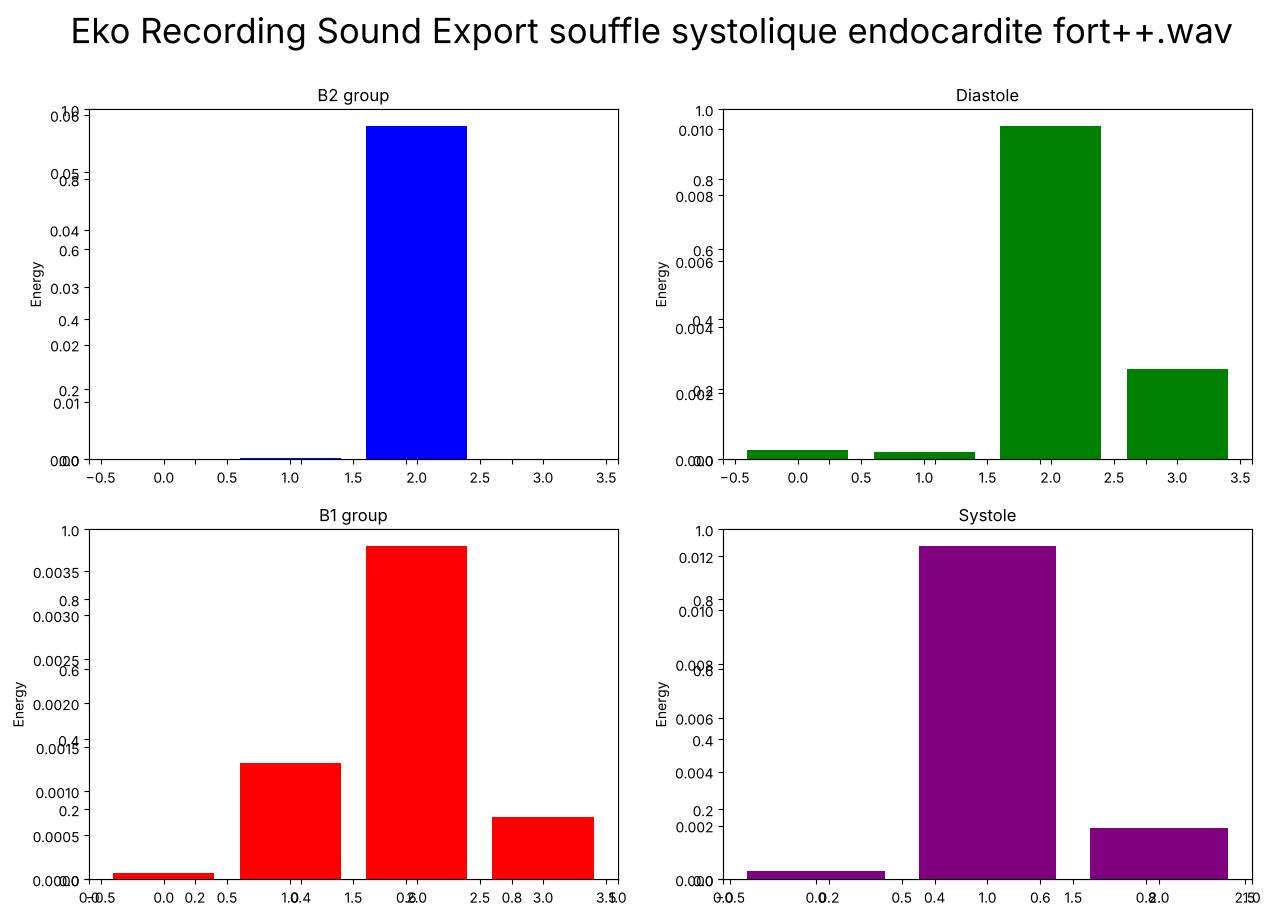

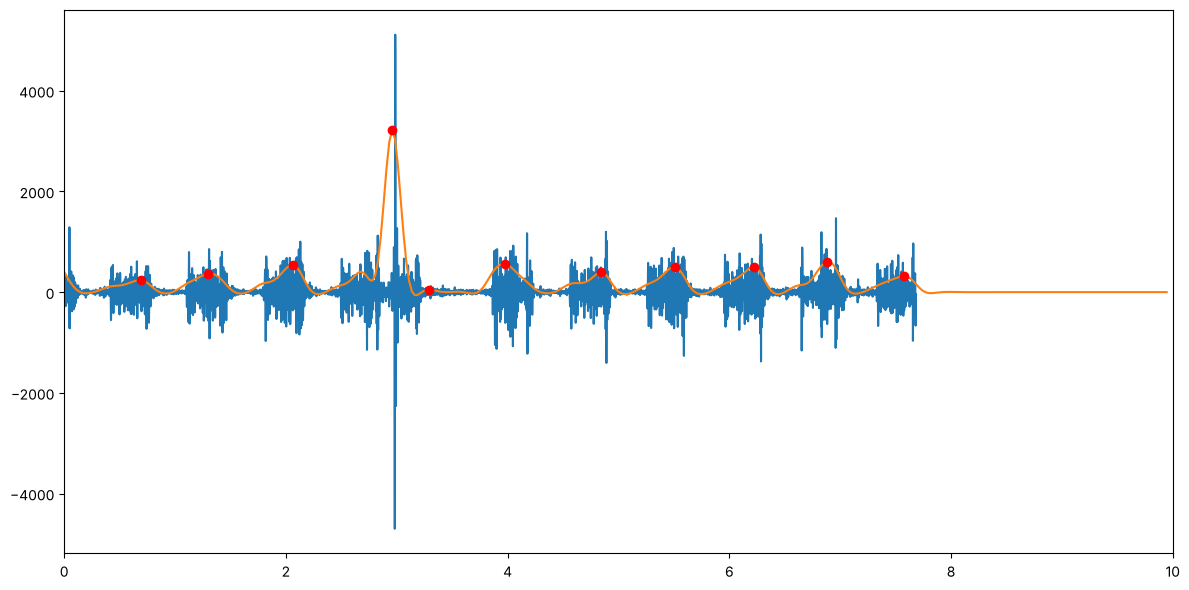

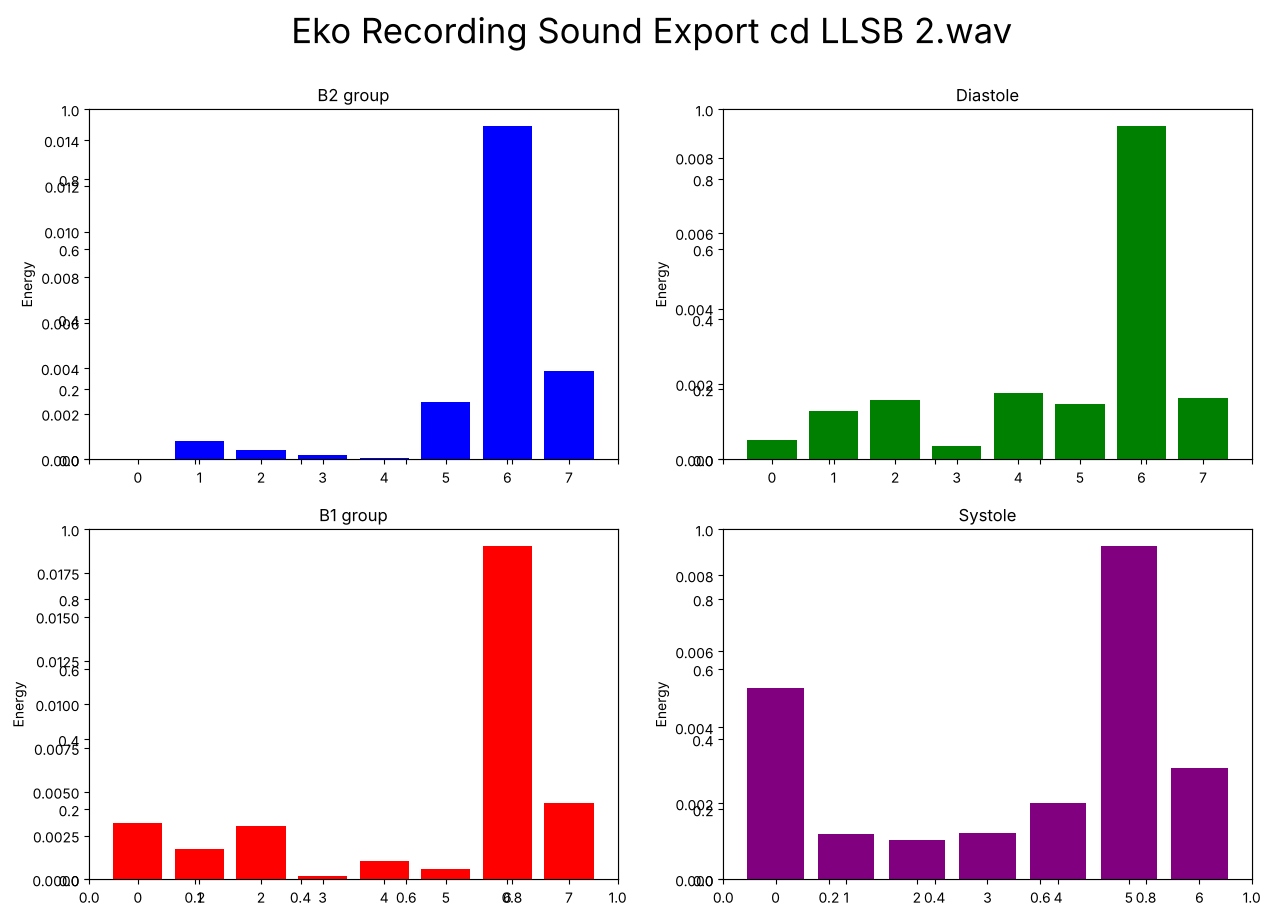

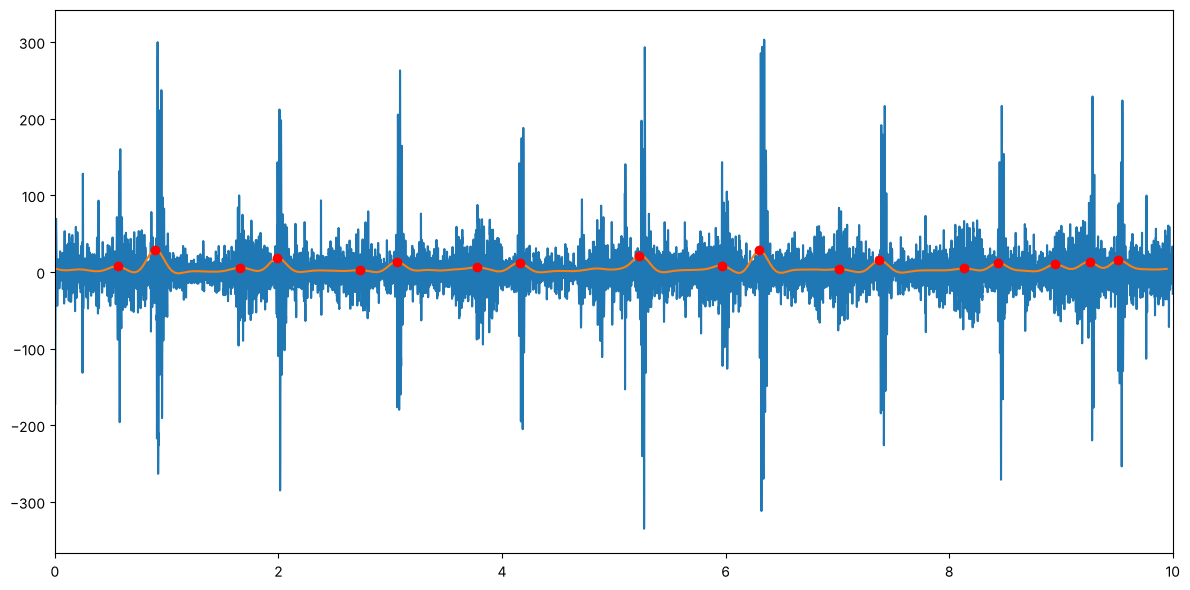

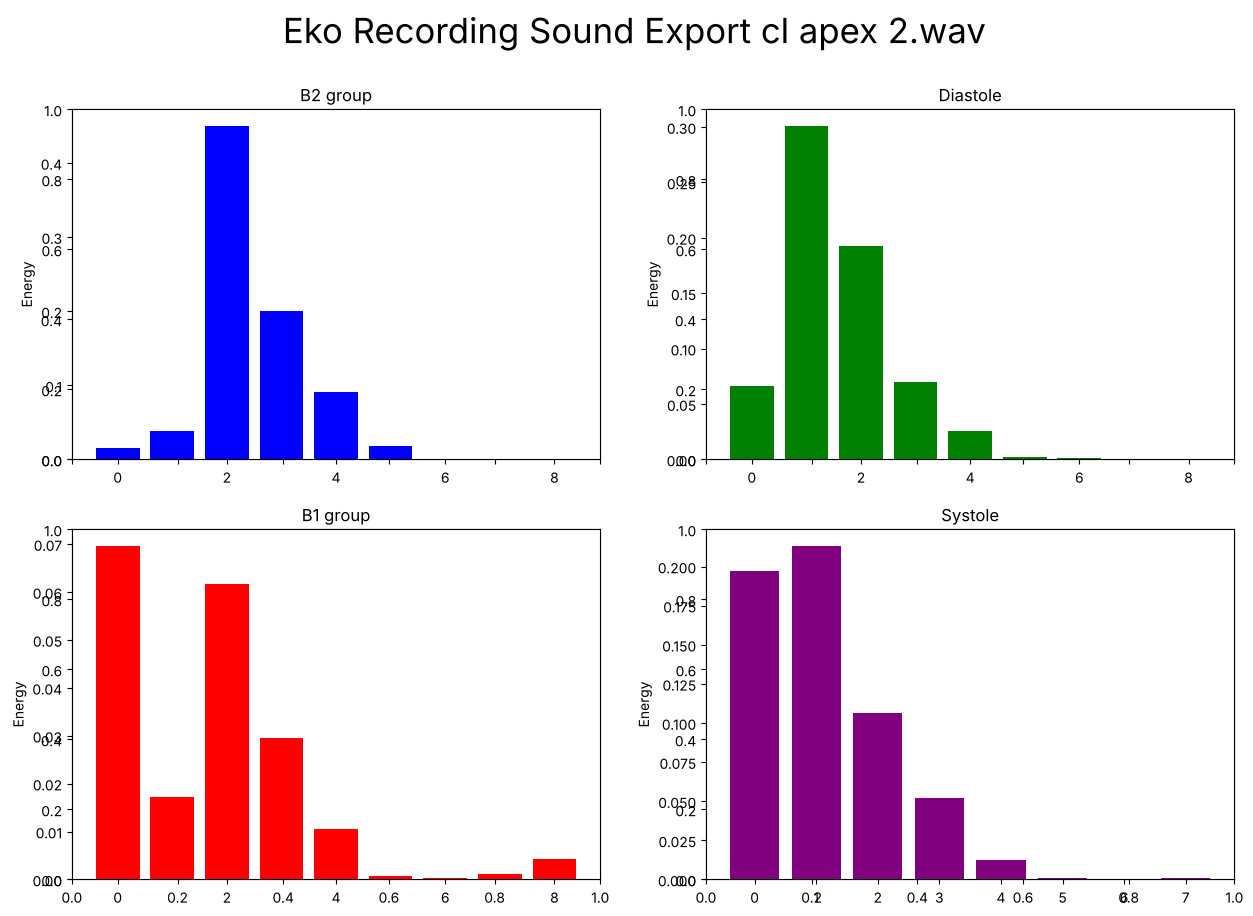

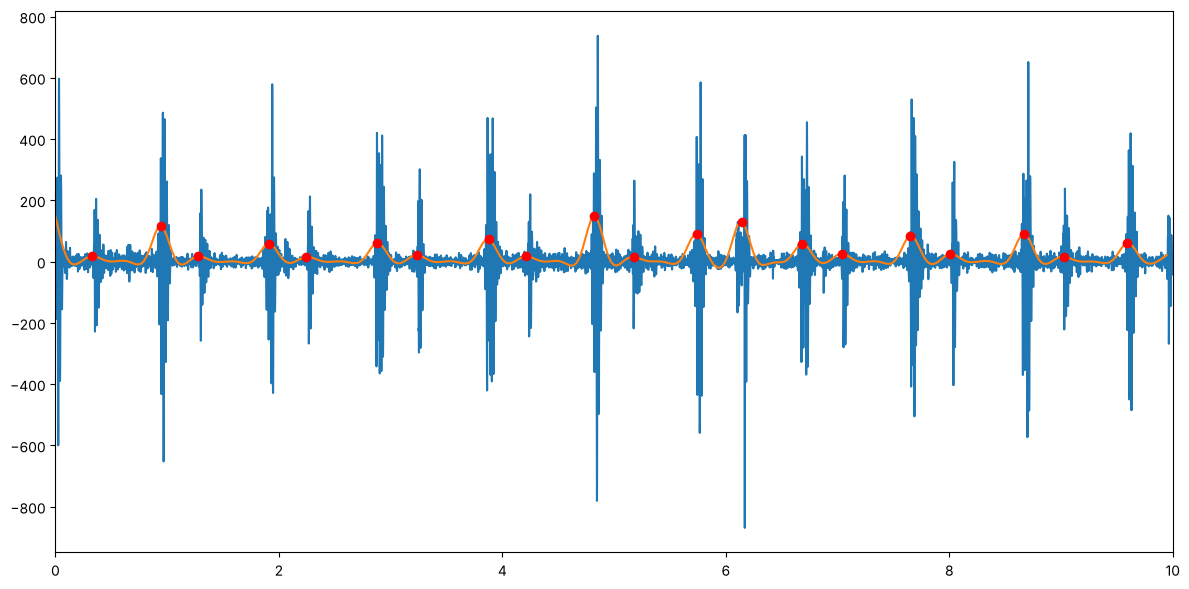

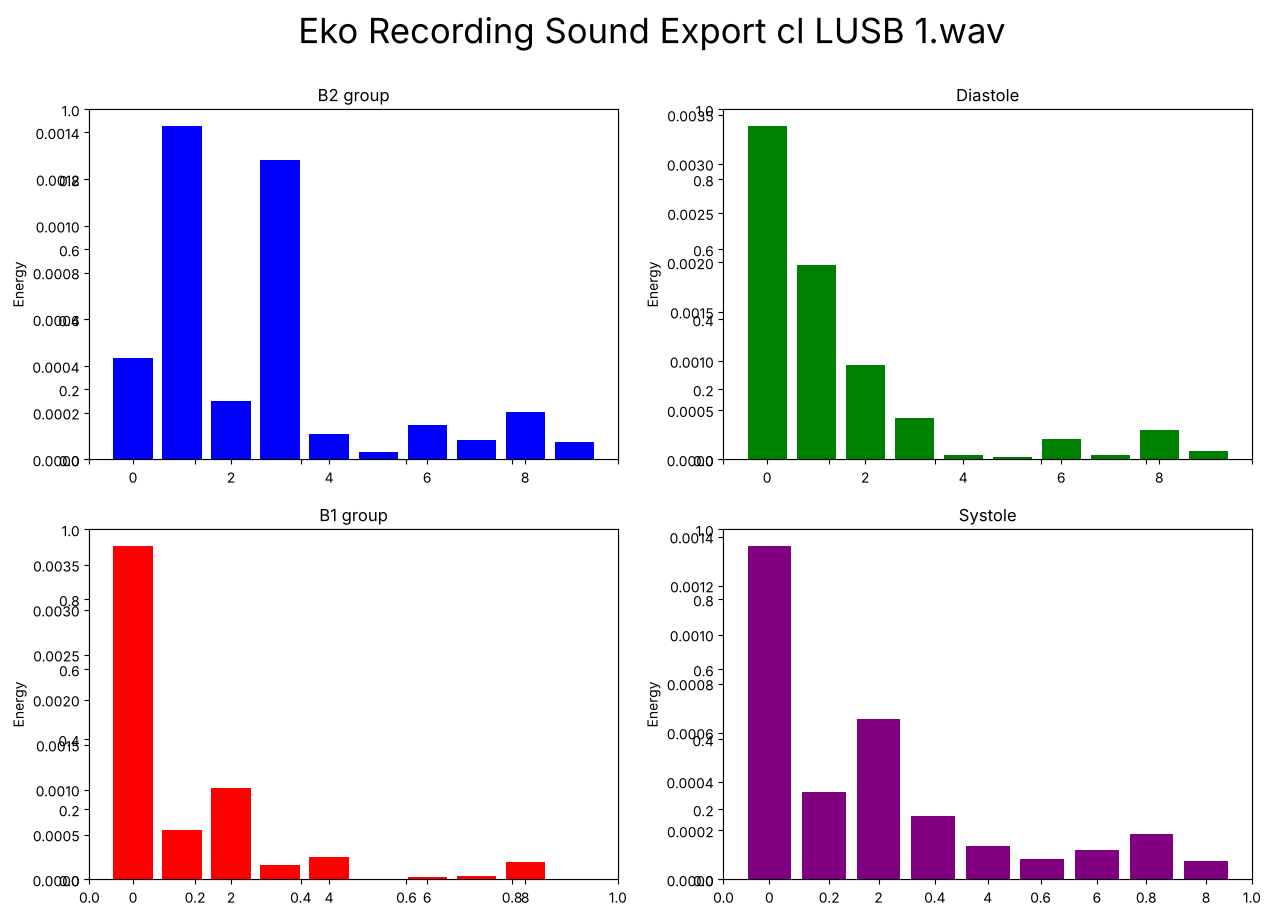

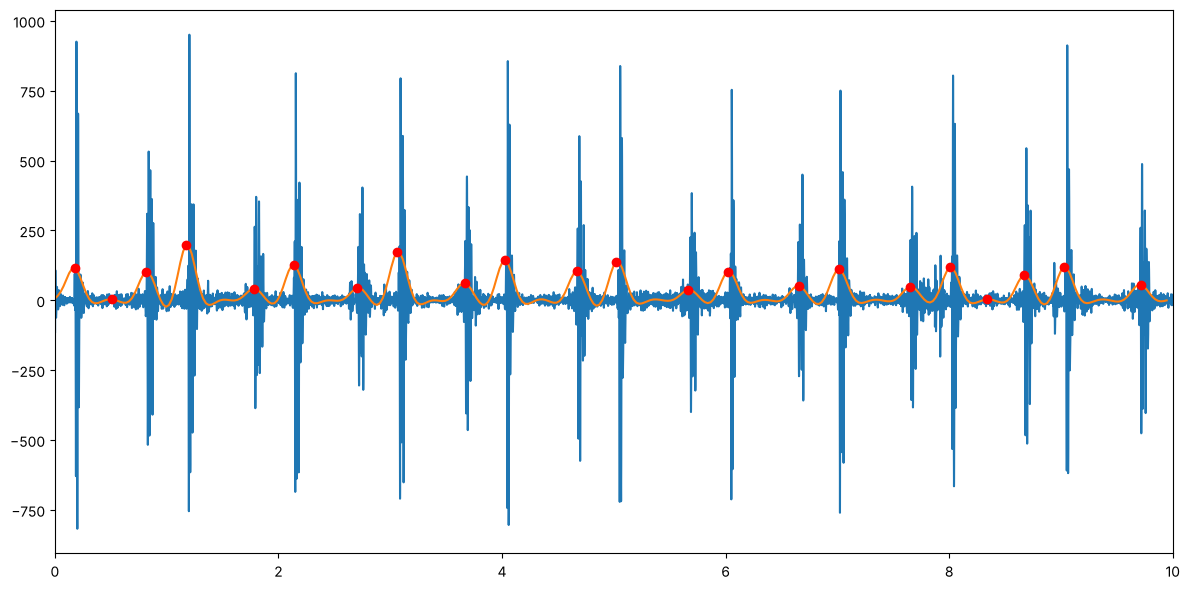

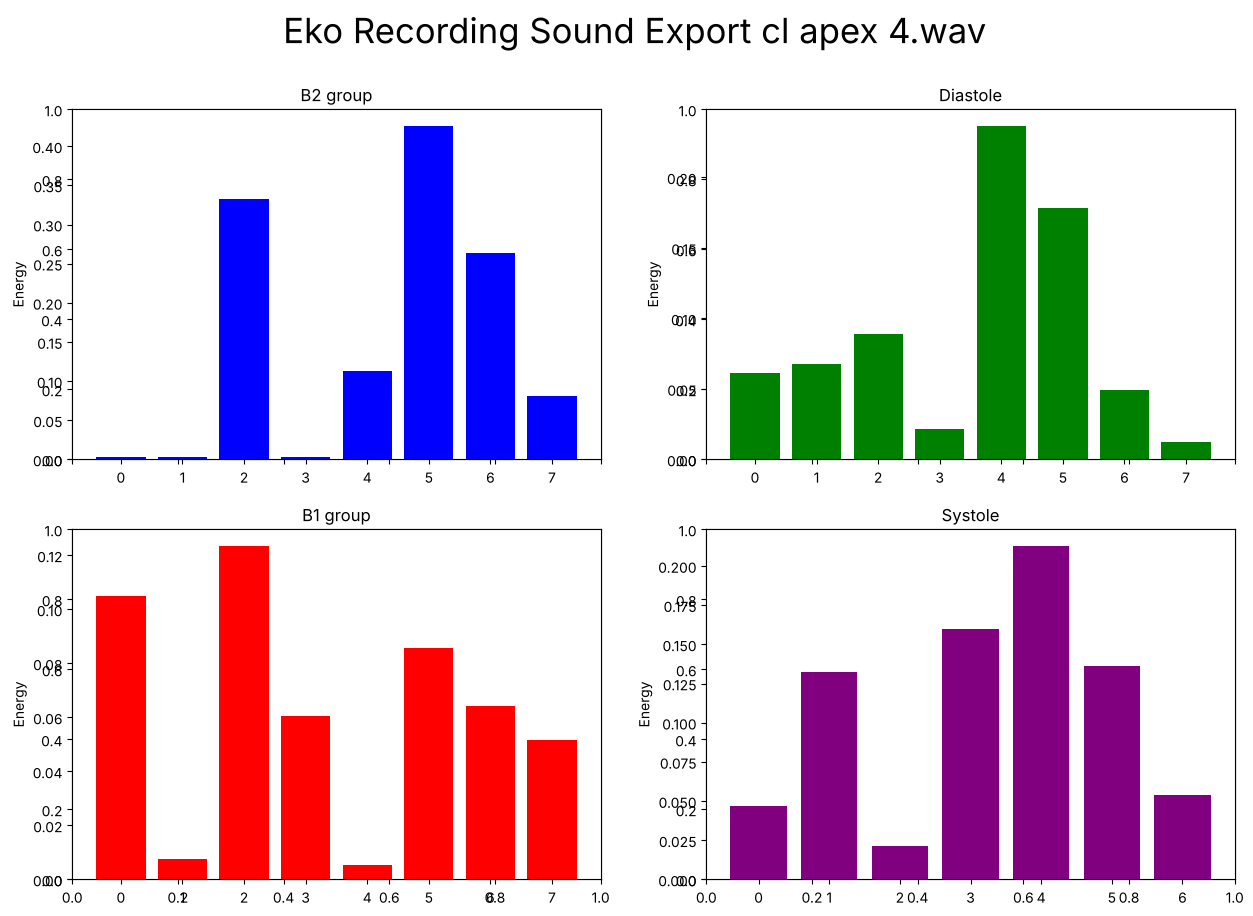

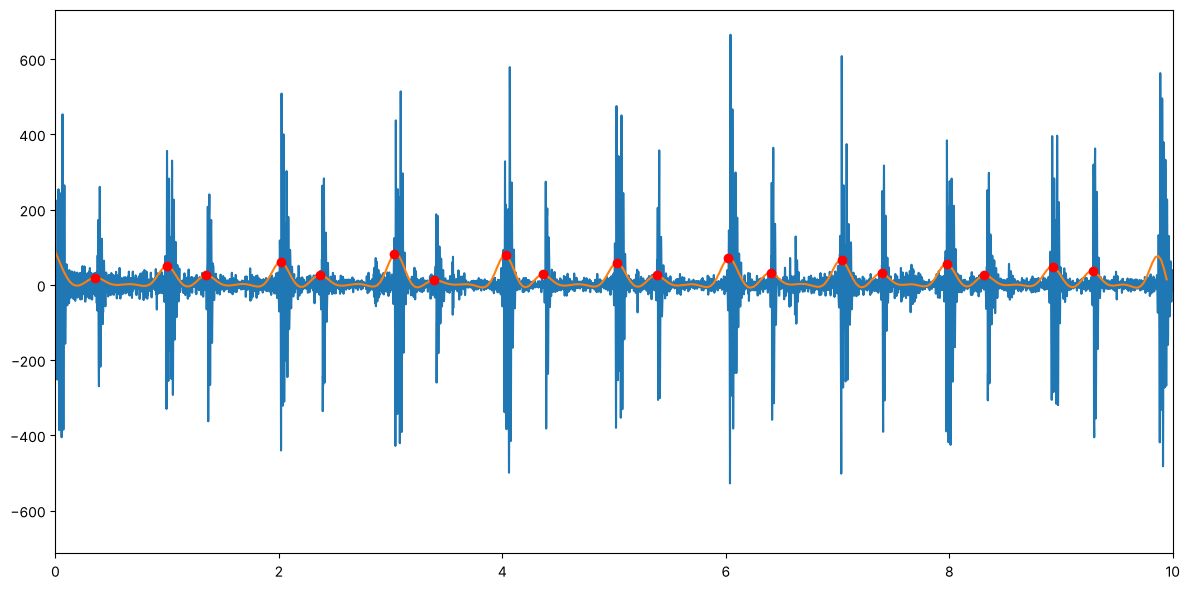

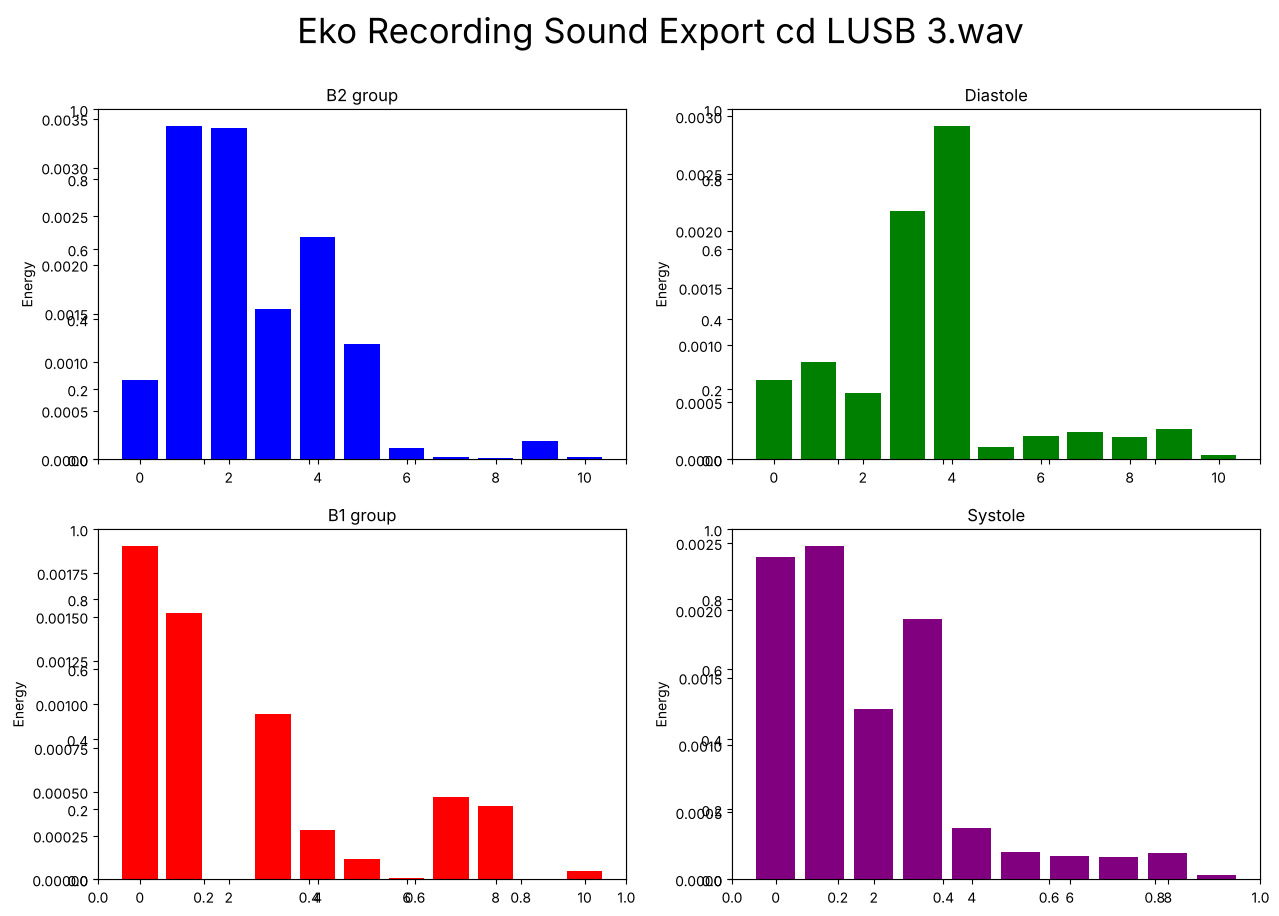

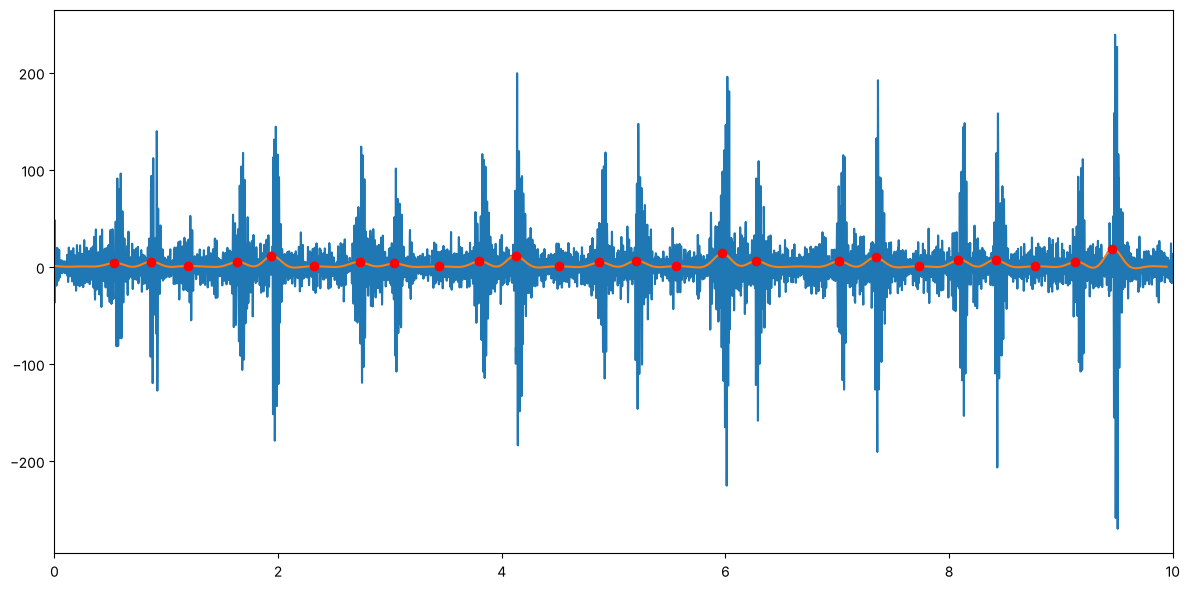

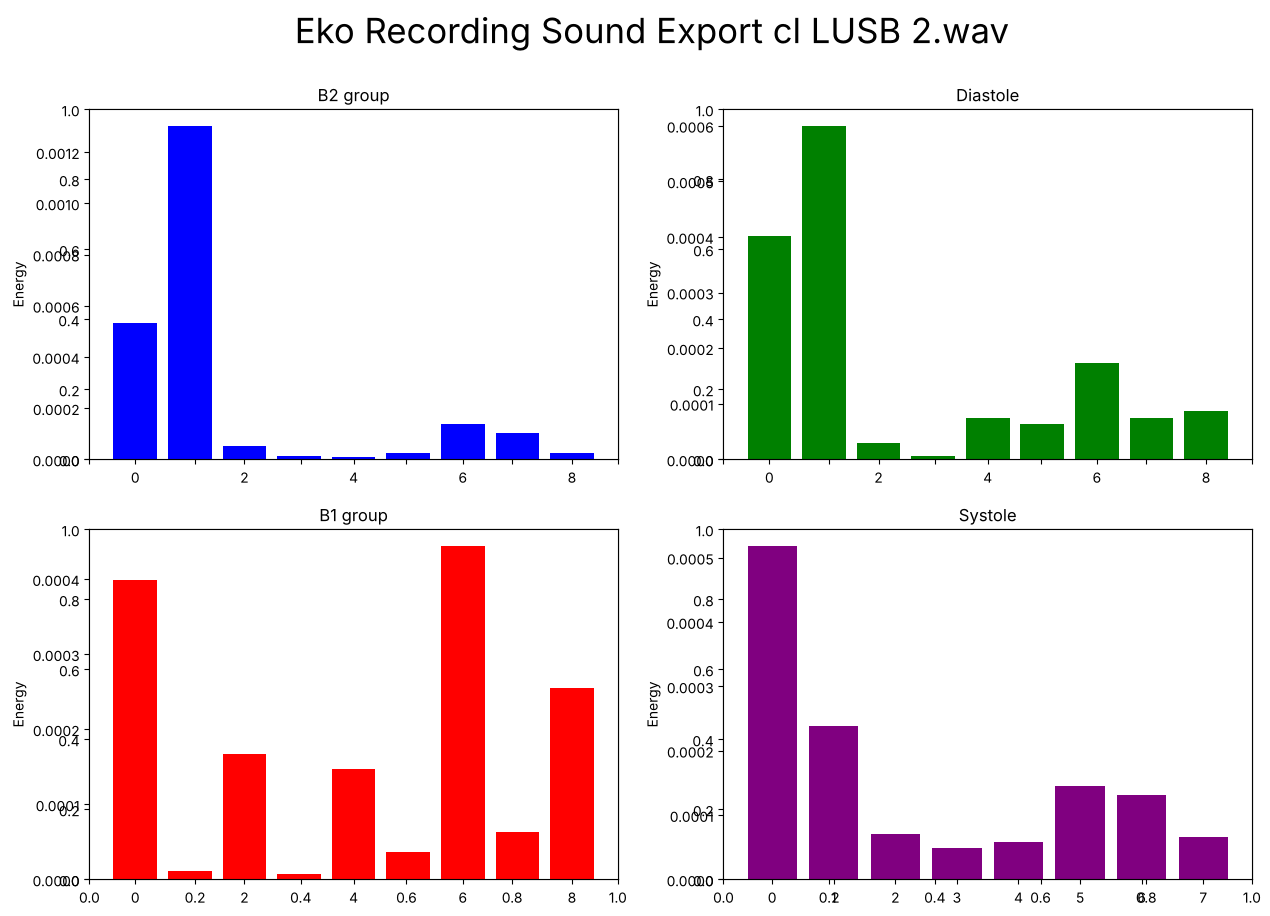

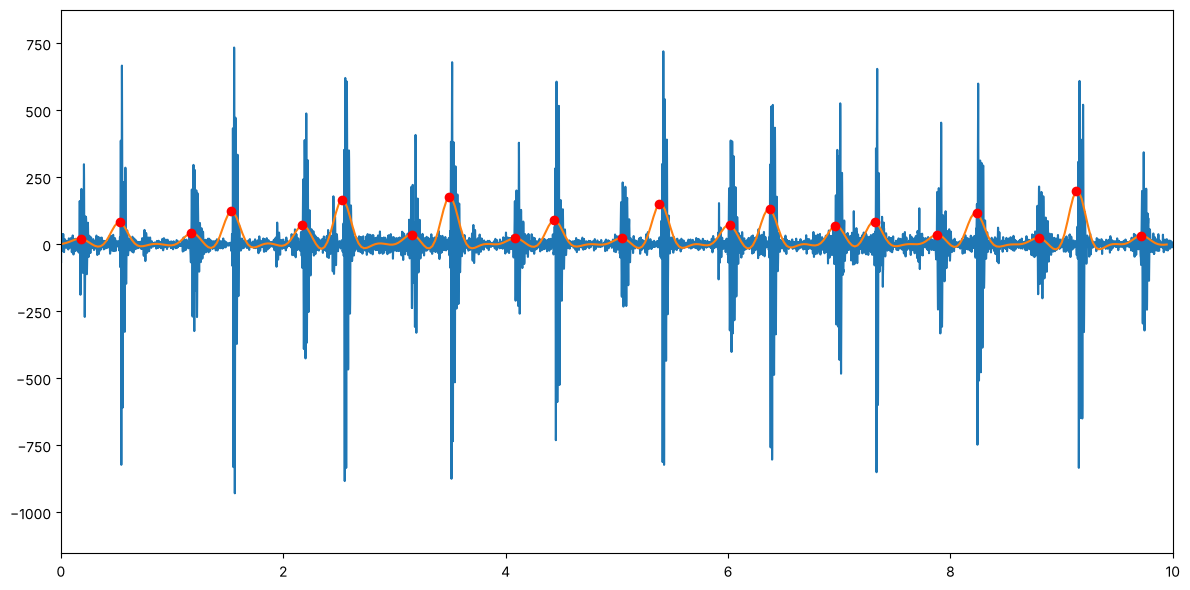

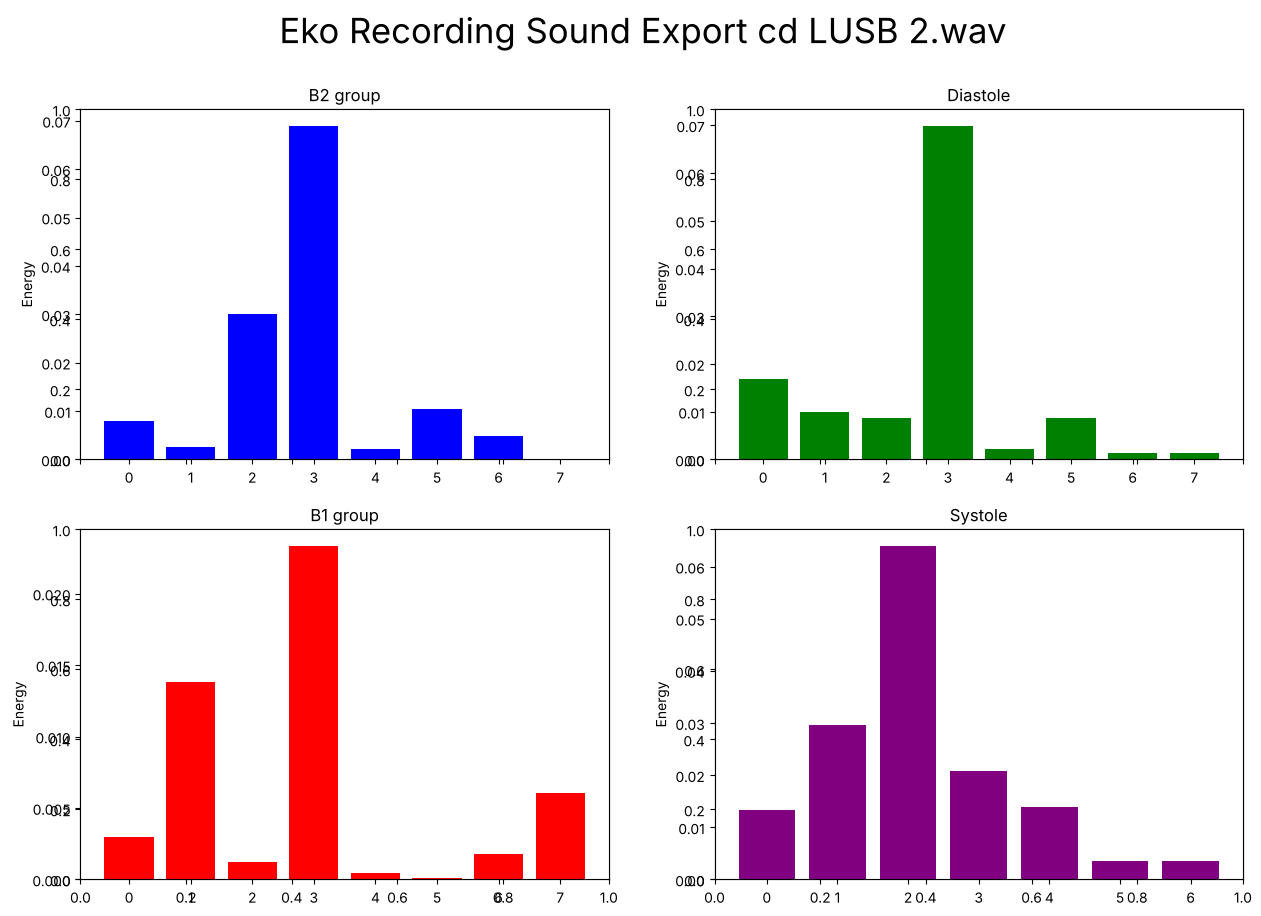

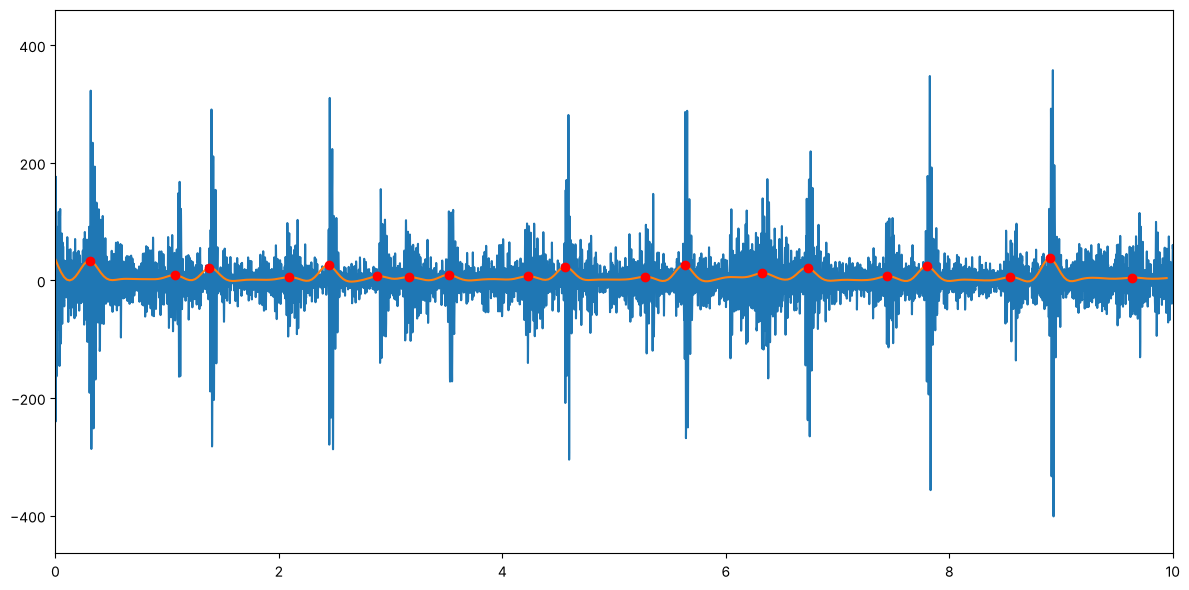

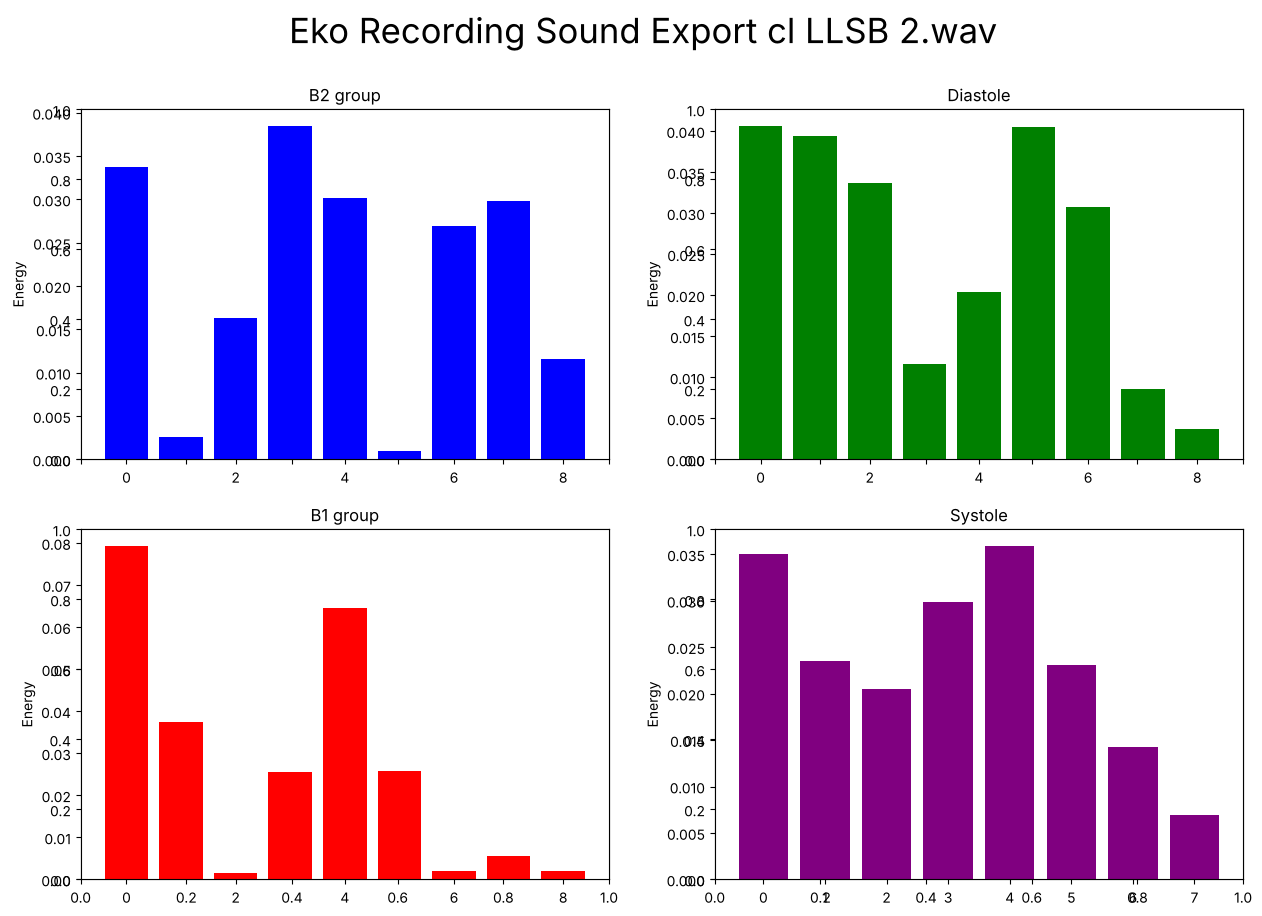

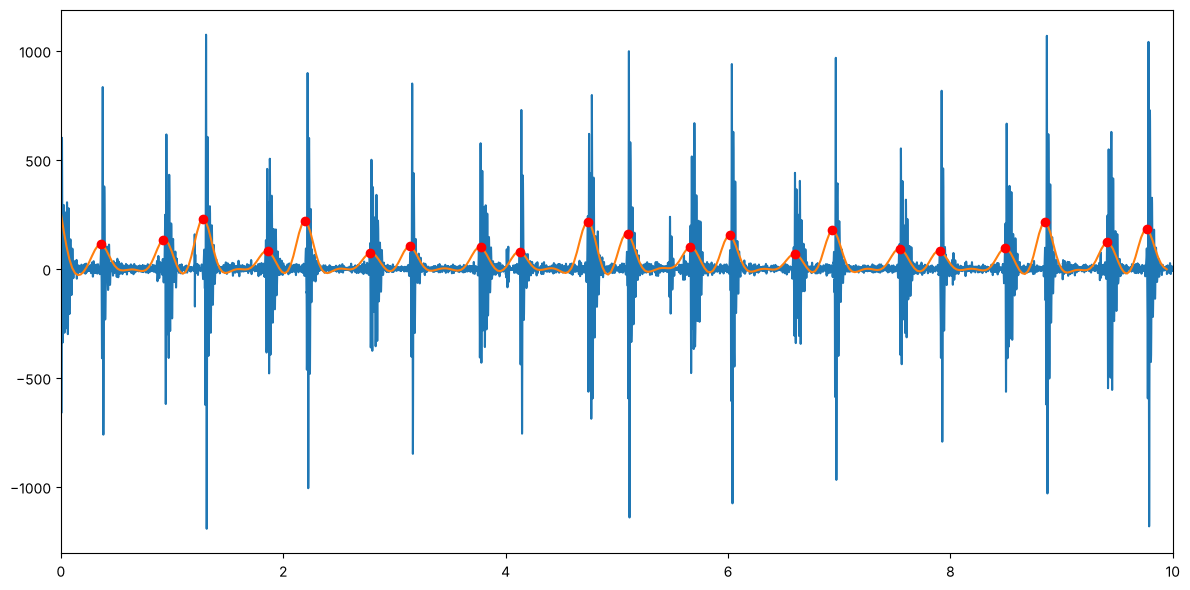

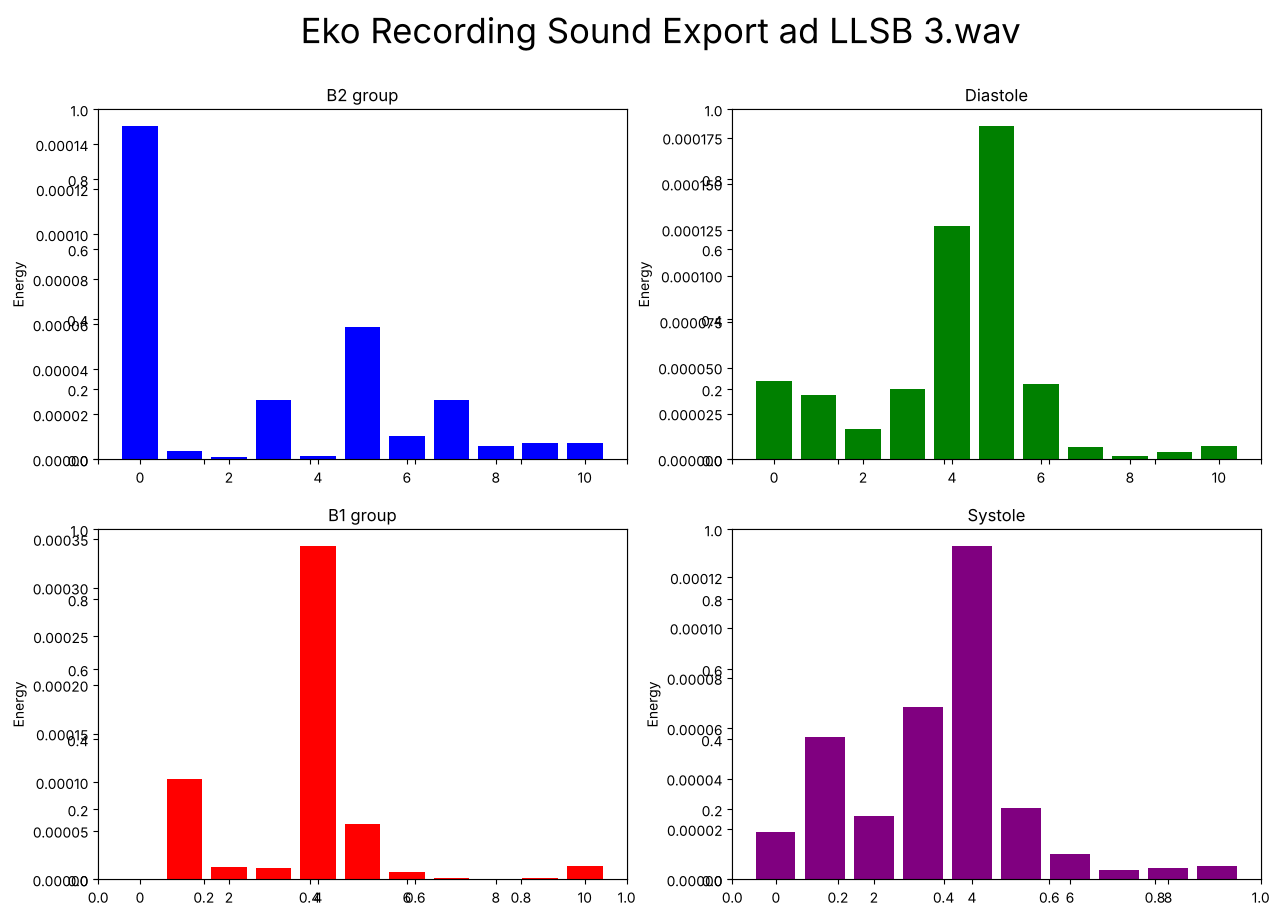

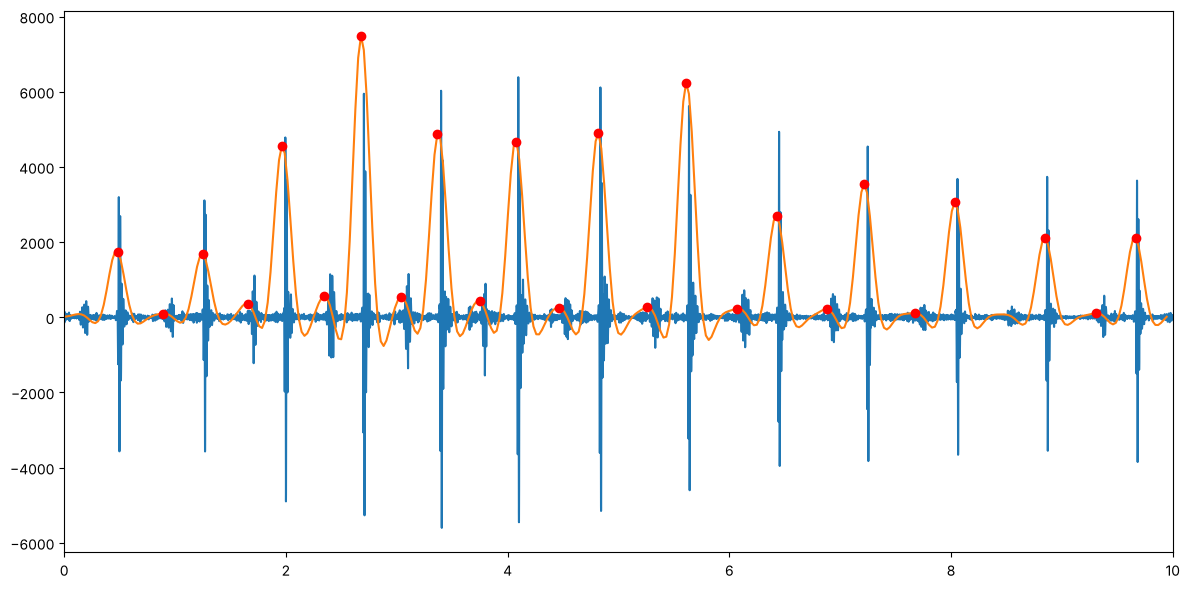

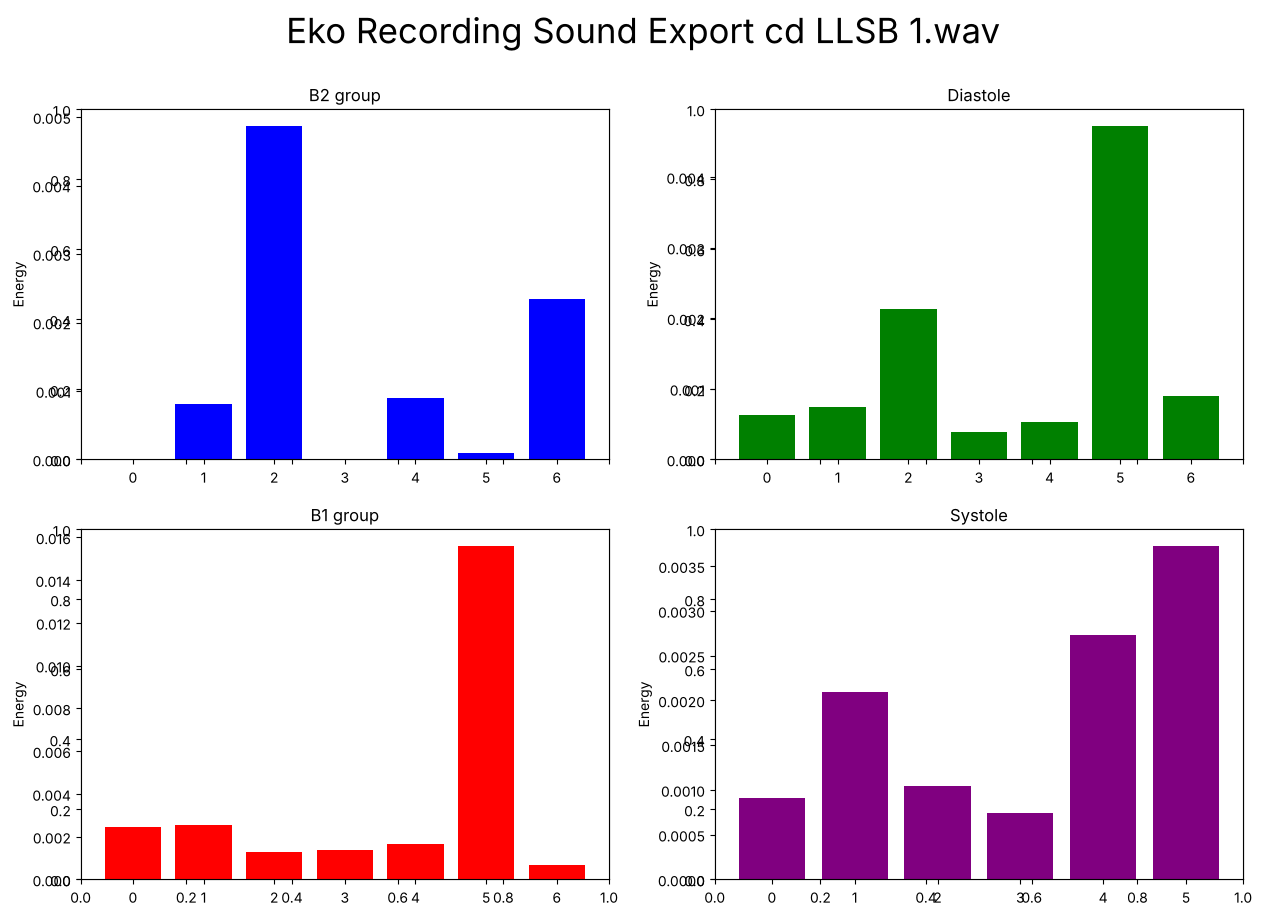

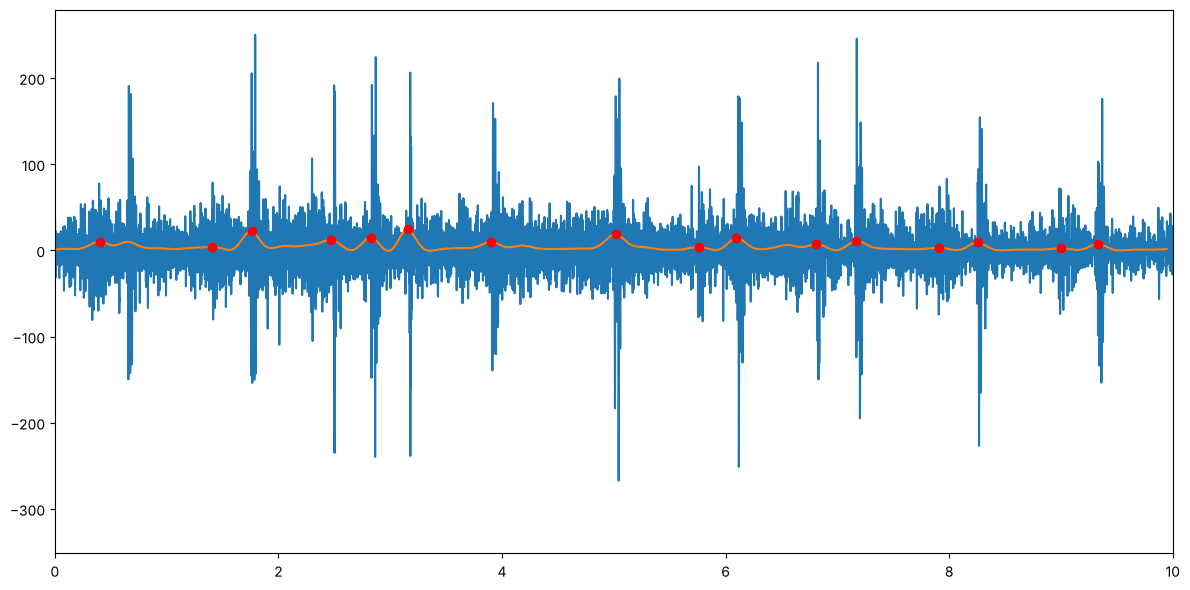

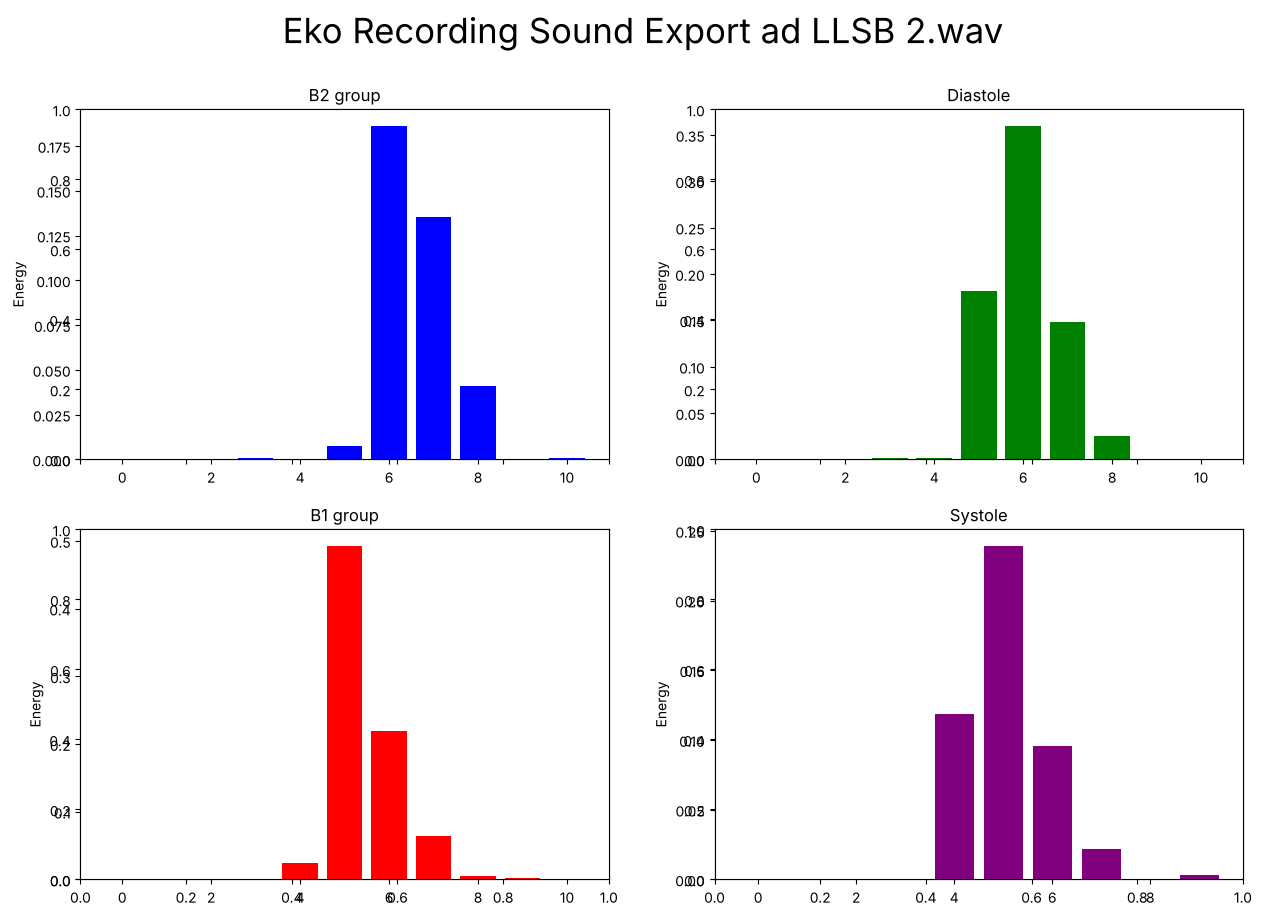

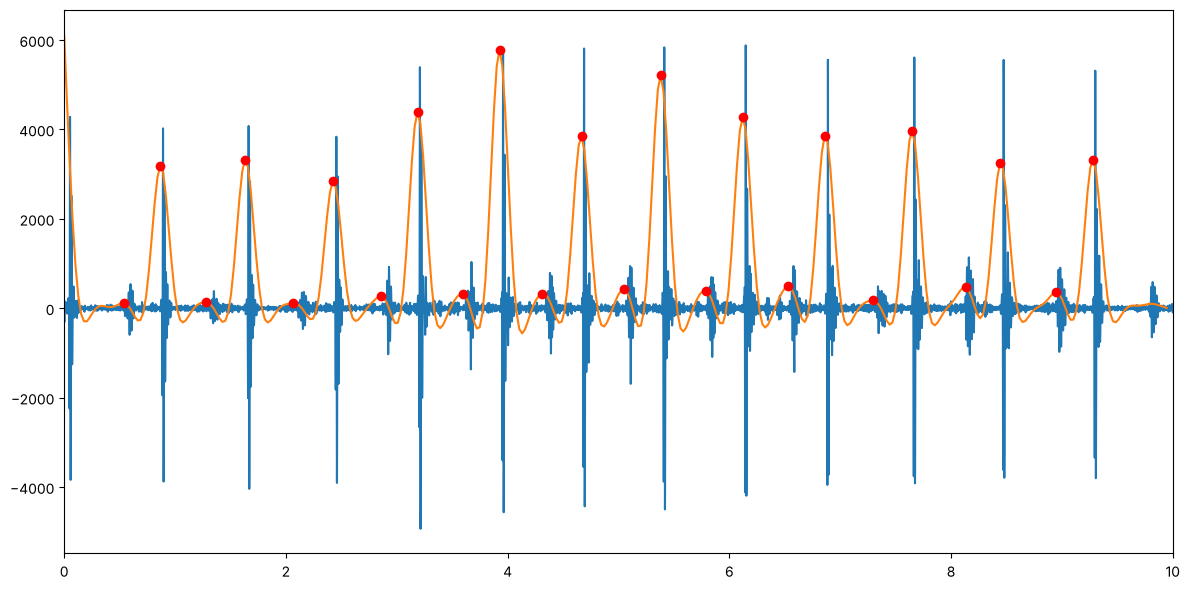

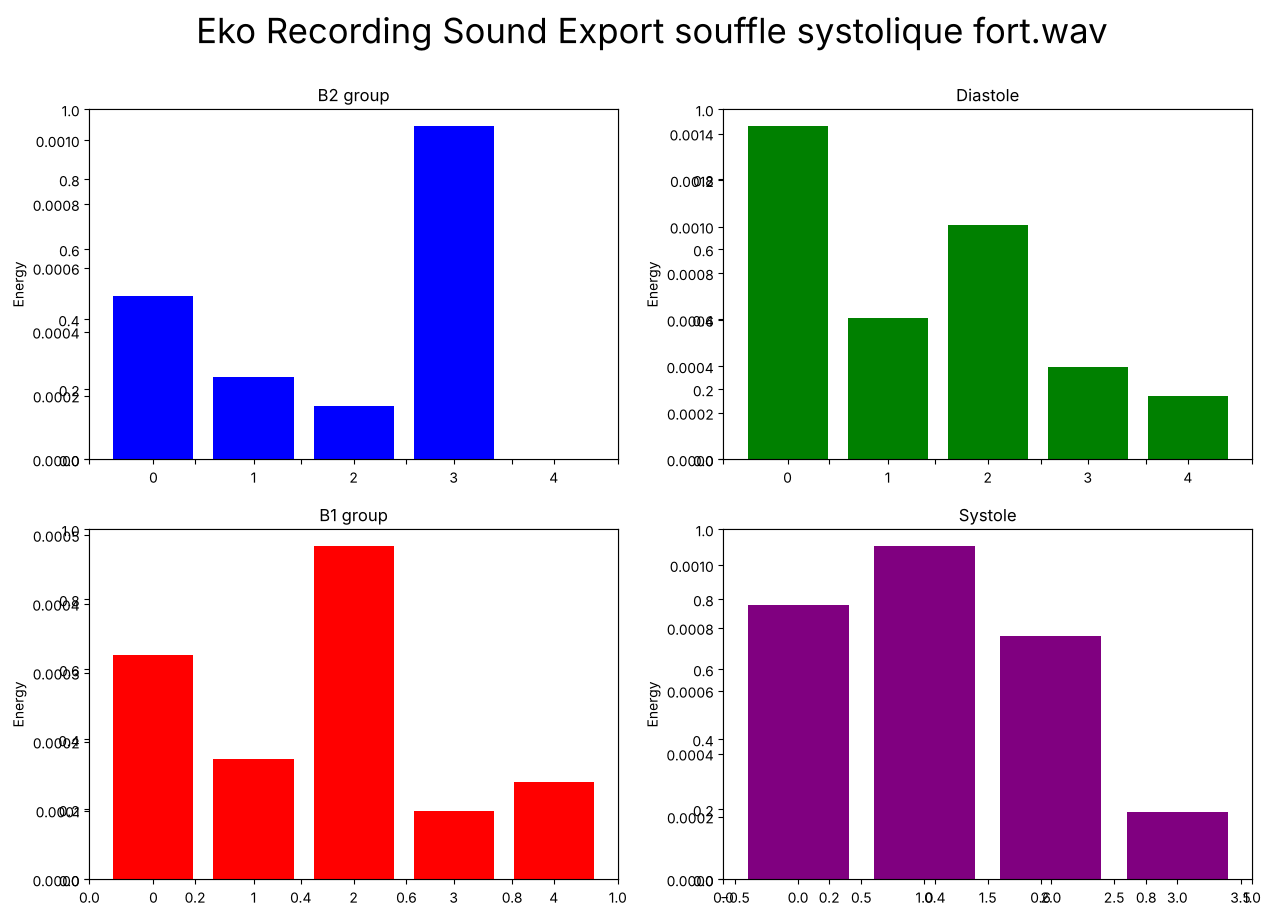

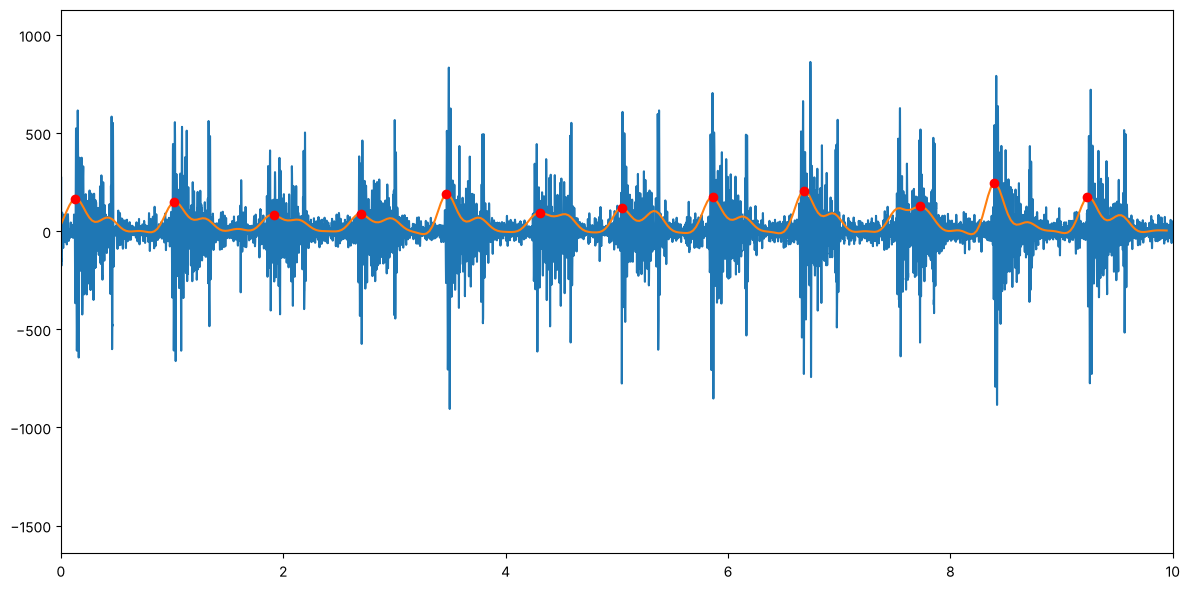

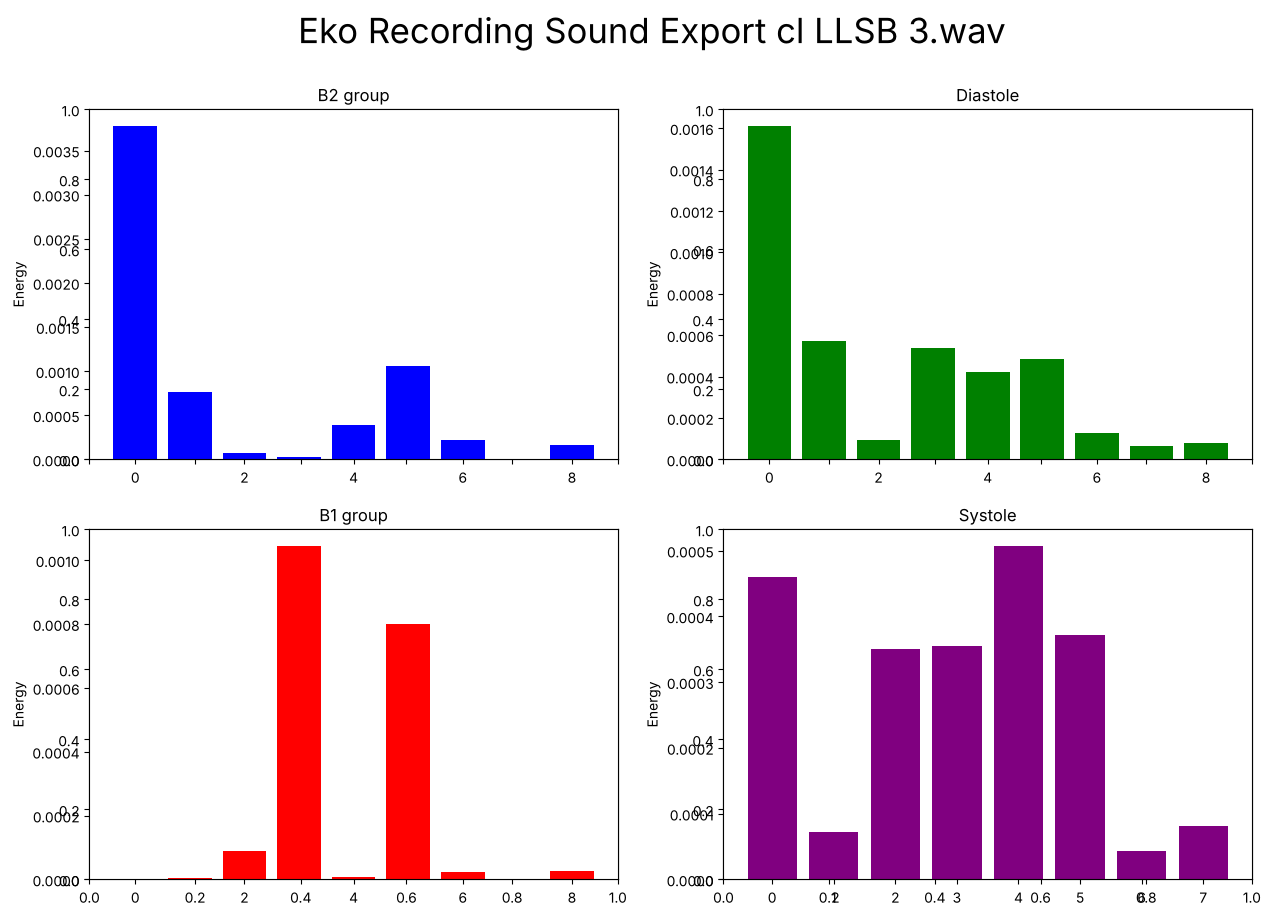

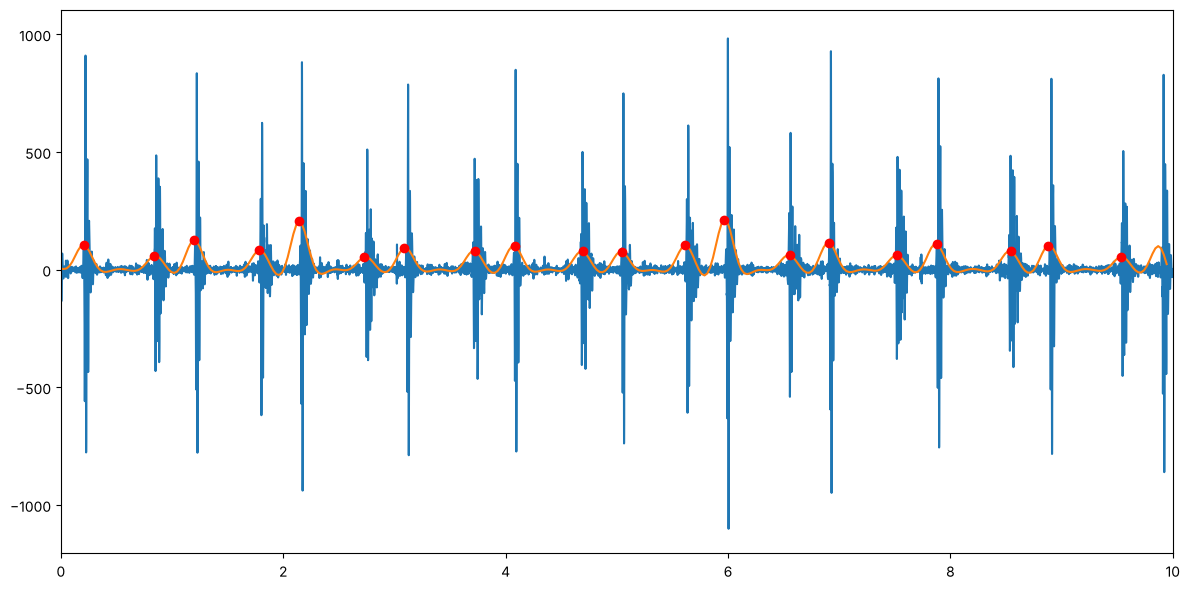

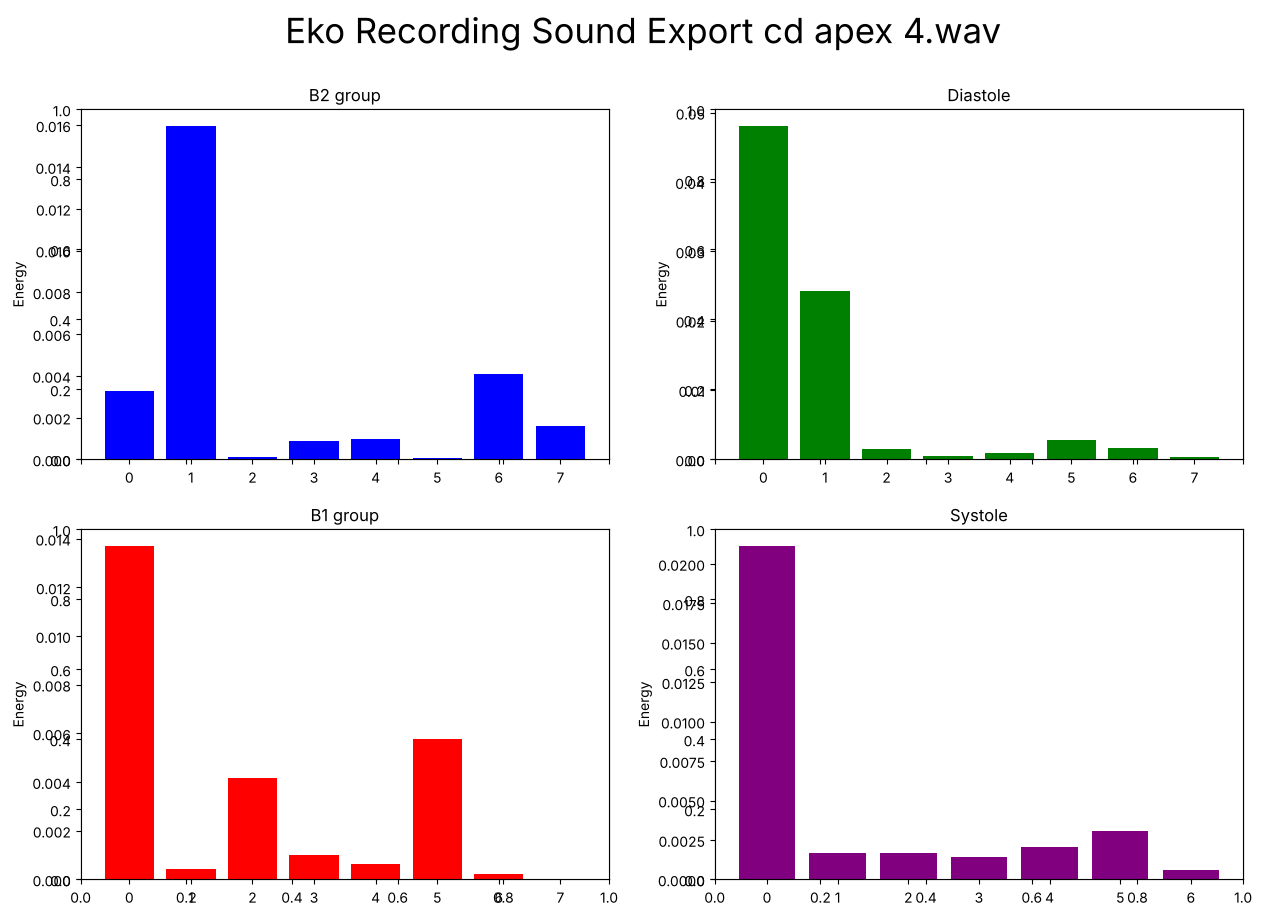

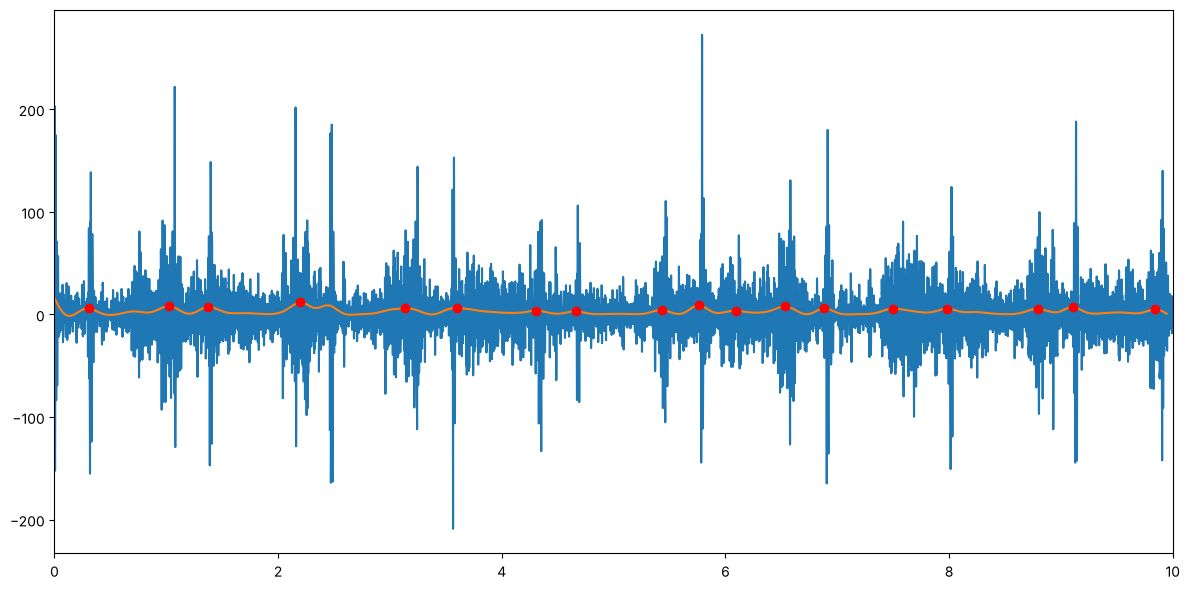

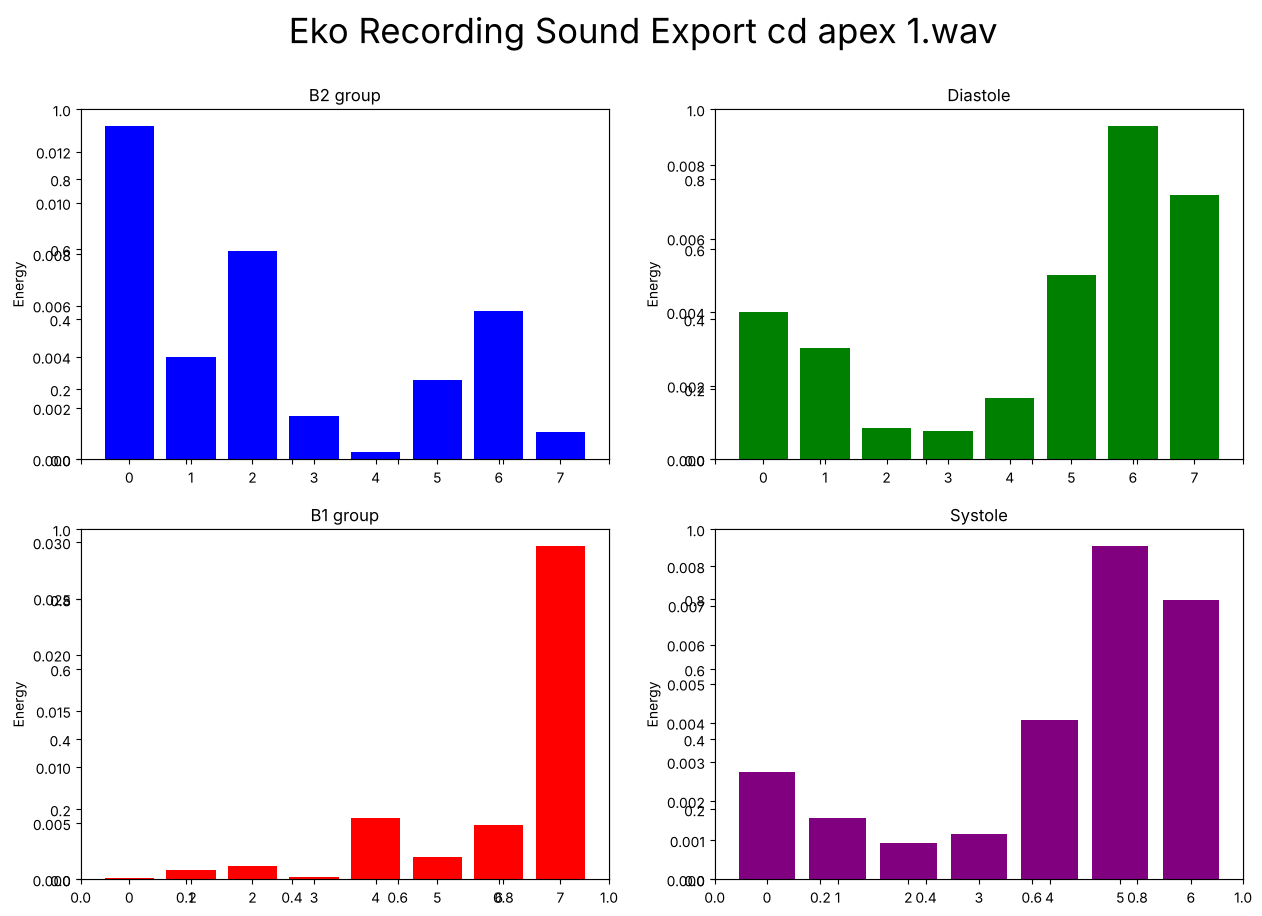

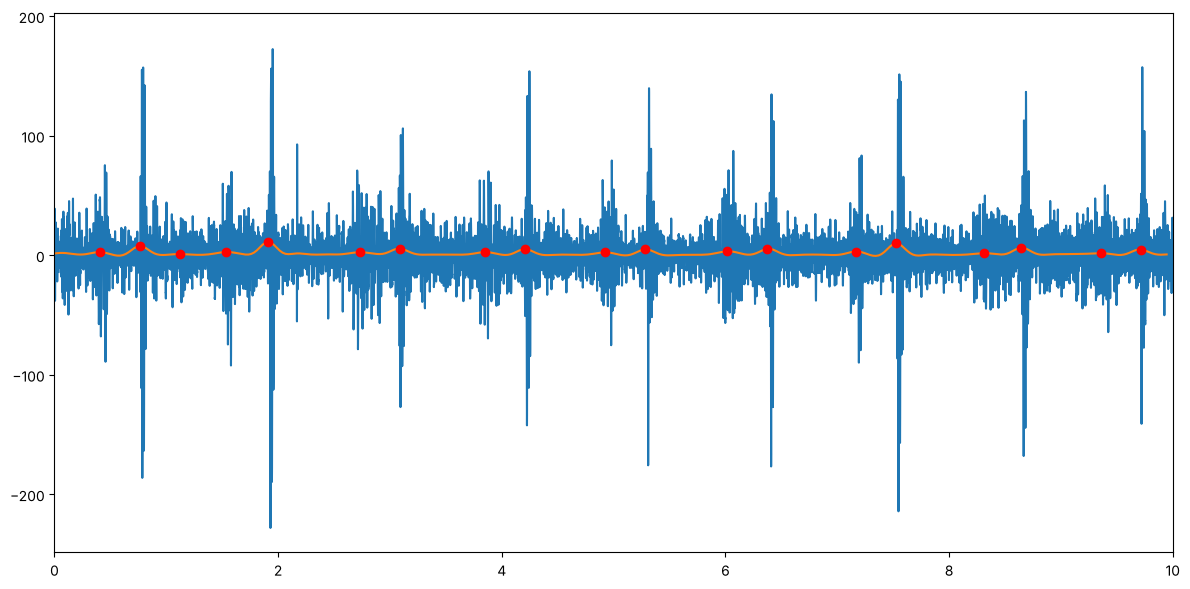

Mean B2 group over all recordings: 0.013197948666720416
Mean diastole over all recordings: 0.011718311669787955
Mean B1 group over all recordings: 0.009326655417034015
Mean systole over all recordings: 0.01195764109597708


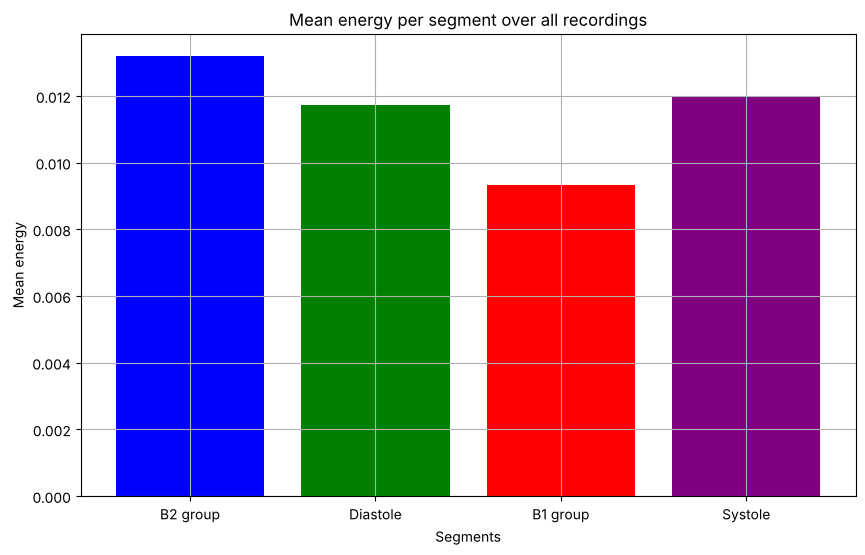

In [13]:
# Directory containing the audio files
directory = "../data/recordings"

# Lists of per-segment means for each recording
recordings_B2 = []
recordings_diastole = []
recordings_B1 = []
recordings_systole = []

# Loop over all files in the directory
for filename in os.listdir(directory):
    if filename.endswith(".wav"):
        # Load the WAV file
        filepath = os.path.join(directory, filename)
        with wave.open(filepath, 'rb') as wave_file:
            # Get the audio file information
            framerate = wave_file.getframerate()
            frames = wave_file.getnframes()
            channels = wave_file.getnchannels()
            width = wave_file.getsampwidth()

            # Read the audio data
            audio_data = wave_file.readframes(frames)

            # Convert the audio data to a NumPy array
            audio_data = np.frombuffer(audio_data, dtype=np.int16)

            # Signal duration in seconds
            duration = frames / float(framerate)

            # Time vector
            time = np.linspace(0, duration, frames)

            # Load the WAV file
            Fs, y = wav.read(filepath)

            # Check whether the audio file is stereo or mono
            if len(y.shape) == 1:  # Mono
                X = y
            elif len(y.shape) == 2:  # Stereo
                X = y[:, 0] - 1j * y[:, 1]  # Combine the channels into a complex signal

            Nmax = len(X)
            TotalDuration = Nmax / Fs

            Overlap = 80 / 100
            Lwind = 512
            Delay = round(Lwind - (Lwind * Overlap))
            ED = 10  # Frame duration
            NObs = int(ED * Fs)
            k = 1
            x = X[(k - 1) * NObs:k * NObs]
            tx = np.linspace(0, ED, len(x))

            # Frequency representation
            X = np.fft.fft(audio_data - np.mean(audio_data))
            Xspec_fp = np.abs(X[:len(X) // 2]) ** 2
            fp = np.linspace(0, framerate / 2, len(Xspec_fp))

            # Normalisation (divide by the maximum absolute value)
            normalized_audio_data = audio_data / np.max(np.abs(audio_data))

            # Butterworth band-pass filter design
            def butter_bandpass(lowcut, highcut, fs, order=5):
                nyquist = 0.5 * fs
                low = lowcut / nyquist
                high = highcut / nyquist
                b, a = butter(order, [low, high], btype='band', analog=False)
                return b, a

            # Apply the Butterworth band-pass filter to the audio signal
            def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
                b, a = butter_bandpass(lowcut, highcut, fs, order=order)
                y = filtfilt(b, a, data)
                return y

            # Band-pass cut-off frequencies
            lowcut_frequency = 50  # Low cut-off frequency (Hz)
            highcut_frequency = 1000  # High cut-off frequency (Hz)

            # Apply the band-pass filter to the audio signal
            filtered_audio_data_bandpass = butter_bandpass_filter(audio_data, lowcut_frequency, highcut_frequency, framerate)
            
            # Normalisation function
            def normalize_signal(signal):
                max_abs_value = np.max(np.abs(signal))
                normalized_signal = signal / max_abs_value
                return normalized_signal

            # Normalise the filtered signal
            normalized_audio_data_bandpass = normalize_signal(filtered_audio_data_bandpass)

            frame_duration = Lwind / Fs

            # Shorter Hamming window
            Lwind = 128  # e.g. reduce the Hamming window length to 128

            # Longer FFT
            NFFT = 2048  # e.g. increase the FFT length to 2048

            # Lower overlap
            Overlap = 50 / 100  # e.g. reduce the overlap to 50 %

            # Plot the per-frame energy with the new settings
            Energy = []

            l = 1

            while (l - 1) * Delay + Lwind < NObs:
                x_wind = filtered_audio_data_bandpass[(l - 1) * Delay:l * Delay + Lwind]
                S = np.abs(np.fft.fft(x_wind, NFFT))
                FrpPos = np.arange(len(S) // 2)
                Energy.append([np.sum((S[FrpPos] * hamming(len(FrpPos))) ** 2) / len(FrpPos)])
                l += 1

            Energy = np.array(Energy)
            Sgl = Energy[:, 0]
            tx = np.linspace(0, frame_duration, len(Sgl))

            # Correct the time axis
            epoch_times = np.arange(len(Sgl)) * (Delay / Fs)

            # Low-pass filter parameters
            order = 3  # Filter order
            cutoff_freq = 0.09  # Filter cut-off frequency (Hz)

            # Design the low-pass filter
            b, a = butter(order, cutoff_freq, fs=1)

            # Low-pass filter the per-frame energy to smooth it
            smoothed_energy = filtfilt(b, a, Sgl)

            # Find all initial peaks to inspect their amplitudes
            initial_peaks, _ = find_peaks(smoothed_energy)

            # If at least two peaks are found
            if len(initial_peaks) > 1:
                # Get the values of the peaks found
                peak_values = smoothed_energy[initial_peaks]
                # Index of the largest peak
                max_peak_index = np.argmax(peak_values)
                # Remove the largest peak to get the second largest
                peak_values = np.delete(peak_values, max_peak_index)
                # Value of the second largest peak
                second_max_peak = np.max(peak_values)
            else:
                # With fewer than two peaks, use the existing maximum to avoid errors
                second_max_peak = np.max(smoothed_energy)

            # Set height as a fraction of the second largest peak
            height_threshold = second_max_peak / 70

            # Set the other parameters adaptively
            distance = len(smoothed_energy) // 50  # This factor can be tuned for the signal
            prominence = (np.percentile(smoothed_energy, 50) - np.percentile(smoothed_energy, 25))  # Use the IQR as an estimate of prominence
            width = 5  # Minimum width (can be tuned)

            # Find peaks with the computed parameters
            peaks, properties = find_peaks(smoothed_energy, distance=distance, height=height_threshold, prominence=prominence, width=width)
            # Indices of the peaks corresponding to the smallest distance
            distances = []

            for i in range(len(peaks) - 1):
                distance_time = epoch_times[peaks[i+1]] - epoch_times[peaks[i]]
                distances.append(distance_time)

            # Add debug prints
            if not distances:
                print(f"No distances found for file: {filename}")
                continue 

            distance_min = min(distances)

            # Handle floating-point precision
            min_distance_index = next((i for i, d in enumerate(distances) if math.isclose(d, distance_min)), None)

            if min_distance_index is None:
                raise ValueError(f"Min distance {distance_min} not found in distances list")
                continue  # Skip to the next file
            peak_B1_index = peaks[min_distance_index]
            peak_B2_index = peaks[min_distance_index + 1]

            # Lists for the B1 and B2 peaks
            peaks_B1 = []
            peaks_B2 = []

            # Iterate over the peak indices
            for i in range(1, len(peaks)):
                if i % 2 == 0:
                    # Even index: add to the B2 list
                    peaks_B2.append(peaks[i])
                else:
                    # Odd index: add to the B1 list
                    peaks_B1.append(peaks[i])

            # Check whether the second peak overall equals the first B1 or B2 peak
            if peaks[1] == peaks_B1[0]:
                peaks_B2.append(peaks[0])
            elif peaks[1] == peaks_B2[0]:
                peaks_B1.append(peaks[0])

            # Sort the B1 and B2 lists in increasing order
            peaks_B1.sort()
            peaks_B2.sort()

            distances_B1 = []

            # Distances between consecutive B1 peaks
            for i in range(len(peaks_B1) - 1):
                distance_B1 = epoch_times[peaks_B1[i+1]] - epoch_times[peaks_B1[i]]
                distances_B1.append(distance_B1)

            # Mean distance
            mean_distance_B1 = sum(distances_B1) / len(distances_B1)

            # 10 % of the mean gives the threshold
            error_margin = int(mean_distance_B1 * 0.10) + 1  # Define the error margin

            # Store the B1 points with error margins
            points_B1 = []
            for peak_B1 in peaks_B1:
                points_B1.extend(range(peak_B1 - error_margin, peak_B1 + error_margin + 1))

            # Store the B2 points with error margins
            points_B2 = []
            for peak_B2 in peaks_B2:
                points_B2.extend(range(peak_B2 - error_margin, peak_B2 + error_margin + 1))

            # Sort and remove duplicates
            points_B1 = sorted(set(points_B1))
            points_B2 = sorted(set(points_B2))

            # Group consecutive indices
            def group_consecutive_indices(indices):
                groups = []
                temp_group = [indices[0]]
                for i in range(1, len(indices)):
                    if indices[i] - indices[i-1] == 1:
                        temp_group.append(indices[i])
                    else:
                        groups.append(temp_group)
                        temp_group = [indices[i]]
                groups.append(temp_group)
                return groups

            # Store the B1 points with margins and the number of positions they cover
            points_B1_groups = group_consecutive_indices(points_B1)
            # Store the B2 points with margins and the number of positions they cover
            points_B2_groups = group_consecutive_indices(points_B2)

            # Initialise the lists of mean values
            B2 = []
            diastole = []
            B1 = []
            systole = []

            # Iterate over the B1 and B2 groups
            for i in range(len(points_B1_groups)):
                # Start and end indices of each B1 and B2 group
                start_B1 = points_B1_groups[i][0]
                end_B1 = points_B1_groups[i][-1]
                start_B2 = points_B2_groups[i][0]
                end_B2 = points_B2_groups[i][-1]

                # Mean of the squared values in each segment
                mean_squared_B2 = np.mean(normalized_audio_data_bandpass[start_B2:end_B2+1] ** 2)
                mean_squared_diastole = np.mean(normalized_audio_data_bandpass[end_B2+1:start_B1] ** 2)
                mean_squared_B1 = np.mean(normalized_audio_data_bandpass[start_B1:end_B1+1] ** 2)

                # Check that this is not the last iteration
                if i != len(points_B1_groups) - 1:
                    mean_squared_systole = np.mean(normalized_audio_data_bandpass[end_B1+1:points_B1_groups[i+1][0]] ** 2)
                else:
                    # For the last iteration, set mean_squared_systole to 0
                    mean_squared_systole = 0

                # Check that the B2 value is non-zero
                if mean_squared_B2 != 0:
                    B2.append(mean_squared_B2)

                # Check that the diastole value is non-zero
                if mean_squared_diastole != 0:
                    diastole.append(mean_squared_diastole)

                # Check that the B1 value is non-zero
                if mean_squared_B1 != 0:
                    B1.append(mean_squared_B1)

                # Check that the systole value is non-zero
                if mean_squared_systole != 0:
                    systole.append(mean_squared_systole)
                
            # Drop the first cycle, which is often erroneous
            del B2[0]
            del diastole[0]
            del B1[0]
            del systole[0]

            # Segment names
            segments = ['B2 group', 'Diastole', 'B1 group', 'Systole']

            # Mean values of each segment
            mean_squared_values = [B2, diastole, B1, systole]

            # Colours of each segment
            colors = ['blue', 'green', 'red', 'purple']

            # Create the figure and subplots
            fig, axs = plt.subplots(2, 2, figsize=(15, 10), sharex=True)

            # File title
            fig.suptitle(filename, fontsize=25)
            
            plt.figure(figsize=(12, 6))
            plt.plot(time, filtered_audio_data_bandpass, label='Band-pass filtered signal')
            plt.xlim([0,10])
            plt.plot(epoch_times, smoothed_energy/1000, label='Smoothed energy per frame')
            plt.plot(epoch_times[peaks], smoothed_energy[peaks]/1000,'ro',  label='PEAKS')

            # Subplots for the segment means
            for i in range(4):
                ax_subplot = fig.add_subplot(2, 2, i+1)  # 2 rows, 2 columns, starting at position 1
                ax_subplot.bar(range(len(mean_squared_values[i])), mean_squared_values[i], color=colors[i])
                ax_subplot.set_ylabel('Energy')
                ax_subplot.set_title(segments[i])

            # Plot the segment means for all recordings
            plt.tight_layout()
            plt.show()
            
            # Store the mean values of each segment for each recording
            recordings_B2.append(np.mean(B2))
            recordings_diastole.append(np.mean(diastole))
            recordings_B1.append(np.mean(B1))
            recordings_systole.append(np.mean(systole))

# Mean of each segment over all recordings
mean_B2 = np.mean(recordings_B2)
mean_diastole = np.mean(recordings_diastole)
mean_B1 = np.mean(recordings_B1)
mean_systole = np.mean(recordings_systole)

# Plot the segment means for all recordings
print("Mean B2 group over all recordings:", mean_B2)
print("Mean diastole over all recordings:", mean_diastole)
print("Mean B1 group over all recordings:", mean_B1)
print("Mean systole over all recordings:", mean_systole)

# Plots of the mean of each segment over all recordings
segments = ['B2 group', 'Diastole', 'B1 group', 'Systole']
mean_values = [mean_B2, mean_diastole, mean_B1, mean_systole]

plt.figure(figsize=(10, 6))
plt.bar(segments, mean_values, color=['blue', 'green', 'red', 'purple'])
plt.xlabel('Segments')
plt.ylabel('Mean energy')
plt.title('Mean energy per segment over all recordings')
plt.grid(True)
plt.show()


Mean energy of each phase, per recording and over all recordings.

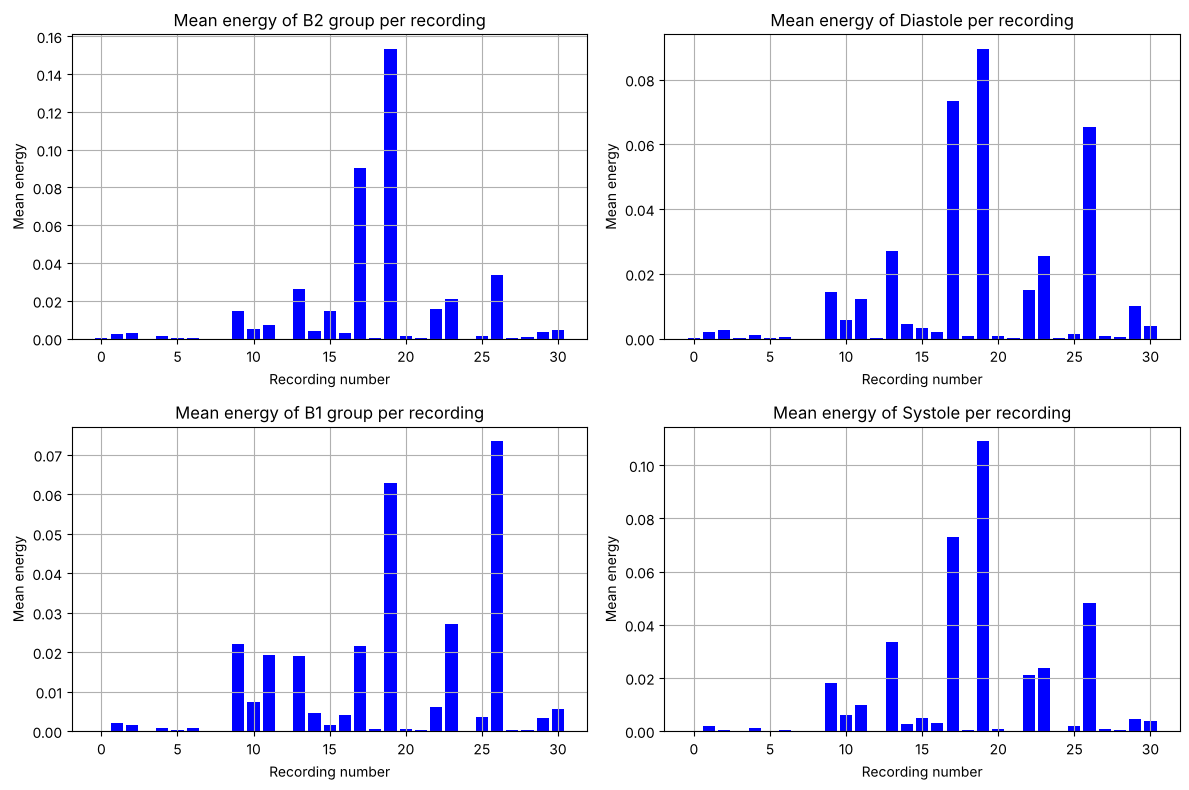

In [14]:
# Plots of the mean of each segment for each recording
segments = ['B2 group', 'Diastole', 'B1 group', 'Systole']
mean_values = [recordings_B2, recordings_diastole, recordings_B1, recordings_systole]

plt.figure(figsize=(12, 8))

for i in range(len(segments)):
    plt.subplot(2, 2, i+1)
    plt.bar(range(len(mean_values[i])), mean_values[i], color='b')
    plt.xlabel('Recording number')
    plt.ylabel('Mean energy')
    plt.title('Mean energy of {} per recording'.format(segments[i]))
    plt.grid(True)

plt.tight_layout()
plt.show()
